In [1]:
# #@@@ md
# # Study 1 — Hourglass ở 4 họ mô hình (M1–M4, $J_k$, random-init) — bản đầy đủ

# Theo Algorithm 1 của *"Principle of Least Effort in Depth"* và kế hoạch chạy LE-D.

# **Phạm vi.** 15 mô hình mở (3 encoder + ByT5 mức byte, 6 dense decoder, 3 MoE, 2 diffusion), dữ liệu **FLORES-200 devtest** (12 ngôn ngữ) và **NTREX-128** (lặp lại ở một tập con mô hình), cùng random-init control cho từng kiểu kiến trúc.

# **Số đo tính cho mỗi (model, layer, cặp ngôn ngữ):** $D_k$, $G_k$ (M1), CKA không chệch và Procrustes-CV $A_k$ (M2), MRR truy hồi CSLS $R_k$ (M3), usable information $U_k$ (M4, probe tuyến tính), và $J_k$ (JS routing so với English) cho MoE.

# **Cấu trúc notebook**

# | Phần | Nội dung | Cần GPU |
# |---|---|---|
# | A | config, registry model, load/xử lý FLORES + NTREX | không |
# | B | trích xuất biểu diễn + tính số đo | có |
# | C | chạy thí nghiệm (có resume), bảng trạng thái | có |
# | D | bootstrap CI, bảng đặc trưng waist, vẽ hình PDF (chỉ đọc `/mnt/cl`) | không |

# **Lưu trữ (`/mnt/cl`)**
# ```
# /mnt/cl/data/raw/ntrex128/*.txt                  # file thô NTREX
# /mnt/cl/data/processed/parallel/{flores,ntrex}.jsonl   # {id, lang, text}, NFKC
# /mnt/cl/study1/{dataset}/{run_id}/{variant}.npz  # số đo chi tiết (per pair, per layer, per content)
# /mnt/cl/study1/{dataset}/{run_id}/meta.json      # cấu hình, thống kê, trạng thái
# /mnt/cl/study1/analysis/*.csv|json               # bảng tổng hợp
# /mnt/cl/study1/figures/*.pdf                     # hình
# ```
# `run_id` = `key` (pretrained) hoặc `key__random` (random-init). `variant` = `base` (mọi họ trừ diffusion) hoặc `t{mức che}_{all|masked}` (diffusion).

# **Chạy lại / resume.** Mỗi (dataset, model, variant) đã có file `.npz` sẽ được bỏ qua. Chỉ chạy một số model: đặt `RUN_MODELS`. Chạy lại từ đầu: `FORCE_RERUN = True`. Sau khi chạy xong, ở kernel mới chỉ cần chạy phần A (cell config + registry) và phần D để vẽ lại hình.

# **Gợi ý thứ tự (cổng G1):** `RUN_MODELS = ["xlmr_base", "qwen3_1.7b", "olmoe"]` rồi `run_all(["flores"])` trước khi chạy cả 15 model.

# #@@@ code
%uv pip install --no-cache-dir --force-reinstall \
    torch==2.8.0 torchvision==0.23.0 torchaudio==2.8.0 \
    transformers==4.57.1 \
    datasets==4.0.0 \
    huggingface_hub==0.36.0 \
    accelerate sentencepiece protobuf safetensors \
    numpy matplotlib pandas
# (tuỳ chọn) Times New Roman không có sẵn trên nhiều máy Linux; Liberation Serif tương thích số đo với nó.
# Bỏ comment dòng dưới nếu cần, rồi restart kernel:
!apt-get -qq install -y fonts-liberation

#@@@ code

Using Python 3.12.6 environment at: /usr/local
Resolved 69 packages in 531ms
⠙ Preparing packages... (0/69)
⠙ Preparing packages... (0/69)
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
fonttools  ------------------------------     0 B/5.15 MiB
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
fonttools  ------------------------------ 14.78 KiB/5.15 MiB
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
hf-xet     ------------------------------     0 B/4.02 MiB
fonttools  ------------------------------ 14.78 KiB/5.15 MiB
⠙ Preparing packages... (0/69)
safetensors ------------------------------ 14.80 KiB/503.95 KiB
hf-xet     ------------------------------ 14.76 KiB

In [ ]:
# ============================================================
# Cell A1 — Config & đường dẫn lưu trữ
# ============================================================
import os, gc, json, time, math, re, itertools, unicodedata, urllib.request, urllib.error, warnings
from datetime import datetime
import numpy as np

from huggingface_hub import login
HF_TOKEN = os.environ.get("HF_TOKEN", "MY_KEY")      # hoặc dán token trực tiếp ở đây
if HF_TOKEN and HF_TOKEN != "MY_KEY":
    login(token=HF_TOKEN)


# ---- Storage: mọi kết quả nằm dưới /mnt/cl ----
ROOT         = os.getcwd()
DATA_DIR     = f"{ROOT}/data"
STUDY_DIR    = f"{ROOT}/study1"
FIG_DIR      = f"{STUDY_DIR}/figures"
ANALYSIS_DIR = f"{STUDY_DIR}/analysis"
HF_CACHE_DIR = None            # vd. f"{ROOT}/hf_cache" nếu ổ home không đủ chỗ cho ~150GB trọng số
for _d in (f"{DATA_DIR}/raw/ntrex128", f"{DATA_DIR}/processed/parallel", STUDY_DIR, FIG_DIR, ANALYSIS_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- Siêu tham số thí nghiệm ----
SEED         = 42
N_SENT       = None      # None = dùng toàn bộ (FLORES devtest 1012, NTREX 1997). Đặt 200 để test nhanh
                         # (kết quả test được lưu ở thư mục riêng *_n200, không lẫn với kết quả thật)
N_SHUFFLES   = 1000      # shuffled-pair baseline (Eq. 18)
N_BOOT       = 1000      # bootstrap theo content (95% CI)
CSLS_K       = 10        # số láng giềng cho hubness correction của CSLS
D_PCA        = 64        # số chiều PCA trước khi khớp phép xoay Procrustes (fit nửa này, chấm nửa kia)
PROBE_SEEDS  = 3         # số cách chia content train/test cho probe M4
MASK_LEVELS  = [0.0, 0.25, 0.5, 0.75]   # diffusion: tỉ lệ token bị che
N_MASK_DRAWS = 8                         # số lần che ngẫu nhiên / câu / mức che (>0)

# ---- Điều khiển chạy ----
DATASETS_TO_RUN      = ["flores", "ntrex"]
RUN_MODELS           = None     # None = cả 15 model; hoặc list key, vd. ["xlmr_base", "qwen3_1.7b", "olmoe"]
NTREX_MODEL_KEYS     = ["xlmr_base", "qwen3_1.7b", "olmoe", "llada_8b"]   # NTREX lặp ở 3 mô hình đại diện + 2 diffusion. None = tất cả
RUN_RANDOM_BASELINES = True
FORCE_RERUN          = False
SANITY_CHECK         = True     # kiểm tra batch-vs-single (padding) 1 lần cho mỗi model

# 12 ngôn ngữ của Study 1 (Table 8 / kế hoạch). Tiếng Anh đứng đầu (dùng cho J_k).
LANGS = ["eng_Latn", "fra_Latn", "rus_Cyrl", "hin_Deva", "zho_Hans", "vie_Latn",
         "tur_Latn", "arb_Arab", "jpn_Jpan", "fin_Latn", "swh_Latn", "tha_Thai"]

def ds_tag(ds):
    return ds if N_SENT is None else f"{ds}_n{N_SENT}"

In [3]:
#@@@ code
# ============================================================
# Cell A2 — Registry 15 model + random-init baseline theo kiến trúc
# [XM] tên model trên HF cần xác minh trước khi chạy
# ============================================================
PALETTE = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#e377c2", "#17becf",
           "#bcbd22", "#393b79", "#e6550d", "#31a354", "#756bb1", "#843c39", "#00868b", "#b8860b"]

def _m(key, hf_id, family, label, loader="auto", trc=False, final_norm=None,
       router=False, max_len=512, bs=16, mask_id=None):
    # loader: auto=AutoModel | causal=AutoModelForCausalLM | t5enc=T5EncoderModel
    # final_norm: đường dẫn tới norm cuối (để lấy residual TRƯỚC final norm ở tầng cuối); None nếu không có
    return dict(key=key, id=hf_id, family=family, label=label, loader=loader, trc=trc,
                final_norm=final_norm, router=router, max_len=max_len, bs=bs, mask_id=mask_id)

MODELS = {m["key"]: m for m in [
    # --- encoder (3) + byte-level (1): cùng vẽ trong nhóm "encoder" ---
    _m("mbert",      "bert-base-multilingual-cased", "encoder", "mBERT"),
    _m("xlmr_base",  "FacebookAI/xlm-roberta-base",  "encoder", "XLM-R base"),
    _m("xlmr_large", "FacebookAI/xlm-roberta-large", "encoder", "XLM-R large"),
    _m("byt5_base_enc", "google/byt5-base",          "encoder", "ByT5-base enc (byte)",
       loader="t5enc", final_norm="encoder.final_layer_norm", max_len=1024, bs=8),
    # --- dense decoder (6) ---
    _m("qwen3_0.6b", "Qwen/Qwen3-0.6B-Base", "decoder", "Qwen3-0.6B", final_norm="norm", bs=32),
    _m("qwen3_1.7b", "Qwen/Qwen3-1.7B-Base", "decoder", "Qwen3-1.7B", final_norm="norm", bs=32),
    _m("qwen3_4b",   "Qwen/Qwen3-4B-Base",   "decoder", "Qwen3-4B",   final_norm="norm"),
    _m("qwen3_8b",   "Qwen/Qwen3-8B-Base",   "decoder", "Qwen3-8B",   final_norm="norm"),
    _m("bloom_560m", "bigscience/bloom-560m", "decoder", "BLOOM-560M", final_norm="ln_f", bs=32),
    _m("bloom_1b7",  "bigscience/bloom-1b7",  "decoder", "BLOOM-1.7B", final_norm="ln_f", bs=32),
    # --- MoE (3): router được hook trực tiếp tại gate (layers.N.mlp.gate) ---
    _m("olmoe",      "allenai/OLMoE-1B-7B-0924", "moe", "OLMoE-1B-7B",      final_norm="norm", router=True),
    _m("qwen15_moe", "Qwen/Qwen1.5-MoE-A2.7B",   "moe", "Qwen1.5-MoE-A2.7B", final_norm="norm", router=True),
    _m("dsv2_lite",  "deepseek-ai/DeepSeek-V2-Lite", "moe", "DeepSeek-V2-Lite", final_norm="norm", router=True),
    # --- diffusion (2): LLaDA là AutoModelForCausalLM (remote code), Dream là AutoModel (remote code) ---
    _m("llada_8b", "GSAI-ML/LLaDA-8B-Base", "diffusion", "LLaDA-8B", loader="causal", trc=True,
       final_norm="model.transformer.ln_f", mask_id=126336),
    _m("dream_7b", "Dream-org/Dream-v0-Base-7B", "diffusion", "Dream-7B", trc=True,
       final_norm="model.norm", mask_id=None),     # mask_id=None -> lấy tok.mask_token_id
]}

FAMILIES    = ["encoder", "decoder", "moe", "diffusion"]
FAMILY_FILE = {"encoder": "encoder", "decoder": "decoder_llm", "moe": "moe", "diffusion": "diffusion"}
MODEL_COLOR = {k: PALETTE[i] for i, k in enumerate(MODELS)}

# random-init control: mỗi kiểu kiến trúc một model (trọng số ~ N(0, 0.02^2), tokenizer giữ nguyên)
RANDOM_BASELINE = {"encoder": "xlmr_base", "decoder": "qwen3_1.7b", "moe": "olmoe", "diffusion": "llada_8b"}

def variant_name(t, pool):
    return "base" if t is None else f"t{t:.2f}_{pool}"

def main_variant(key, random_init=False):
    return "base" if MODELS[key]["family"] != "diffusion" else variant_name(0.0, "all")

def plan_levels(cfg, random_init=False):
    """[(mức che t hoặc None, [tên variant tạo ra từ cùng một lượt forward])]"""
    if cfg["family"] != "diffusion":
        return [(None, ["base"])]
    levels = [0.0] if random_init else MASK_LEVELS
    return [(t, [variant_name(t, "all")] + ([variant_name(t, "masked")] if t > 0 else [])) for t in levels]

print(f"{len(MODELS)} models:", {f: sum(c['family'] == f for c in MODELS.values()) for f in FAMILIES})

15 models: {'encoder': 4, 'decoder': 6, 'moe': 3, 'diffusion': 2}


In [4]:
#@@@ code
# ============================================================
# Cell A3 — Dữ liệu song song: FLORES-200 devtest + NTREX-128
# Cả hai được chuẩn hoá NFKC, căn hàng theo content, lưu jsonl {id, lang, text} vào /mnt/cl/data
# ============================================================
def norm_text(s):
    return unicodedata.normalize("NFKC", s).strip()

def clean_parallel(raw):
    """raw: {lang: [text,...]} cùng độ dài. NFKC + bỏ các content mà BẤT KỲ ngôn ngữ nào rỗng."""
    lens = {l: len(v) for l, v in raw.items()}
    if len(set(lens.values())) != 1:
        raise ValueError(f"Số câu không khớp giữa các ngôn ngữ: {lens}")
    n = next(iter(lens.values()))
    normed = {l: [norm_text(x) for x in v] for l, v in raw.items()}
    keep = [i for i in range(n) if all(normed[l][i] for l in normed)]
    if len(keep) < n:
        print(f"  [clean] bỏ {n - len(keep)} content có câu rỗng ở ít nhất một ngôn ngữ")
    return {l: [normed[l][i] for i in keep] for l in normed}, keep

def write_jsonl(path, clean, ids):
    with open(path, "w", encoding="utf-8") as f:
        for l, sents in clean.items():
            for i, s in zip(ids, sents):
                f.write(json.dumps({"id": int(i), "lang": l, "text": s}, ensure_ascii=False) + "\n")

def read_jsonl(path):
    by = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            by.setdefault(r["lang"], []).append((r["id"], r["text"]))
    return {l: [t for _, t in sorted(v)] for l, v in by.items()}

# ---------------- FLORES-200 devtest ----------------
def load_raw_flores(langs, split="devtest"):
    from datasets import load_dataset
    try:
        ds = load_dataset("facebook/flores", "all", split=split, trust_remote_code=True, cache_dir=HF_CACHE_DIR)
        cols = {l: f"sentence_{l}" for l in langs}
        missing = [l for l, c in cols.items() if c not in ds.column_names]
        if missing:
            raise ValueError(f"Thiếu cột: {missing}")
        return {l: list(ds[c]) for l, c in cols.items()}
    except Exception as e:
        print("  [FLORES] facebook/flores lỗi:", repr(e)[:200], "-> thử openlanguagedata/flores_plus")
    out = {}
    for l in langs:                       # [XM] cấu hình theo mã ngôn ngữ; cần HF token (dataset gated)
        ds = load_dataset("openlanguagedata/flores_plus", l, split=split, cache_dir=HF_CACHE_DIR)
        out[l] = [t for _, t in sorted(zip(ds["id"], ds["text"]))]
    return out

# ---------------- NTREX-128 ----------------
NTREX_RAW = "https://raw.githubusercontent.com/MicrosoftTranslator/NTREX/main/NTREX-128"
NTREX_API = "https://api.github.com/repos/MicrosoftTranslator/NTREX/contents/NTREX-128"
NTREX_DIR = f"{DATA_DIR}/raw/ntrex128"
# mã ngôn ngữ kiểu FLORES -> mã trong tên file NTREX-128 [XM] (file: newstest2019-ref.<mã>.txt;
# tiếng Anh là bản nguồn newstest2019-src.eng.txt)
NTREX_CODES = {"eng_Latn": ["eng"], "fra_Latn": ["fra"], "rus_Cyrl": ["rus"], "hin_Deva": ["hin"],
               "zho_Hans": ["zho-CN", "zho"], "vie_Latn": ["vie"], "tur_Latn": ["tur"],
               "arb_Arab": ["arb"], "jpn_Jpan": ["jpn"], "fin_Latn": ["fin"],
               "swh_Latn": ["swa"], "tha_Thai": ["tha"]}

def _http_get(url, timeout=60):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

def _ntrex_listing():
    p = os.path.join(NTREX_DIR, "_listing.json")
    if os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    try:
        names = [x["name"] for x in json.loads(_http_get(NTREX_API))]
        with open(p, "w") as f:
            json.dump(names, f)
        return names
    except Exception as e:
        print("  [NTREX] không liệt kê được repo qua GitHub API:", repr(e)[:120], "-> dùng tên file đoán")
        return []

def _ntrex_candidates(lang, listing):
    guess = ["newstest2019-src.eng.txt"] if lang == "eng_Latn" else \
            [f"newstest2019-ref.{c}.txt" for c in NTREX_CODES[lang]]
    hit = [g for g in guess if g in listing]
    if not hit and listing:
        iso3 = NTREX_CODES[lang][0].split("-")[0]
        hit = sorted(n for n in listing if re.match(rf"newstest2019-(ref|src)\.{iso3}(-[A-Za-z]+)?\.txt$", n))
    return hit or guess

def _ntrex_fetch_file(lang, listing):
    for fname in _ntrex_candidates(lang, listing):
        path = os.path.join(NTREX_DIR, fname)
        if os.path.exists(path) and os.path.getsize(path) > 0:
            return path
        try:
            data = _http_get(f"{NTREX_RAW}/{fname}")
            if len(data) == 0:
                continue
            with open(path, "wb") as f:
                f.write(data)
            return path
        except (urllib.error.HTTPError, urllib.error.URLError):
            continue
    raise FileNotFoundError(f"Không tải được NTREX-128 cho {lang}. Thử: {_ntrex_candidates(lang, listing)}. "
                            f"Có thể tự đặt file vào {NTREX_DIR}.")

def _read_lines(path):
    # chỉ tách theo '\n' (KHÔNG dùng splitlines: nó tách cả U+2028/\x0b làm lệch hàng song song)
    with open(path, encoding="utf-8-sig") as f:
        txt = f.read().replace("\r\n", "\n")
    lines = txt.split("\n")
    return lines[:-1] if lines and lines[-1] == "" else lines

def load_raw_ntrex(langs):
    listing = _ntrex_listing()
    raw = {}
    for l in langs:
        raw[l] = _read_lines(_ntrex_fetch_file(l, listing))
    return raw

# ---------------- Giao diện chung ----------------
def get_texts(ds, n_sent=None):
    """Trả về {lang: [câu]} đã căn hàng. ds in {'flores', 'ntrex'}; xử lý + cache một lần vào /mnt/cl/data."""
    path = f"{DATA_DIR}/processed/parallel/{ds}.jsonl"
    texts = read_jsonl(path) if os.path.exists(path) else {}
    if not all(l in texts for l in LANGS):
        print(f"[data] xử lý {ds} -> {path}")
        raw = load_raw_flores(LANGS) if ds == "flores" else load_raw_ntrex(LANGS)
        clean, keep = clean_parallel(raw)
        write_jsonl(path, clean, keep)
        texts = read_jsonl(path)
    texts = {l: texts[l] for l in LANGS}
    if n_sent:
        texts = {l: v[:n_sent] for l, v in texts.items()}
    n = {len(v) for v in texts.values()}
    assert len(n) == 1, f"độ dài không khớp: {n}"
    print(f"[data] {ds}: {n.pop()} câu x {len(LANGS)} ngôn ngữ | EN[0]: {texts['eng_Latn'][0][:90]}")
    print("       độ dài trung bình (ký tự):", {l.split('_')[0]: round(float(np.mean([len(s) for s in v])), 1)
                                                for l, v in texts.items()})
    return texts

#@@@ code
# Kiểm tra nhanh dữ liệu (không cần GPU). Lần đầu sẽ tải và xử lý, lần sau đọc từ /mnt/cl/data.
_ = get_texts("flores", N_SENT)
if "ntrex" in DATASETS_TO_RUN:
    _ = get_texts("ntrex", N_SENT)

[data] flores: 1012 câu x 12 ngôn ngữ | EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
       độ dài trung bình (ký tự): {'eng': 130.4, 'fra': 155.8, 'rus': 140.4, 'hin': 129.6, 'zho': 42.8, 'vie': 137.0, 'tur': 134.2, 'arb': 114.9, 'jpn': 56.3, 'fin': 138.5, 'swh': 136.5, 'tha': 125.5}
[data] ntrex: 1997 câu x 12 ngôn ngữ | EN[0]: Welsh AMs worried about 'looking like muppets'
       độ dài trung bình (ký tự): {'eng': 124.0, 'fra': 146.8, 'rus': 137.7, 'hin': 131.3, 'zho': 42.5, 'vie': 135.8, 'tur': 133.0, 'arb': 115.8, 'jpn': 55.9, 'fin': 135.1, 'swh': 136.5, 'tha': 119.7}


In [8]:
#@@@ code
# ============================================================
# Cell B1 — Torch, HF login, load model (pretrained / random-init)
# ============================================================
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer, AutoConfig, T5EncoderModel
import transformers

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)

FP16_CLIP = 65000.0
SHUF_CHUNK = 100
_LOADERS = {"auto": AutoModel, "causal": AutoModelForCausalLM, "t5enc": T5EncoderModel}

# Model nhạy với padding/batching ở bf16 -> chạy fp32. Các model còn lại giữ bf16.
FP32_MODELS = {"mbert", "byt5_base_enc"}

def _dtype_for(cfg):
    return torch.float32 if cfg["key"] in FP32_MODELS else torch.bfloat16

def _with_trc_fallback(fn, cfg):
    try:
        return fn(cfg["trc"])
    except Exception as e:
        print(f"  [warn] load lỗi với trust_remote_code={cfg['trc']}: {repr(e)[:160]} -> thử lại với {not cfg['trc']}")
        return fn(not cfg["trc"])

@torch.no_grad()
def random_init_(model, seed=SEED, std=0.02):
    """Khởi tạo ngẫu nhiên: Linear/Embedding ~ N(0, std^2), bias = 0, các norm = (1, 0)."""
    dev = next(model.parameters()).device
    g = torch.Generator(device=dev).manual_seed(seed)
    for name, m in model.named_modules():
        if isinstance(m, (nn.Linear, nn.Embedding)):
            w = torch.randn(m.weight.shape, generator=g, device=dev, dtype=torch.float32).mul_(std)
            m.weight.copy_(w.to(m.weight.dtype))
            if getattr(m, "bias", None) is not None:
                m.bias.zero_()
        elif getattr(m, "weight", None) is not None and m.weight.ndim == 1 \
                and "norm" in (name + type(m).__name__).lower():
            m.weight.fill_(1.0)
            if getattr(m, "bias", None) is not None:
                m.bias.zero_()

def load_model(cfg, random_init=False):
    tok = _with_trc_fallback(lambda t: AutoTokenizer.from_pretrained(
        cfg["id"], trust_remote_code=t, cache_dir=HF_CACHE_DIR), cfg)
    if tok.pad_token is None:
        if tok.eos_token is not None:
            tok.pad_token = tok.eos_token
        else:
            tok.add_special_tokens({"pad_token": "[PAD]"})
    cls = _LOADERS[cfg["loader"]]
    dt = _dtype_for(cfg)
    extra = {"attn_implementation": "eager"} if "llada" in cfg["id"].lower() else {}   # LLaDA không hỗ trợ SDPA
    if not random_init:
        model = _with_trc_fallback(lambda t: cls.from_pretrained(
            cfg["id"], torch_dtype=dt, trust_remote_code=t, cache_dir=HF_CACHE_DIR, **extra), cfg)
    else:
        conf = _with_trc_fallback(lambda t: AutoConfig.from_pretrained(
            cfg["id"], trust_remote_code=t, cache_dir=HF_CACHE_DIR), cfg)
        if cfg["loader"] == "t5enc":
            model = cls(conf).to(dt)
        else:
            model = cls.from_config(conf, torch_dtype=dt, trust_remote_code=cfg["trc"], **extra)
    # model không có bảng embedding theo từ vựng (get_input_embeddings() ném lỗi) -> bỏ qua resize
    try:
        emb = model.get_input_embeddings()
    except (NotImplementedError, AttributeError):
        emb = None
    if emb is not None and hasattr(emb, "num_embeddings") and len(tok) > emb.num_embeddings:
        model.resize_token_embeddings(len(tok))
    try:
        model.config.pad_token_id = tok.pad_token_id
    except Exception:
        pass
    model.eval().to(DEVICE)
    if random_init:
        random_init_(model)
    print(f"  [dtype] {cfg['key']}: {next(model.parameters()).dtype}")
    return model, tok

def get_final_norm(model, cfg):
    path = cfg.get("final_norm")
    if not path:
        return None
    m = model
    try:
        for p in path.split("."):
            m = getattr(m, p)
        return m
    except AttributeError:
        print(f"  [warn] không thấy final norm '{path}' -> tầng cuối = hidden state sau norm")
        return None

_GATE_RE = re.compile(r"(?:^|\.)layers\.(\d+)\.mlp\.gate$")
def find_router_gates(model):
    gates = []
    for name, mod in model.named_modules():
        m = _GATE_RE.search(name)
        if m and getattr(mod, "weight", None) is not None and mod.weight.ndim == 2:
            gates.append((int(m.group(1)), mod))
    gates.sort(key=lambda x: x[0])
    return gates

In [14]:
#@@@ code
# ============================================================
# Cell B2 — Trích xuất biểu diễn
# Z_k^l(c): residual stream tầng k (tầng cuối lấy TRƯỚC final norm), mean-pool trên token nội dung (bỏ BOS/CLS/EOS/SEP/PAD)
# Diffusion: che ngẫu nhiên t*100% token nội dung, cùng seed cho mọi ngôn ngữ, trung bình N_MASK_DRAWS lần;
#            pool riêng "all" (mọi token nội dung) và "masked" (chỉ token bị che)
# MoE: hook trực tiếp gate mỗi tầng, lưu softmax router logits pool theo câu
# ============================================================
def pool_tokens(x, mask):
    """x: [B,S,H]; mask: [B,S] bool -> trung bình trên các token có mask (cộng dồn float32)."""
    m = mask.float().to(x.device).unsqueeze(-1)
    return (x.float() * m).sum(1) / m.sum(1).clamp_min(1.0)       # cộng dồn float32 (bản cũ cộng bf16)

def apply_mask(ids, content, idx, t, r, mask_id):
    """Che ~t token nội dung mỗi câu. Seed chỉ phụ thuộc (SEED, chỉ số câu, t, lần che) nên giống nhau ở mọi ngôn ngữ."""
    B, S = ids.shape
    cont = content.cpu().numpy()
    rows = []
    for b in range(B):
        rng = np.random.default_rng([SEED, int(idx[b]), int(round(t * 100)), int(r)])
        u = np.where(cont[b], rng.random(S), 2.0)
        m = u < t
        if not m.any() and cont[b].any():
            m[int(u.argmin())] = True                              # luôn che ít nhất 1 token
        rows.append(m)
    mm = torch.from_numpy(np.stack(rows)).to(ids.device)
    return ids.masked_fill(mm, mask_id), mm

def build_inputs(cfg, enc, ids):
    inp = {"input_ids": ids, "attention_mask": enc["attention_mask"]}
    if cfg["family"] == "encoder" and "token_type_ids" in enc:
        inp["token_type_ids"] = enc["token_type_ids"]
    if "dream" in cfg["id"].lower():            # [XM] theo cách generation_utils của Dream chuẩn bị mask/vị trí
        am = enc["attention_mask"]
        if torch.any(am == 0):
            tok_idx = am.long().cumsum(-1) - 1
            tok_idx.masked_fill_(am == 0, 1)
            inp["attention_mask"] = torch.logical_and(am.unsqueeze(1).unsqueeze(-2), am.unsqueeze(1).unsqueeze(-1))
            inp["position_ids"] = tok_idx
        else:
            inp["attention_mask"] = "full"
    return inp

@torch.no_grad()
def sanity_padding_check(model, tok, cfg, texts_by_lang, n=8, tol=0.05, max_frac=0.01):
    """So biểu diễn batch (có padding) với chạy từng câu (không padding).
    Báo lỗi (trả về False -> run_one chuyển sang batch_size=1) khi quá max_frac số giá trị (tầng x ngôn ngữ x câu) lệch hơn tol.
    Vài ngoại lệ lẻ tẻ được coi là nhiễu số học theo từng câu/tầng, không phải lỗi padding."""
    langs = [l for l in ("eng_Latn", "tha_Thai", "hin_Deva") if l in texts_by_lang]
    sub = {l: texts_by_lang[l][:n] for l in langs}
    t0 = 0.0 if cfg["family"] == "diffusion" else None
    a = extract_level(model, tok, cfg, sub, t=t0, batch_size=n)["all"].float()
    b = extract_level(model, tok, cfg, sub, t=t0, batch_size=1)["all"].float()
    rel = (a - b).norm(dim=-1) / b.norm(dim=-1).clamp_min(1e-6)               # [K1, n_lang, n]
    flat = rel.flatten()
    n_bad = int((flat > tol).sum()); frac = n_bad / flat.numel()
    med, p99, worst = flat.median().item(), torch.quantile(flat, 0.99).item(), flat.max().item()
    kw, lw, sw = np.unravel_index(int(rel.argmax()), tuple(rel.shape))
    ok = frac <= max_frac
    print(f"  [sanity] batch vs single: median={med:.4f}, p99={p99:.4f}, tệ nhất={worst:.4f} "
          f"(tầng {kw}, {langs[lw]}, câu {sw}); {n_bad}/{flat.numel()} giá trị > {tol} ({frac:.2%}) ->",
          "OK" if ok else "CẢNH BÁO: sai lệch hệ thống (padding/mask/position ids?) -> sẽ chạy batch_size=1")
    if ok and n_bad:
        print("     (ngoại lệ hiếm lẻ tẻ: coi là nhiễu số học, không phải lỗi padding)")
    return ok

def _to_fp16(x, stats):
    bad = (~torch.isfinite(x)) | (x.abs() > FP16_CLIP)
    stats["n_clip"] += int(bad.sum().item())
    return torch.nan_to_num(x, nan=0.0, posinf=FP16_CLIP, neginf=-FP16_CLIP).clamp(-FP16_CLIP, FP16_CLIP) \
                .to(torch.float16).cpu()

from tqdm.auto import tqdm

@torch.no_grad()
def extract_level(model, tok, cfg, texts_by_lang, t=None, n_draws=1, batch_size=None):
    """Một mức che t (None = không phải diffusion). Trả về buffer fp16 [K1, n_lang, N, H] cho 'all' (và 'masked' nếu t>0)."""
    langs = list(texts_by_lang); nL = len(langs); N = len(texts_by_lang[langs[0]])
    bs, max_len = (batch_size or cfg["bs"]), cfg["max_len"]
    do_mask = (t is not None and t > 0)
    n_draws = n_draws if do_mask else 1
    mask_id = cfg["mask_id"] if cfg["mask_id"] is not None else getattr(tok, "mask_token_id", None)
    if do_mask and mask_id is None:
        raise ValueError("Không xác định được mask token id cho mô hình diffusion.")

    special = {tok.bos_token_id, tok.eos_token_id, tok.cls_token_id, tok.sep_token_id, tok.pad_token_id}
    special.discard(None)
    special_t = torch.tensor(sorted(special), device=DEVICE)

    final_norm = get_final_norm(model, cfg)
    gates = find_router_gates(model) if cfg["router"] else []
    if cfg["router"] and not gates:
        print("  [warn] không tìm thấy router gate (layers.N.mlp.gate) -> bỏ qua J_k")
    state = {"mask": None, "router": {}, "pre_norm": None}
    stats = {"n_trunc": 0, "n_clip": 0, "pre_norm_used": False}
    handles = []
    if final_norm is not None:
        def _norm_hook(mod, args, kwargs):
            x = args[0] if len(args) else next(iter(kwargs.values()))
            state["pre_norm"] = x.detach()
        handles.append(final_norm.register_forward_pre_hook(_norm_hook, with_kwargs=True))
    for gi, (_, gate) in enumerate(gates):
        def _gate_hook(mod, args, kwargs, gi=gi):
            x = args[0] if len(args) else next(iter(kwargs.values()))
            B, S = state["mask"].shape
            p = F.linear(x.reshape(B * S, -1).float(), mod.weight.float()).softmax(-1).reshape(B, S, -1)
            m = state["mask"].float().unsqueeze(-1)
            state["router"][gi] = (p * m).sum(1) / m.sum(1).clamp_min(1.0)
        handles.append(gate.register_forward_pre_hook(_gate_hook, with_kwargs=True))

    buf_all = buf_msk = rbuf = None
    t_lang = time.time()
    try:
        for li, lang in enumerate(langs):
            sents = texts_by_lang[lang]
            order = sorted(range(N), key=lambda i: len(sents[i]))      # gom câu cùng độ dài để giảm padding
            for s in tqdm(range(0, N, bs), desc=f"{lang} ({li + 1}/{nL})", leave=False,
                          disable=(N <= 16)):          # tắt thanh tiến độ ở sanity check (N nhỏ)
                idx = order[s:s + bs]
                batch = [sents[i] for i in idx]
                full = tok(batch, add_special_tokens=True, truncation=False)["input_ids"]
                stats["n_trunc"] += sum(len(x) > max_len for x in full)
                enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=max_len)
                enc = {k: v.to(DEVICE) for k, v in enc.items()}
                ids = enc["input_ids"]
                content = enc["attention_mask"].bool() & ~torch.isin(ids, special_t)
                state["mask"] = content
                acc_all = acc_msk = None
                for r in range(n_draws):
                    if do_mask:
                        ids_in, mmask = apply_mask(ids, content, idx, t, r, mask_id)
                    else:
                        ids_in, mmask = ids, None
                    state["pre_norm"] = None; state["router"] = {}
                    out = model(**build_inputs(cfg, enc, ids_in), output_hidden_states=True, return_dict=True)
                    hs = list(getattr(out, "hidden_states", None) or [])
                    if not hs:
                        raise RuntimeError(f"{cfg['id']} không trả về hidden_states.")
                    pn = state["pre_norm"]
                    if pn is not None and tuple(pn.shape) == tuple(hs[-1].shape):
                        hs[-1] = pn; stats["pre_norm_used"] = True
                    pooled = torch.stack([pool_tokens(h, content) for h in hs])          # [K1,B,H]
                    acc_all = pooled if acc_all is None else acc_all + pooled
                    if do_mask:
                        pm = torch.stack([pool_tokens(h, mmask) for h in hs])
                        acc_msk = pm if acc_msk is None else acc_msk + pm
                    del out, hs
                idx_t = torch.tensor(idx)
                K1, B, H = acc_all.shape
                if buf_all is None:
                    buf_all = torch.empty((K1, nL, N, H), dtype=torch.float16)
                    if do_mask:
                        buf_msk = torch.empty((K1, nL, N, H), dtype=torch.float16)
                view = buf_all[:, li]; view[:, idx_t] = _to_fp16(acc_all / n_draws, stats)
                if do_mask:
                    view = buf_msk[:, li]; view[:, idx_t] = _to_fp16(acc_msk / n_draws, stats)
                if gates and len(state["router"]) == len(gates):
                    rp = torch.stack([state["router"][g] for g in range(len(gates))])    # [Lm,B,E]
                    if rbuf is None:
                        rbuf = torch.empty((nL, len(gates), N, rp.shape[-1]), dtype=torch.float16)
                    view = rbuf[li]; view[:, idx_t] = rp.to(torch.float16).cpu()
            if N > 16:
                print(f"    {lang}: ok ({time.time() - t_lang:.0f}s)", flush=True)
            t_lang = time.time()
    finally:
        for h in handles:
            h.remove()
    return dict(all=buf_all, masked=buf_msk, router=rbuf, gate_layers=[g[0] for g in gates],
                langs=langs, stats=stats)

In [10]:
#@@@ code
# ============================================================
# Cell B3 — Số đo M1–M4 cho một buffer [K1, n_lang, N, H]
#   M1: D_k, G_k (+ g theo từng content cho bootstrap)   M2: CKA không chệch, Procrustes-CV A_k
#   M3: MRR truy hồi CSLS R_k                            M4: usable information U_k (probe tuyến tính)
# ============================================================
def usable_info(Zt, seed, lams=(1e-4, 1e-3, 1e-2, 1e-1), iters=60):
    """Zt: [L,N,H] đã trừ trung bình theo content. Probe softmax đoán ngôn ngữ; chia train/val/test theo content.
    U = log|L| - CE_test (nats), chọn lambda (L2) theo CE trên val."""
    L, N, H = Zt.shape
    g = torch.Generator().manual_seed(int(seed))
    perm = torch.randperm(N, generator=g).to(Zt.device)
    te = perm[: N // 2]; rest = perm[N // 2:]
    n_va = max(1, len(rest) // 5); va, trn = rest[:n_va], rest[n_va:]
    def flat(c):
        return Zt[:, c].reshape(-1, H), torch.arange(L, device=Zt.device).repeat_interleave(len(c))
    (Xtr, ytr), (Xva, yva), (Xte, yte) = flat(trn), flat(va), flat(te)
    mu, sd = Xtr.mean(0, keepdim=True), Xtr.std(0, keepdim=True).clamp_min(1e-6)
    Xtr, Xva, Xte = [(x - mu) / sd for x in (Xtr, Xva, Xte)]
    best = None
    with torch.enable_grad():
        for lam in lams:
            W = torch.zeros(H, L, device=Zt.device, requires_grad=True)
            b = torch.zeros(L, device=Zt.device, requires_grad=True)
            opt = torch.optim.LBFGS([W, b], lr=1.0, max_iter=iters, line_search_fn="strong_wolfe")
            def closure():
                opt.zero_grad()
                loss = F.cross_entropy(Xtr @ W + b, ytr) + 0.5 * lam * W.square().sum()
                loss.backward()
                return loss
            opt.step(closure)
            with torch.no_grad():
                ce_va = F.cross_entropy(Xva @ W + b, yva).item()
                if best is None or ce_va < best[0]:
                    lo = Xte @ W + b
                    best = (ce_va, F.cross_entropy(lo, yte).item(), (lo.argmax(1) == yte).float().mean().item())
    return math.log(L) - best[1], best[2]

@torch.no_grad()
def compute_metrics(buf, n_shuffles=N_SHUFFLES, seed=SEED):
    K1, nL, N, H = buf.shape
    pairs = list(itertools.combinations(range(nL), 2)); P = len(pairs)
    nan = lambda *s: np.full(s, np.nan, np.float32)
    G, D, Dpi, CKA, A, R = (nan(P, K1) for _ in range(6))
    g_content = nan(P, K1, N)
    rr_content = np.full((P, K1, N), np.nan, np.float16)
    sig2 = np.zeros(K1, np.float32)
    U, Uacc = nan(PROBE_SEEDS, K1), nan(PROBE_SEEDS, K1)

    perm0 = np.random.default_rng(seed).permutation(N)                       # chia nửa content cho Procrustes-CV
    tr = torch.tensor(np.sort(perm0[: N // 2]), device=DEVICE); te = torch.tensor(np.sort(perm0[N // 2:]), device=DEVICE)
    d_pca = int(min(D_PCA, len(tr) - 1, H))
    idxN = torch.arange(N, device=DEVICE)
    gen = torch.Generator(device=DEVICE)

    for k in range(K1):
        Z = buf[k].to(DEVICE, torch.float32)                                  # [L,N,H]
        Z = (Z - Z.mean((0, 1), keepdim=True)) / Z.std(dim=(0, 1), keepdim=True, correction=0).clamp_min(1e-6)
        Z = Z - Z.mean(1, keepdim=True)                                       # trừ trung bình từng ngôn ngữ (sigma^2 như paper)
        nrm2 = Z.square().sum(-1)                                             # [L,N]
        s2 = float(nrm2.mean()); sig2[k] = s2
        if s2 <= 1e-12:
            continue

        # ---- CKA không chệch (HSIC unbiased, kernel tuyến tính) ----
        Kg = torch.bmm(Z, Z.transpose(1, 2))
        Kg.diagonal(dim1=1, dim2=2).zero_()
        ksum, krow = Kg.sum((1, 2)), Kg.sum(2)
        def hsic(a, b):
            t1 = (Kg[a] * Kg[b]).sum()
            t2 = ksum[a] * ksum[b] / ((N - 1) * (N - 2))
            t3 = 2.0 / (N - 2) * (krow[a] * krow[b]).sum()
            return (t1 + t2 - t3) / (N * (N - 3))
        self_h = [hsic(l, l) for l in range(nL)]

        # ---- PCA mỗi ngôn ngữ (fit trên nửa train) cho Procrustes-CV ----
        torch.manual_seed(seed + k)
        Pp = []
        for l in range(nL):
            Xtr = Z[l][tr] - Z[l][tr].mean(0, keepdim=True)
            _, _, V = torch.pca_lowrank(Xtr, q=d_pca, center=False, niter=3)
            Pl = Z[l] @ V[:, :d_pca]
            Pp.append(Pl / (Pl[tr].norm() / math.sqrt(len(tr))).clamp_min(1e-8))
        Pp = torch.stack(Pp)

        for pi, (a, b) in enumerate(pairs):
            Za, Zb = Z[a], Z[b]
            Gm = Za @ Zb.T                                                    # [N,N]
            # M1: khoảng cách cùng content vs. khoảng cách khi ghép ngẫu nhiên (1000 hoán vị, qua ma trận Gram)
            d_real = (Za - Zb).square().sum(-1)
            gen.manual_seed(seed + 7919 * (pi * K1 + k))
            acc, done = torch.zeros((), device=DEVICE), 0
            while done < n_shuffles:
                m = min(SHUF_CHUNK, n_shuffles - done)
                perm = torch.argsort(torch.rand(m, N, device=DEVICE, generator=gen), dim=1)
                d_perm = nrm2[a][None, :] + nrm2[b][perm] - 2.0 * Gm[idxN[None, :], perm]
                acc += d_perm.mean(1).sum(); done += m
            d_shuf = float(acc) / n_shuffles
            if d_shuf > 1e-12:
                D[pi, k] = float(d_real.mean()) / s2
                Dpi[pi, k] = d_shuf / s2
                G[pi, k] = 1.0 - D[pi, k] / Dpi[pi, k]
                g_content[pi, k] = (1.0 - d_real / d_shuf).cpu().numpy()
            # M2: CKA và Procrustes-CV
            CKA[pi, k] = float(hsic(a, b) / (self_h[a] * self_h[b]).clamp_min(1e-12).sqrt())
            Uu, _, Vh = torch.linalg.svd(Pp[a][tr].T @ Pp[b][tr])
            Rm = Uu @ Vh
            err = (Pp[b][te] - Pp[a][te] @ Rm).square().sum() / Pp[b][te].square().sum().clamp_min(1e-12)
            A[pi, k] = float(1.0 - err)
            # M3: MRR truy hồi bản dịch bằng CSLS (trung bình hai chiều a->b, b->a)
            C = Gm / (nrm2[a].sqrt().clamp_min(1e-8)[:, None] * nrm2[b].sqrt().clamp_min(1e-8)[None, :])
            kk = min(CSLS_K, N)
            Sc = 2 * C - C.topk(kk, dim=1).values.mean(1)[:, None] - C.topk(kk, dim=0).values.mean(0)[None, :]
            dg = Sc.diagonal()
            rank_ab = 1 + (Sc > dg[:, None]).sum(1); rank_ba = 1 + (Sc > dg[None, :]).sum(0)
            rr = 0.5 * (1.0 / rank_ab + 1.0 / rank_ba)
            R[pi, k] = float(rr.mean()); rr_content[pi, k] = rr.cpu().numpy().astype(np.float16)
            del Gm, C, Sc

        # ---- M4: usable information về ngôn ngữ sau khi trừ phần content giải thích được ----
        Zt = Z - Z.mean(0, keepdim=True)
        for si in range(PROBE_SEEDS):
            U[si, k], Uacc[si, k] = usable_info(Zt, seed + si)
        del Z, Kg, Pp, Zt
        if k % 8 == 0 or k == K1 - 1:
            print(f"    layer {k + 1}/{K1}  G_mean={np.nanmean(G[:, k]):.3f}  CKA={np.nanmean(CKA[:, k]):.3f}")
            torch.cuda.empty_cache()
    pi_a = np.array([p[0] for p in pairs]); pi_b = np.array([p[1] for p in pairs])
    return dict(G=G, D=D, Dpi=Dpi, CKA=CKA, A=A, R=R, sig2=sig2, U=U, Uacc=Uacc,
                g_content=g_content, rr_content=rr_content, pair_a=pi_a, pair_b=pi_b)

@torch.no_grad()
def router_js(rbuf, langs, eng="eng_Latn"):
    """J_k theo từng content. Trả về:
       JS     : entropy-normalised JS (D_H-JS, Bandarkar et al. A.4), thuộc [0,1]  -> dùng để vẽ
       JS_raw : JS thô (nats), giữ để đối chiếu."""
    ie = langs.index(eng); others = [i for i in range(len(langs)) if i != ie]
    nL, Lm, N, E = rbuf.shape
    logE = math.log(E)
    JS     = np.zeros((len(others), Lm, N), np.float32)
    JS_raw = np.zeros_like(JS)
    for l in range(Lm):
        Pm = rbuf[:, l].to(DEVICE).float().clamp_min(1e-12)
        Pm = Pm / Pm.sum(-1, keepdim=True)                      # [nL, N, E]
        H  = -(Pm * Pm.log()).sum(-1)                           # [nL, N] entropy mỗi câu
        pe = Pm[ie]
        for oi, i in enumerate(others):
            p = Pm[i]; mid = 0.5 * (p + pe)
            js = 0.5 * (p * (p / mid).log()).sum(-1) + 0.5 * (pe * (pe / mid).log()).sum(-1)
            F_ = (logE - 0.5 * (H[i] + H[ie])).clamp_min(1e-8)  # F = log E - H_avg
            JS_raw[oi, l] = js.cpu().numpy()
            JS[oi, l]     = (js / F_).cpu().numpy()
    return JS, JS_raw, np.array([langs[i] for i in others]), rbuf.float().mean(2).numpy()

In [12]:
#@@@ code
# ============================================================
# Cell C1 — Lưu / đọc kết quả, resume, vòng chạy
# Một (dataset, run_id, variant) = một file .npz; có file là coi như đã chạy xong (bỏ qua ở lần sau)
# ============================================================
def run_dir(ds, run_id):
    return os.path.join(STUDY_DIR, ds_tag(ds), run_id)

def variant_path(ds, run_id, variant):
    return os.path.join(run_dir(ds, run_id), f"{variant}.npz")

def read_json(path, default=None):
    if not os.path.exists(path):
        return default
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    os.replace(tmp, path)

def update_meta(ds, run_id, **kv):
    os.makedirs(run_dir(ds, run_id), exist_ok=True)
    p = os.path.join(run_dir(ds, run_id), "meta.json")
    meta = read_json(p, {})
    for k, v in kv.items():
        if isinstance(v, dict) and isinstance(meta.get(k), dict):
            meta[k].update(v)
        else:
            meta[k] = v
    write_json(p, meta)

def save_variant(ds, run_id, variant, arrays):
    os.makedirs(run_dir(ds, run_id), exist_ok=True)
    path = variant_path(ds, run_id, variant)
    tmp = path + ".tmp.npz"
    np.savez_compressed(tmp, **arrays)
    os.replace(tmp, path)                      # ghi nguyên tử: file chỉ xuất hiện khi đã ghi xong

def load_variant(ds, run_id, variant="base"):
    p = variant_path(ds, run_id, variant)
    if not os.path.exists(p):
        return None
    with np.load(p, allow_pickle=False) as z:
        return {k: z[k] for k in z.files}

def run_one(ds, key, texts, random_init=False):
    cfg = MODELS[key]
    run_id = key + ("__random" if random_init else "")
    levels = plan_levels(cfg, random_init)
    todo = [(t, vs) for t, vs in levels
            if FORCE_RERUN or not all(os.path.exists(variant_path(ds, run_id, v)) for v in vs)]
    if not todo:
        print(f"[skip] {ds_tag(ds)}/{run_id}: đã có đủ kết quả")
        return "skipped"
    print("=" * 78)
    print(f"[run] {ds_tag(ds)}/{run_id}  ({cfg['id']}{' | RANDOM-INIT' if random_init else ''})  levels còn lại: {[t for t, _ in todo]}")
    t_start = time.time()
    model = tok = None
    try:
        err_path = os.path.join(run_dir(ds, run_id), "error.txt")
        if os.path.exists(err_path):
            os.remove(err_path)
        model, tok = load_model(cfg, random_init)
        if SANITY_CHECK:
            sanity_padding_check(model, tok, cfg, texts)
        N = len(texts[LANGS[0]])
        for t, vs in todo:
            print(f"  -> extract (t={t})")
            ext = extract_level(model, tok, cfg, texts, t=t, n_draws=N_MASK_DRAWS if (t and t > 0) else 1)
            K1, _, _, H = ext["all"].shape
            for v in vs:
                print(f"  -> metrics [{v}]")
                buf = ext["masked"] if v.endswith("_masked") else ext["all"]
                arrays = compute_metrics(buf)
                arrays["langs"] = np.array(list(texts))
                if ext["router"] is not None and v == vs[0]:
                    JS, JS_raw, js_langs, rmean = router_js(ext["router"], list(texts))
                    nl = getattr(model.config, "num_hidden_layers", None) or getattr(model.config, "num_layers", 0)
                arrays.update(JS=JS, JS_raw=JS_raw, JS_langs=js_langs, JS_layers=np.array(ext["gate_layers"]),
                              router_mean=rmean, n_layers=np.array(int(nl)))
                save_variant(ds, run_id, v, arrays)
                update_meta(ds, run_id, variants={v: dict(t=t, pool=("masked" if v.endswith("_masked") else "all"),
                                                          done=datetime.now().isoformat(timespec="seconds"))})
                del arrays
            update_meta(ds, run_id, key=key, hf_id=cfg["id"], family=cfg["family"], label=cfg["label"],
                        random_init=random_init, dataset=ds_tag(ds), n_sent=N, langs=list(texts), K1=int(K1),
                        hidden_dim=int(H), last_layer_pre_norm=bool(ext["stats"]["pre_norm_used"]),
                        n_trunc=int(ext["stats"]["n_trunc"]), n_clip=int(ext["stats"]["n_clip"]),
                        max_len=cfg["max_len"],
                        hparams=dict(n_shuffles=N_SHUFFLES, d_pca=D_PCA, csls_k=CSLS_K, probe_seeds=PROBE_SEEDS,
                                     n_mask_draws=N_MASK_DRAWS, mask_levels=MASK_LEVELS, seed=SEED),
                        versions=dict(torch=torch.__version__, transformers=transformers.__version__))
            if ext["stats"]["n_trunc"]:
                print(f"  [note] {ext['stats']['n_trunc']} câu bị cắt ở max_len={cfg['max_len']}")
            del ext
            gc.collect(); torch.cuda.empty_cache()
        update_meta(ds, run_id, status="ok", seconds=round(time.time() - t_start, 1),
                    finished=datetime.now().isoformat(timespec="seconds"))
        print(f"[done] {ds_tag(ds)}/{run_id} trong {(time.time() - t_start) / 60:.1f} phút")
        return "ok"
    except Exception as e:
        import traceback
        os.makedirs(run_dir(ds, run_id), exist_ok=True)
        with open(os.path.join(run_dir(ds, run_id), "error.txt"), "w") as f:
            f.write(traceback.format_exc())
        update_meta(ds, run_id, status="error")
        print(f"[ERROR] {ds_tag(ds)}/{run_id}: {repr(e)[:300]}  (chi tiết trong error.txt) -> chuyển sang model kế tiếp")
        return "error"
    finally:
        del model, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

def scope_keys(ds):
    keys = list(MODELS) if RUN_MODELS is None else list(RUN_MODELS)
    if ds == "ntrex" and NTREX_MODEL_KEYS is not None:
        keys = [k for k in keys if k in NTREX_MODEL_KEYS]
    return keys

def run_all(ds_names=None):
    """Chạy tuần tự: tất cả model pretrained trước, rồi các random-init control. Model đã xong thì bỏ qua."""
    report = {}
    for ds in (ds_names or DATASETS_TO_RUN):
        texts = get_texts(ds, N_SENT)
        keys = scope_keys(ds)
        for key in keys:
            report[(ds_tag(ds), key)] = run_one(ds, key, texts, random_init=False)
        if RUN_RANDOM_BASELINES:
            for fam, key in RANDOM_BASELINE.items():
                if key in keys:
                    report[(ds_tag(ds), key + "__random")] = run_one(ds, key, texts, random_init=True)
    bad = [k for k, v in report.items() if v == "error"]
    print("\nTổng kết:", {s: sum(v == s for v in report.values()) for s in ("ok", "skipped", "error")})
    if bad:
        print("Lỗi ở:", bad, "-> sửa rồi chạy lại cell này, các model đã xong sẽ được bỏ qua.")
    return report

def show_status():
    import pandas as pd
    rows = []
    for ds in DATASETS_TO_RUN:
        for key, cfg in MODELS.items():
            if ds == "ntrex" and NTREX_MODEL_KEYS is not None and key not in NTREX_MODEL_KEYS:
                continue
            for rnd in (False, True):
                if rnd and key not in RANDOM_BASELINE.values():
                    continue
                run_id = key + ("__random" if rnd else "")
                need = [v for _, vs in plan_levels(cfg, rnd) for v in vs]
                have = [v for v in need if os.path.exists(variant_path(ds, run_id, v))]
                err = os.path.exists(os.path.join(run_dir(ds, run_id), "error.txt"))
                st = "ok" if len(have) == len(need) else ("partial" if have else ("error" if err else "missing"))
                rows.append(dict(dataset=ds_tag(ds), run=run_id, family=cfg["family"], status=st,
                                 variants=f"{len(have)}/{len(need)}"))
        return pd.DataFrame(rows)

In [18]:
#@@@ code
# ============================================================
# Cell C2 — Trạng thái hiện tại (đọc từ /mnt/cl, không cần GPU)
# ============================================================
show_status()

,dataset,run,family,status,variants
0,flores,mbert,encoder,ok,1/1
1,flores,xlmr_base,encoder,ok,1/1
2,flores,xlmr_base__random,encoder,ok,1/1
3,flores,xlmr_large,encoder,ok,1/1
4,flores,byt5_base_enc,encoder,ok,1/1
5,flores,qwen3_0.6b,decoder,ok,1/1
6,flores,qwen3_1.7b,decoder,ok,1/1
7,flores,qwen3_1.7b__random,decoder,ok,1/1
8,flores,qwen3_4b,decoder,ok,1/1
9,flores,qwen3_8b,decoder,ok,1/1


In [19]:
#@@@ code
# ============================================================
# Cell C3 — CHẠY FLORES-200 devtest: 15 model + random-init control mỗi kiến trúc
# Có thể chạy lại nhiều lần: model nào đã có kết quả sẽ được bỏ qua; model lỗi sẽ được thử lại.
# (cổng G1: đặt RUN_MODELS = ["xlmr_base", "qwen3_1.7b", "olmoe"] ở Cell A1 trước khi chạy cả 15 model)
# ============================================================
report_flores = run_all(["flores"])

[data] flores: 1012 câu x 12 ngôn ngữ | EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
       độ dài trung bình (ký tự): {'eng': 130.4, 'fra': 155.8, 'rus': 140.4, 'hin': 129.6, 'zho': 42.8, 'vie': 137.0, 'tur': 134.2, 'arb': 114.9, 'jpn': 56.3, 'fin': 138.5, 'swh': 136.5, 'tha': 125.5}
[skip] flores/mbert: đã có đủ kết quả
[skip] flores/xlmr_base: đã có đủ kết quả
[skip] flores/xlmr_large: đã có đủ kết quả
[skip] flores/byt5_base_enc: đã có đủ kết quả
[skip] flores/qwen3_0.6b: đã có đủ kết quả
[skip] flores/qwen3_1.7b: đã có đủ kết quả
[skip] flores/qwen3_4b: đã có đủ kết quả
[skip] flores/qwen3_8b: đã có đủ kết quả
[skip] flores/bloom_560m: đã có đủ kết quả
[skip] flores/bloom_1b7: đã có đủ kết quả
[skip] flores/olmoe: đã có đủ kết quả
[skip] flores/qwen15_moe: đã có đủ kết quả
[skip] flores/dsv2_lite: đã có đủ kết quả
[skip] flores/llada_8b: đã có đủ kết quả
[skip] flores/dream_7b: đã có đủ kết quả
[skip] flores/xlmr_base__random: đã 

In [20]:
#@@@ code
# ============================================================
# Cell C4 — CHẠY NTREX-128 (mặc định: các model trong NTREX_MODEL_KEYS; đặt None để chạy tất cả)
# ============================================================
report_ntrex = run_all(["ntrex"])

[data] ntrex: 1997 câu x 12 ngôn ngữ | EN[0]: Welsh AMs worried about 'looking like muppets'
       độ dài trung bình (ký tự): {'eng': 124.0, 'fra': 146.8, 'rus': 137.7, 'hin': 131.3, 'zho': 42.5, 'vie': 135.8, 'tur': 133.0, 'arb': 115.8, 'jpn': 55.9, 'fin': 135.1, 'swh': 136.5, 'tha': 119.7}
[skip] ntrex/xlmr_base: đã có đủ kết quả
[skip] ntrex/qwen3_1.7b: đã có đủ kết quả
[skip] ntrex/olmoe: đã có đủ kết quả
[skip] ntrex/llada_8b: đã có đủ kết quả
[skip] ntrex/xlmr_base__random: đã có đủ kết quả
[skip] ntrex/qwen3_1.7b__random: đã có đủ kết quả
[skip] ntrex/olmoe__random: đã có đủ kết quả
[skip] ntrex/llada_8b__random: đã có đủ kết quả

Tổng kết: {'ok': 0, 'skipped': 8, 'error': 0}


In [23]:
#@@@ code
# ============================================================
# Cell C5 — (tuỳ chọn) chạy riêng một model, ví dụ để thử lại model bị lỗi
# ============================================================
# _texts = get_texts("flores", N_SENT)
# run_one("flores", "dsv2_lite", _texts)                    # pretrained
# run_one("flores", "llada_8b", _texts, random_init=True)   # random-init control
show_status()

,dataset,run,family,status,variants
0,flores,mbert,encoder,ok,1/1
1,flores,xlmr_base,encoder,ok,1/1
2,flores,xlmr_base__random,encoder,ok,1/1
3,flores,xlmr_large,encoder,ok,1/1
4,flores,byt5_base_enc,encoder,ok,1/1
5,flores,qwen3_0.6b,decoder,ok,1/1
6,flores,qwen3_1.7b,decoder,ok,1/1
7,flores,qwen3_1.7b__random,decoder,ok,1/1
8,flores,qwen3_4b,decoder,ok,1/1
9,flores,qwen3_8b,decoder,ok,1/1


In [21]:
%uv pip install numpy==1.26.4

Using Python 3.12.6 environment at: /usr/local
Audited 1 package in 3ms
Note: you may need to restart the kernel to use updated packages.


In [22]:
#@@@ code
# ============================================================
# Cell D1 — Phân tích từ /mnt/cl (không cần GPU): đường cong + CI, đặc trưng waist, bảng P1 / S6
# ============================================================
import pandas as pd
warnings.filterwarnings("ignore", category=RuntimeWarning)       # nanmean của cột toàn NaN

def boot_curves(g, n_boot=N_BOOT, seed=SEED, chunk=50):
    """g: [P,K1,N] giá trị theo content. Trung bình theo cặp -> [K1,N], rồi bootstrap theo content (95% CI như paper).
    Trả về (đường cong quan sát [K1], các đường bootstrap [B,K1])."""
    gm = np.nanmean(g.astype(np.float32), axis=0)
    K1, N = gm.shape
    rng = np.random.default_rng(seed)
    out = np.empty((n_boot, K1), np.float32)
    for s in range(0, n_boot, chunk):
        m = min(chunk, n_boot - s)
        idx = rng.integers(0, N, size=(m, N))
        out[s:s + m] = gm[:, idx].mean(-1).T
    return gm.mean(1), out

# ---- Tiêu chí waist (P1) ----
WAIST_S_FLOOR = 0.05   # độ sâu tối thiểu của đỉnh so với đầu mút cao hơn (đơn vị G, G in [0,1]); cận dưới CI95 phải vượt ngưỡng này
CKA_SLACK     = 1      # đỉnh CKA được phép nằm ngoài dải waist của G tối đa 1 tầng

def curve_features(Gm):
    """Gm [..., K1] -> (k*, rho*, S, w) theo M1: k*=argmax, S=G_k* - (G_0+G_K)/2, w = tỉ lệ tầng có G >= G_k* - 0.25 S.
    Lưu ý: S theo paper luôn >= 0 (max >= trung bình hai đầu), kể cả với đường đơn điệu hoặc nhiễu,
    nên S chỉ để báo cáo; kết luận 'có waist' dùng edge_depth() bên dưới."""
    Gm = np.nan_to_num(np.asarray(Gm, np.float64), nan=0.0)
    K1 = Gm.shape[-1]
    ks = Gm.argmax(-1)
    Gk = np.take_along_axis(Gm, ks[..., None], -1)[..., 0]
    S = Gk - 0.5 * (Gm[..., 0] + Gm[..., -1])
    w = (Gm >= (Gk - 0.25 * S)[..., None]).mean(-1)
    return ks, ks / (K1 - 1), S, w

def edge_depth(Gm):
    """Độ sâu thật của waist = đỉnh cao hơn CẢ HAI đầu mút bao nhiêu (đơn vị G).
    = 0 nếu đỉnh nằm ở tầng đầu/cuối (đường đơn điệu); nhỏ nếu đỉnh chỉ nhô lên vì nhiễu."""
    Gm = np.nan_to_num(np.asarray(Gm, np.float64), nan=0.0)
    return Gm.max(-1) - np.maximum(Gm[..., 0], Gm[..., -1])

_CURVE_CACHE = {}
def get_curves(ds, run_id, variant):
    """Mỗi metric -> (mean, lo, hi). G và R: CI 95% bootstrap theo content. D, CKA, A: mean ± std qua các cặp ngôn ngữ.
    U: mean ± std qua các lần chia train/test."""
    ck = (ds_tag(ds), run_id, variant)
    if ck in _CURVE_CACHE:
        return _CURVE_CACHE[ck]
    d = load_variant(ds, run_id, variant)
    if d is None:
        return None
    nL = len(d["langs"]); out = {}
    Gm, Gb = boot_curves(d["g_content"])
    out["G"] = (Gm, *np.percentile(Gb, [2.5, 97.5], axis=0)); out["Gboot"] = Gb
    Rm, Rb = boot_curves(d["rr_content"])
    out["R"] = (Rm, *np.percentile(Rb, [2.5, 97.5], axis=0))
    for name in ("D", "CKA", "A"):
        m, s = np.nanmean(d[name], 0), np.nanstd(d[name], 0)
        out[name] = (m, m - s, m + s)
    U = d["U"] / math.log(nL)
    m, s = U.mean(0), U.std(0)
    out["U"] = (m, m - s, m + s)
    out["K1"] = len(Gm)
    _CURVE_CACHE[ck] = out
    return out

def waist_from_curves(Gm, Gb, cka):
    """Gm [K1]: đường G quan sát; Gb [B,K1]: các đường G bootstrap theo content; cka [K1]: CKA trung bình theo cặp.
    Có waist (chưa tính đối chứng random-init) khi đủ CẢ BA điều kiện:
      (1) đỉnh G nằm trong thân (không ở tầng đầu/cuối);
      (2) cận dưới CI95 của edge_depth > WAIST_S_FLOOR (đỉnh cao hơn cả hai đầu một cách có ý nghĩa, không phải nhiễu);
      (3) đỉnh CKA rơi vào dải waist của G (cùng định nghĩa với w, nới thêm CKA_SLACK tầng) -> hai số đo cùng chỉ một vùng."""
    Gm = np.nan_to_num(np.asarray(Gm, np.float64), nan=0.0); K1 = len(Gm)
    k, rho, S, w = (x[0] for x in curve_features(Gm[None]))
    k = int(k)
    kb, rb, Sb, wb = curve_features(Gb)
    ci = lambda x: tuple(float(v) for v in np.percentile(x, [2.5, 97.5]))
    S_ci = ci(Sb)
    Se = float(edge_depth(Gm)); Se_ci = ci(edge_depth(Gb))
    band = Gm >= (Gm[k] - 0.25 * S)                                   # dải waist của G
    k_cka = int(np.nanargmax(cka)) if np.isfinite(cka).any() else -1
    cka_in_band = bool(k_cka >= 0 and band[max(0, k_cka - CKA_SLACK): k_cka + CKA_SLACK + 1].any())
    interior = bool(0 < k < K1 - 1)
    has_curve = bool(interior and Se_ci[0] > WAIST_S_FLOOR and cka_in_band)
    return dict(K=K1 - 1, k_star=k, rho_star=float(rho), rho_lo=ci(rb)[0], rho_hi=ci(rb)[1],
                S=float(S), S_lo=S_ci[0], S_hi=S_ci[1], w=float(w), w_lo=ci(wb)[0], w_hi=ci(wb)[1],
                S_edge=Se, S_edge_lo=Se_ci[0], S_edge_hi=Se_ci[1], interior=interior,
                G_at_kstar=float(Gm[k]), G_first=float(Gm[0]), G_last=float(Gm[-1]),
                k_star_cka=k_cka, dk_G_vs_CKA=abs(k - k_cka), d_rho_G_vs_CKA=abs(k - k_cka) / (K1 - 1),
                cka_in_band=cka_in_band, has_waist_curve=has_curve, has_waist=has_curve)

def waist_features(ds, run_id, variant):
    c = get_curves(ds, run_id, variant)
    if c is None:
        return None
    return waist_from_curves(c["G"][0], c["Gboot"], c["CKA"][0])

def all_runs(ds):
    """[(run_id, key, random_init)] cho các run đã có file kết quả chính."""
    out = []
    for key in MODELS:
        for rnd in (False, True):
            rid = key + ("__random" if rnd else "")
            if os.path.exists(variant_path(ds, rid, main_variant(key, rnd))):
                out.append((rid, key, rnd))
    return out

def feature_table(ds, save=True):
    """Mỗi run một dòng. has_waist cuối cùng = has_waist_curve (xem waist_from_curves) VÀ vượt null random-init cùng họ kiến trúc
    (cận dưới CI95 của S_edge > cận trên CI95 của S_edge ở random-init; nếu chưa chạy random-init thì bỏ qua điều kiện này).
    Với chính các dòng random-init, has_waist chỉ là kiểm tra lành mạnh: kỳ vọng False."""
    rows = []
    for rid, key, rnd in all_runs(ds):
        f = waist_features(ds, rid, main_variant(key, rnd))
        cfg = MODELS[key]
        rows.append(dict(dataset=ds_tag(ds), family=cfg["family"], run=rid, label=cfg["label"] + (" (random)" if rnd else ""),
                         random_init=rnd, variant=main_variant(key, rnd), **f))
    df = pd.DataFrame(rows)
    if len(df):
        null_hi = {fam: float(g.S_edge_hi.max()) for fam, g in df[df.random_init].groupby("family")}
        df["S_edge_random_hi"] = df.family.map(null_hi)
        df["above_random"] = [None if (r.random_init or pd.isna(r.S_edge_random_hi)) else bool(r.S_edge_lo > r.S_edge_random_hi)
                              for r in df.itertuples()]
        ok_null = df.above_random.map(lambda v: True if v is None else bool(v))
        df["has_waist"] = (df.has_waist_curve & ok_null).astype(bool)
    if save and len(df):
        df.to_csv(f"{ANALYSIS_DIR}/features_{ds_tag(ds)}.csv", index=False)
        p1 = {}
        for fam in FAMILIES:
            sub = df[(df.family == fam) & (~df.random_init)]
            rnd_ = df[(df.family == fam) & (df.random_init)]
            p1[fam] = dict(n_models=int(len(sub)), n_with_waist=int(sub.has_waist.sum()),
                           models_without_waist=sub.loc[~sub.has_waist, "label"].tolist(),
                           random_S=(None if rnd_.empty else float(rnd_.S.iloc[0])),
                           random_S_ci=(None if rnd_.empty else [float(rnd_.S_lo.iloc[0]), float(rnd_.S_hi.iloc[0])]),
                           random_S_edge=(None if rnd_.empty else float(rnd_.S_edge.iloc[0])),
                           random_S_edge_ci=(None if rnd_.empty else [float(rnd_.S_edge_lo.iloc[0]), float(rnd_.S_edge_hi.iloc[0])]),
                           random_has_waist=(None if rnd_.empty else bool(rnd_.has_waist.iloc[0])))
        write_json(f"{ANALYSIS_DIR}/p1_summary_{ds_tag(ds)}.json", p1)
    return df

def diffusion_s6_table(ds, save=True):
    """S6: mức che đổi các tầng cuối nhưng không đổi k*. So sánh rho* ở mỗi mức che với t=0 (biên TOST |drho| <= 0.10)."""
    rows = []
    for key, cfg in MODELS.items():
        if cfg["family"] != "diffusion":
            continue
        base = waist_features(ds, key, variant_name(0.0, "all"))
        for t in MASK_LEVELS:
            for pool in ("all", "masked"):
                if pool == "masked" and t == 0:
                    continue
                f = waist_features(ds, key, variant_name(t, pool))
                if f is None:
                    continue
                rows.append(dict(dataset=ds_tag(ds), model=cfg["label"], t=t, pool=pool, k_star=f["k_star"],
                                 rho_star=f["rho_star"], rho_lo=f["rho_lo"], rho_hi=f["rho_hi"], S=f["S"], G_last=f["G_last"],
                                 d_rho_vs_t0=(f["rho_star"] - base["rho_star"]) if base else np.nan,
                                 d_Glast_vs_t0=(f["G_last"] - base["G_last"]) if base else np.nan,
                                 k_star_stable=(abs(f["rho_star"] - base["rho_star"]) <= 0.10) if base else None))
    df = pd.DataFrame(rows)
    if save and len(df):
        df.to_csv(f"{ANALYSIS_DIR}/diffusion_masklevels_{ds_tag(ds)}.csv", index=False)
    return df

def export_curves_csv(ds):
    """Bảng dạng dài (mỗi dòng = một tầng của một run/variant) để vẽ lại bằng công cụ khác."""
    rows = []
    for key, cfg in MODELS.items():
        for rnd in (False, True):
            rid = key + ("__random" if rnd else "")
            for _, vs in plan_levels(cfg, rnd):
                for v in vs:
                    c = get_curves(ds, rid, v)
                    if c is None:
                        continue
                    K1 = c["K1"]
                    for k in range(K1):
                        r = dict(dataset=ds_tag(ds), run=rid, family=cfg["family"], label=cfg["label"], random_init=rnd,
                                 variant=v, layer=k, rho=k / (K1 - 1))
                        for name in ("G", "D", "CKA", "A", "R", "U"):
                            m, lo, hi = c[name]
                            r.update({f"{name}_mean": m[k], f"{name}_lo": lo[k], f"{name}_hi": hi[k]})
                        rows.append(r)
    df = pd.DataFrame(rows)
    if len(df):
        df.to_csv(f"{ANALYSIS_DIR}/curves_{ds_tag(ds)}.csv", index=False)
    return df

def print_p1_summary(df):
    cols = ["family", "label", "k_star", "rho_star", "S", "S_edge", "S_edge_lo", "w", "k_star_cka", "cka_in_band", "above_random", "has_waist"]
    print(df[cols].round(3).to_string(index=False))
    print(f"  (waist = đỉnh G trong thân + S_edge_lo > {WAIST_S_FLOOR} + đỉnh CKA trong dải waist của G (±{CKA_SLACK} tầng) + vượt random-init)")
    for fam in FAMILIES:
        sub = df[(df.family == fam) & (~df.random_init)]
        if len(sub):
            print(f"  {fam:10s}: {int(sub.has_waist.sum())}/{len(sub)} model có waist")
        rnd_ = df[(df.family == fam) & (df.random_init)]
        if len(rnd_) and bool(rnd_.has_waist.iloc[0]):
            print(f"  [!] random-init của họ {fam} cũng ra waist -> kiểm tra lại (null không sạch)")


In [24]:
#@@@ code
# ============================================================
# Cell D2 — Quy ước hình: PDF, Times New Roman, không title lớn (tên file là định danh), chỉ có sub-caption (a), (b), ...
# ============================================================
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D

LEGEND_FS = 16     # legend font size
SUBFIG_FS = 28     # (a), (b), (c) font size
LABEL_FS  = 24     # axis labels
TICK_FS   = 16     # tick labels
SUBFIG_WITH_DESC = True     # True: "(a) $G_k$"; False: chỉ "(a)"

def setup_fonts():
    avail = {f.name for f in fm.fontManager.ttflist}
    for cand in ["Times New Roman", "Times", "Liberation Serif", "Nimbus Roman", "TeX Gyre Termes", "STIXGeneral"]:
        if cand in avail:
            chosen = cand; break
    else:
        chosen = "DejaVu Serif"
    mpl.rcParams.update({"font.family": "serif", "font.serif": [chosen], "mathtext.fontset": "stix",
                         "pdf.fonttype": 42, "ps.fonttype": 42, "axes.unicode_minus": False})
    if chosen != "Times New Roman":
        print(f"[font] Không có Times New Roman -> dùng '{chosen}' (cài fonts-liberation hoặc msttcorefonts để đúng font).")
    return chosen
setup_fonts()

X_RHO = r"relative depth $\rho=k/K$"
PANELS = {"G": (r"alignment $\bar{G}_k$", r"$\bar{G}_k$"), "D": (r"separation $D_k$", r"$D_k$"),
          "CKA": ("linear CKA", "CKA"), "A": (r"Procrustes $A_k$", r"$A_k$"),
          "R": ("MRR (CSLS)", r"$R_k$"), "U": (r"$U_k/\log|L|$", r"$U_k$")}
RANDOM_COLOR = "#555555"

def make_fig(nrows, ncols, pw=8.2, ph=5.4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(pw * ncols, ph * nrows), squeeze=False)
    fig.subplots_adjust(wspace=0.32, hspace=1.0 if nrows > 1 else 0.3, top=0.88)
    return fig, axes

def style_ax(ax, xlabel, ylabel, cap, desc=""):
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=LABEL_FS)
    ax.tick_params(axis="both", labelsize=TICK_FS)
    ax.grid(alpha=0.3)
    txt = f"{cap} {desc}" if (SUBFIG_WITH_DESC and desc) else cap
    ax.text(0.5, -0.30, txt, transform=ax.transAxes, ha="center", va="top", fontsize=SUBFIG_FS)

def add_legend(fig, handles, labels, ncol=3):
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.90), ncol=ncol,
               fontsize=LEGEND_FS, frameon=False, handlelength=2.2, columnspacing=1.6)

def save_fig(fig, name):
    path = f"{FIG_DIR}/{name}.pdf"
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)
    plt.show(); plt.close(fig)

def band(ax, x, m, lo, hi, color, label=None, ls="-", lw=2.4, alpha=0.18):
    ax.plot(x, m, color=color, lw=lw, ls=ls, label=label)
    ax.fill_between(x, lo, hi, color=color, alpha=alpha, linewidth=0)

[font] Không có Times New Roman -> dùng 'Liberation Serif' (cài fonts-liberation hoặc msttcorefonts để đúng font).


In [25]:
#@@@ code
# ============================================================
# Cell D3 — Hình theo nhóm kiến trúc: encoder / decoder LLM / MoE / diffusion
# Mỗi model một màu cố định; dải mờ cùng màu = CI 95% bootstrap theo content (G, R) hoặc ± std (D, CKA, A, U)
# ============================================================
def collect_family(ds, fam):
    items = []
    for key, cfg in MODELS.items():
        if cfg["family"] != fam:
            continue
        c = get_curves(ds, key, main_variant(key))
        if c is not None:
            items.append(dict(key=key, label=cfg["label"], color=MODEL_COLOR[key], c=c))
    rk = RANDOM_BASELINE[fam]
    cr = get_curves(ds, rk + "__random", main_variant(rk, True))
    rnd = None if cr is None else dict(label=f"random init ({MODELS[rk]['label']})", color=RANDOM_COLOR, c=cr)
    return items, rnd

def draw_metric(ax, metric, items, rnd, mark_waist=False):
    for it in items:
        m, lo, hi = it["c"][metric]
        x = np.arange(len(m)) / (len(m) - 1)
        band(ax, x, m, lo, hi, it["color"], label=it["label"])
        if mark_waist and np.isfinite(m).any():
            k = int(np.nanargmax(m))
            ax.scatter([x[k]], [m[k]], s=110, color=it["color"], edgecolor="black", zorder=5)
    if rnd is not None:
        m, lo, hi = rnd["c"][metric]
        x = np.arange(len(m)) / (len(m) - 1)
        band(ax, x, m, lo, hi, rnd["color"], label=rnd["label"], ls="--", lw=2.2, alpha=0.15)
    if metric in ("G", "A"):
        ax.axhline(0, color="black", lw=1.0, ls=":")
    ax.set_xlim(0, 1)

def plot_family(ds, fam, kind="main"):
    items, rnd = collect_family(ds, fam)
    if not items:
        print(f"[skip] {ds_tag(ds)} {fam}: chưa có kết quả"); return
    metrics = ["G", "CKA"] if kind == "main" else ["D", "A", "R", "U"]
    nrows, ncols = (1, 2) if kind == "main" else (2, 2)
    fig, axes = make_fig(nrows, ncols)
    for ax, mt, cap in zip(axes.ravel(), metrics, "abcd"):
        draw_metric(ax, mt, items, rnd, mark_waist=(mt == "G"))
        style_ax(ax, X_RHO, PANELS[mt][0], f"({cap})", PANELS[mt][1])
    h, l = axes[0, 0].get_legend_handles_labels()
    add_legend(fig, h, l, ncol=min(3, len(l)))
    save_fig(fig, f"{ds_tag(ds)}_{FAMILY_FILE[fam]}_{kind}")

saved /mnt/cl/study1/figures/flores_stack_D-pre+r_G-pre+r_CKA-pre+r.pdf


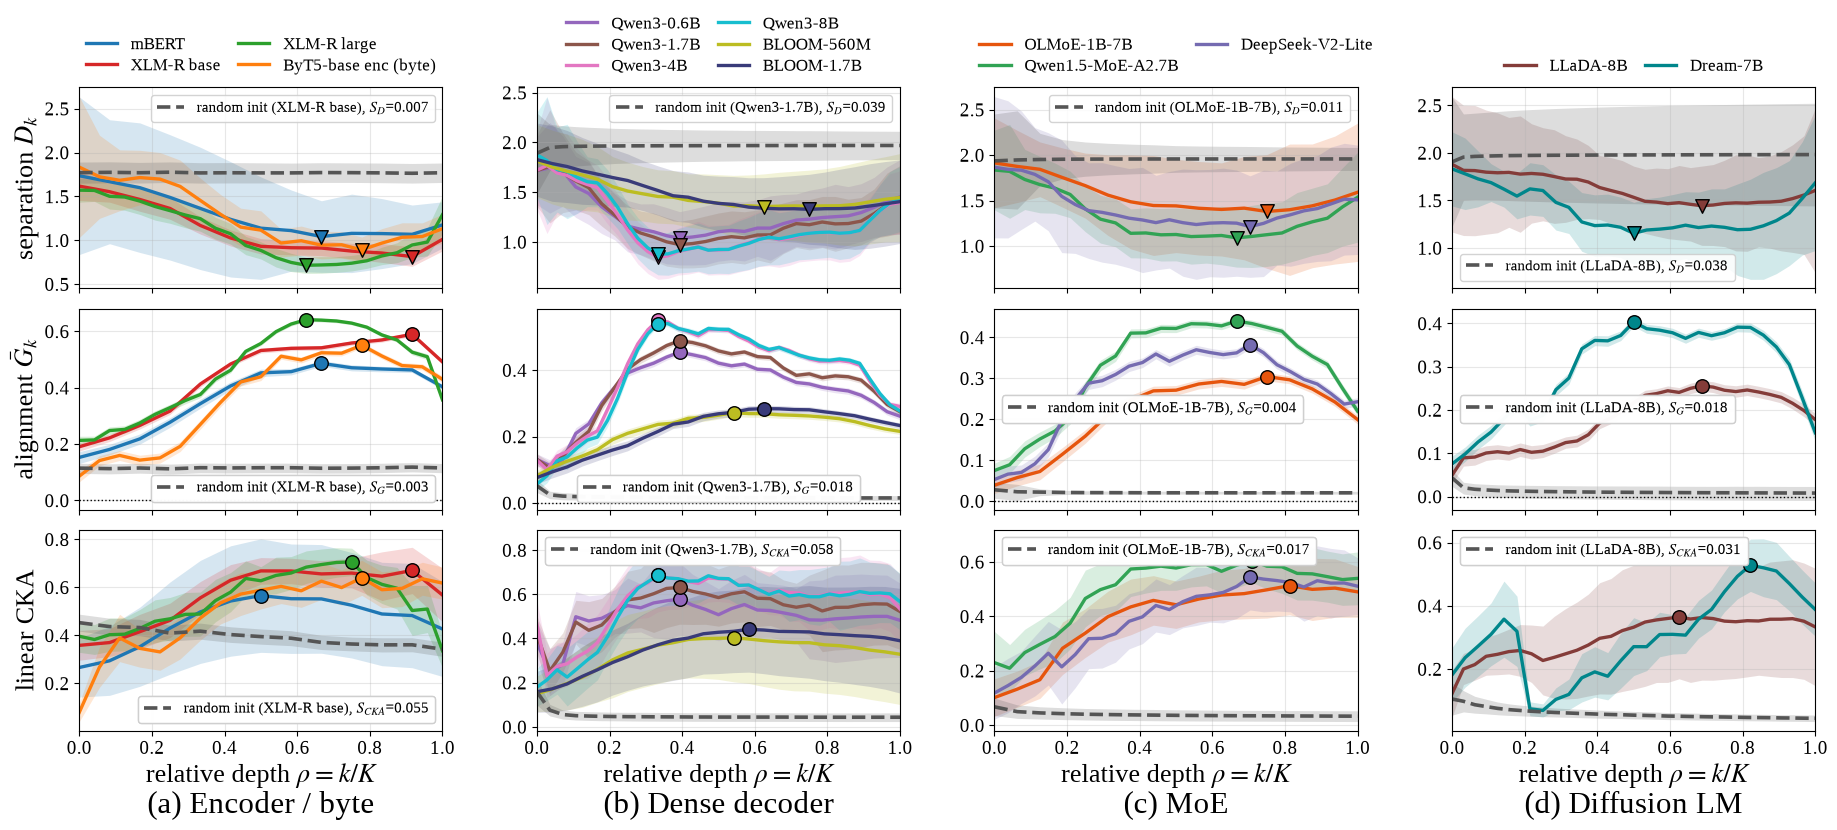

saved /mnt/cl/study1/figures/ntrex_stack_D-pre+r_G-pre+r_CKA-pre+r.pdf


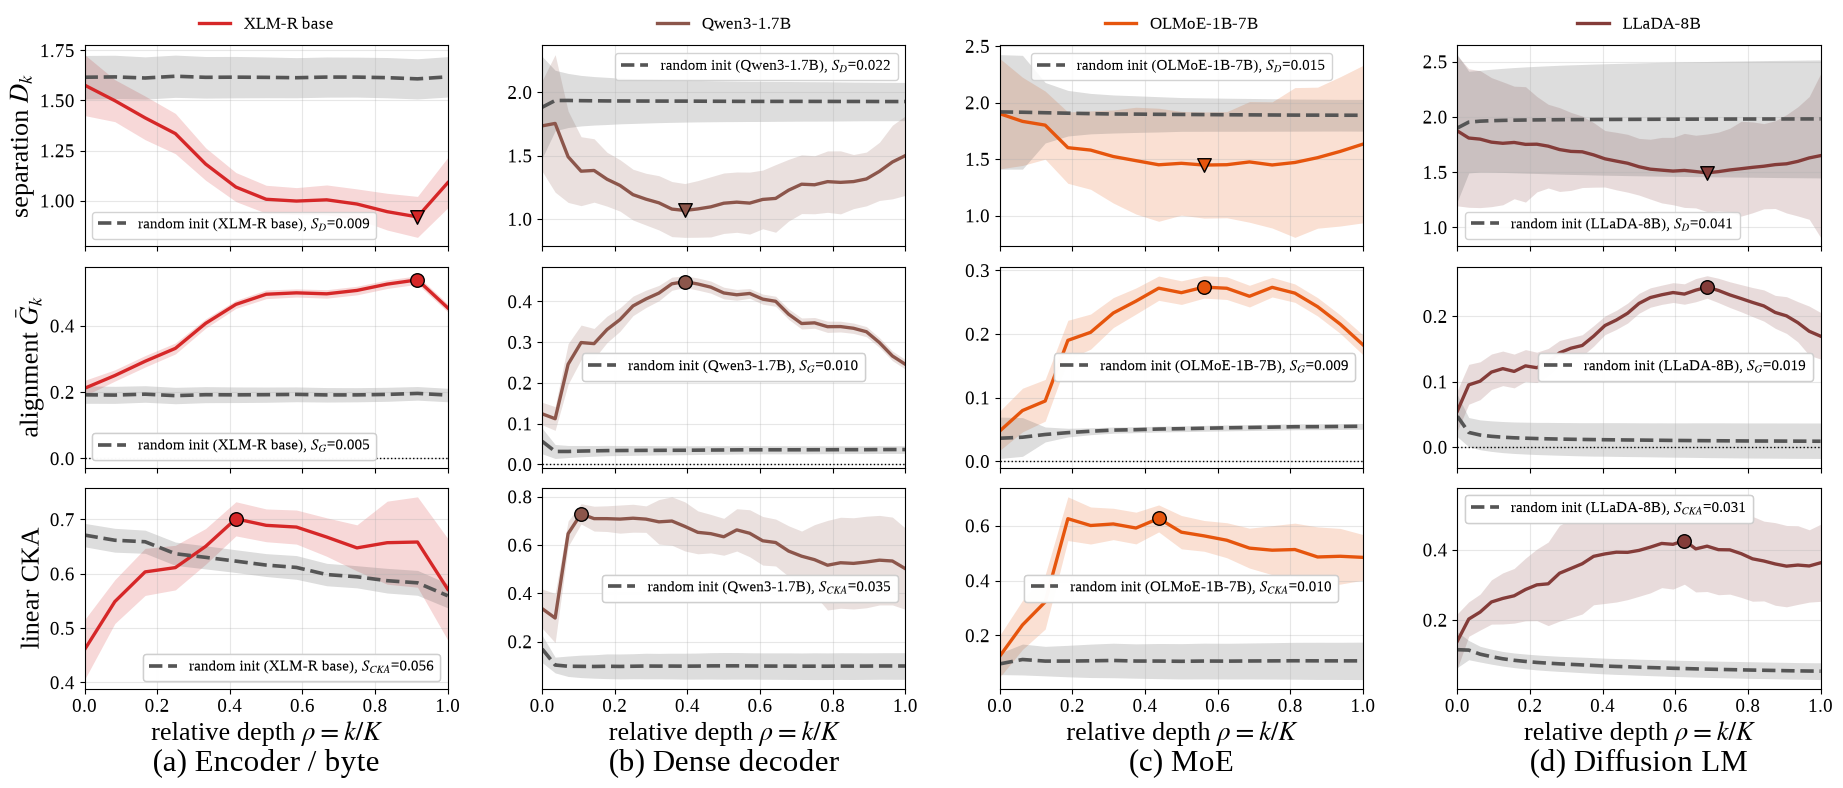

saved /mnt/cl/study1/figures/moe_routing_Jk_flores_ntrex.pdf


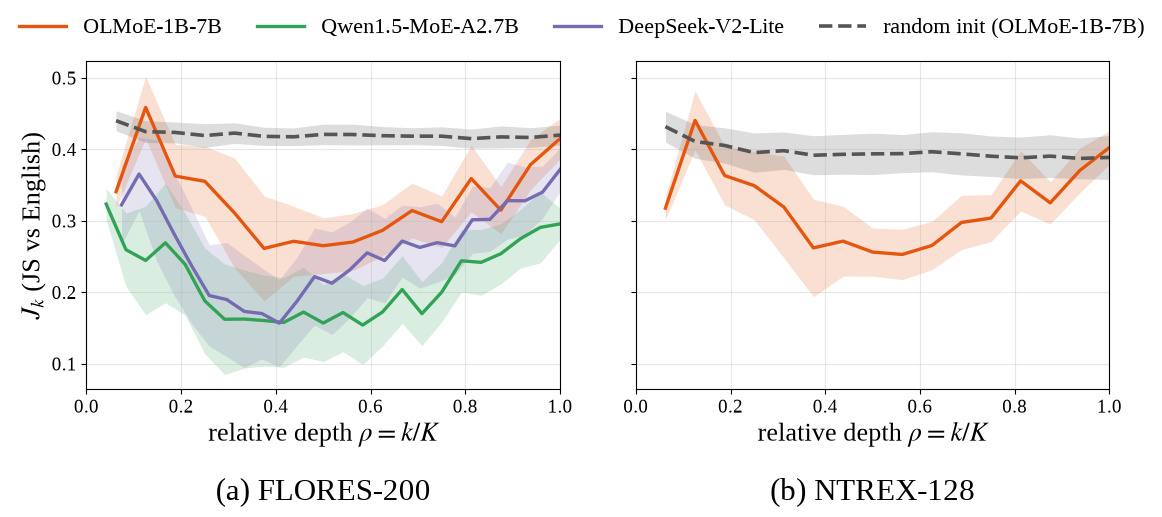

saved /mnt/cl/study1/figures/diffusion_G_masklevels_flores_ntrex.pdf


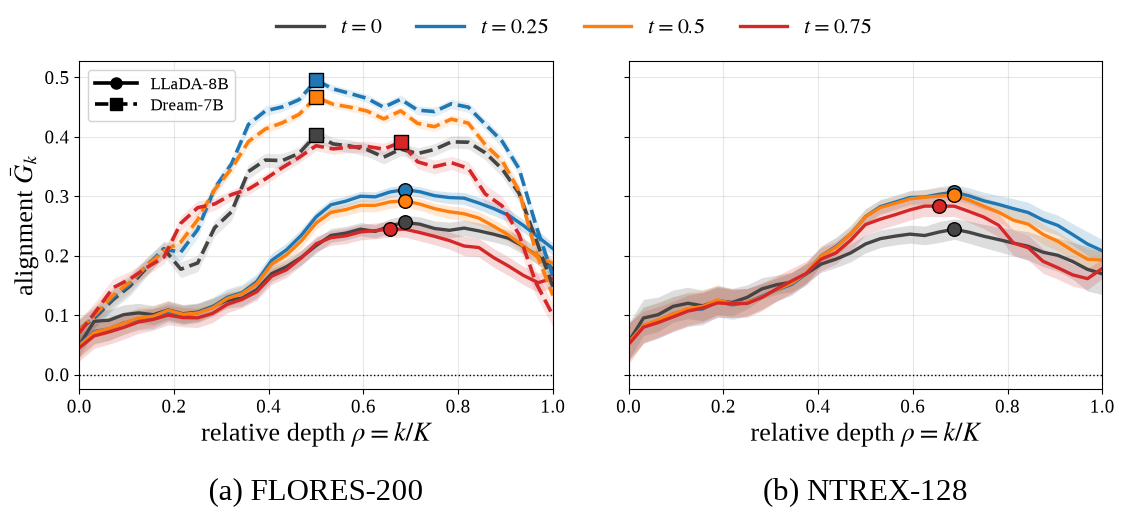

In [26]:
# ============================================================
# Cell D3b — Hình xếp chồng cho TỪNG dataset (FLORES và NTREX vẽ riêng, không gom chung). Mỗi canvas 3 x 4:
#   cột  = 4 họ kiến trúc (encoder / dense decoder / MoE / diffusion), mỗi cột gồm mọi model của họ đó;
#   hàng 1 = D_k   (separation): các model pretrained + đường random-init của họ đó (đứt, xám);
#   hàng 2 = G_k   (alignment): các model pretrained + đường random-init (đứt, xám);
#   hàng 3 = linear CKA: các model pretrained + đường random-init (đứt, xám).
# - plot_stack(ds)  : vẽ + lưu canvas 3 x 4 của MỘT dataset -> {ds}_stack_D-pre+r_G-pre+r_CKA-pre+r.pdf
# - plot_stack_all(): gọi plot_stack cho flores rồi ntrex (dataset chưa có kết quả thì bỏ qua). Gọi ở cuối cell này.
# Đổi hàng: rows=[(metric, kind), ...]; kind = "pretrained" | "pretrained+random" (thêm đường random-init) | "random".
#   Ví dụ bỏ random-init ở CKA: rows=[("D","pretrained+random"),("G","pretrained+random"),("CKA","pretrained")]
# [SỬA] label model: 1 legend chung phía TRÊN ĐẦU CỘT (kiểu code mẫu), màu lấy từ MODEL_COLOR/PALETTE (cell A2);
#   đường random-init (đứt) giữ nguyên D3b gốc: vẽ chung panel + legend nhỏ trong panel kèm S.
# Phụ thuộc: D1 (get_curves), D2 (band/save_fig/PANELS/X_RHO), D3 (collect_family), A2 (MODEL_COLOR).
# - plot_moe_js_datasets()      : J_k (JS routing) của các model MoE, (a) FLORES | (b) NTREX cạnh nhau  -> moe_routing_Jk_flores_ntrex.pdf
# - plot_diffusion_G_datasets() : Ḡ_k của diffusion LM theo mức che t, 1 hàng x 2 cột = FLORES | NTREX;
#   mỗi panel vẽ chung LLaDA (nét liền) + Dream (nét đứt)  -> diffusion_G_masklevels_flores_ntrex.pdf
#   (định nghĩa ở cuối cell này, gọi ngay sau plot_stack_all())
# ============================================================
FAM_NAME  = {"encoder": "Encoder / byte", "decoder": "Dense decoder", "moe": "MoE", "diffusion": "Diffusion LM"}
STACK_FS  = dict(label=19, tick=14, cap=22, legend=12.5)
CTRL_BG   = "#f5f5f5"          # nền hàng kind="random" (nếu dùng) để phân biệt nhóm đối chứng
DEFAULT_ROWS = [("D", "pretrained+random"), ("G", "pretrained+random"), ("CKA", "pretrained+random")]

def _shape(m, metric):
    """(k, độ sâu): D có đáy (chữ U) -> k=argmin, depth = trung bình hai đầu - đáy;
    các số đo khác (G, CKA, A, R, U) có đỉnh -> k=argmax, depth = đỉnh - trung bình hai đầu."""
    m = np.asarray(m, float)
    if not np.isfinite(m).any():
        return 0, np.nan
    ends = 0.5 * (m[0] + m[-1])
    if metric == "D":
        k = int(np.nanargmin(m)); return k, float(ends - m[k])
    k = int(np.nanargmax(m)); return k, float(m[k] - ends)

def _row_spec(rows):
    if rows is None:
        return list(DEFAULT_ROWS)
    if isinstance(rows, str):                      # plot_stack(ds, "D") -> 1 hàng: model pretrained + random-init
        return [(rows, "pretrained+random")]
    return list(rows)

def _row_tag(spec):
    return "_".join(f"{mt}-{k.split('+')[0][:3]}{'+r' if '+' in k else ''}" for mt, k in spec)

def _has_results(ds, fams=None):
    return any(collect_family(ds, fam)[0] for fam in (fams or FAMILIES))

def plot_stack(ds, rows=None, fams=None, panel_w=5.6, panel_h=3.2, sharey="col", annotate=True,
               annotate_rho=False, ref_pretrained=True, cap_y=-0.30, name=None):
    """Canvas len(rows) x len(fams) cho MỘT dataset (mặc định 3 x 4: D_k / G_k / CKA, hàng nào cũng có đường random-init).
    sharey: "col" (mỗi hàng một số đo riêng nên thực chất mỗi panel tự co thang), "all" (cùng số đo dùng chung thang qua các họ), "row", hoặc False.
    [SỬA] label model: 1 legend chung phía trên đầu CỘT (kiểu code mẫu), tạo bằng matplotlib.legend.Legend + add_artist
    để không bị ghi đè; chừa top=0.86 để legend không bị cắt. Màu model = MODEL_COLOR (PALETTE, cell A2).
    annotate: ghi độ sâu S vào legend đường random-init. annotate_rho: thêm rho của đáy/đỉnh vào legend model."""
    from matplotlib.legend import Legend

    spec = _row_spec(rows); nr = len(spec)
    fams = list(fams or FAMILIES); nc = len(fams); fs = STACK_FS
    fig, axes = plt.subplots(nr, nc, figsize=(panel_w * nc, panel_h * nr), sharex=True, squeeze=False)
    # [SỬA] chừa khoảng trống phía trên cho legend model của mỗi cột (tránh bị cắt khỏi canvas)
    # Chừa vùng phía trên đủ rộng cho một legend tên model ở mỗi cột kiến trúc.
    fig.subplots_adjust(wspace=0.26, hspace=0.10, top=0.78)

    first = {}                                                      # chia sẻ trục y theo nhóm (cùng số đo)
    for i, (mt, _) in enumerate(spec):
        for j in range(nc):
            key = {"col": (mt, j), "all": (mt,), "row": (i,)}.get(sharey)
            if key is None:
                continue
            if key in first:
                axes[i, j].sharey(first[key])
                if sharey in ("all", "row") and j > 0:
                    axes[i, j].tick_params(labelleft=False)
            else:
                first[key] = axes[i, j]

    # [SỬA] hàng gắn nhãn model = hàng đầu tiên có model pretrained -> legend chung đặt trên đầu cột (giống code mẫu)
    lab_row = next((i for i, (_, k) in enumerate(spec) if k.startswith("pretrained")), None)

    for j, fam in enumerate(fams):
        items, rnd = collect_family(ds, fam)
        for i, (mt, kind) in enumerate(spec):
            ax = axes[i, j]
            rsym = r"$\rho_{\min}$" if mt == "D" else r"$\rho^{\ast}$"
            ssym = "$S_{%s}$" % mt
            if kind == "random":
                ax.set_facecolor(CTRL_BG)
            if not items:
                ax.text(0.5, 0.5, "chưa có kết quả", transform=ax.transAxes, ha="center", va="center",
                        fontsize=fs["tick"], color="gray")
            elif "random" in kind and rnd is None:
                ax.text(0.5, 0.06, "chưa chạy random-init", transform=ax.transAxes, ha="center", va="bottom",
                        fontsize=fs["tick"] - 1, color="gray")
            if kind.startswith("pretrained"):
                for it in items:
                    col = MODEL_COLOR[it["key"]]                   # [SỬA] màu theo PALETTE/MODEL_COLOR của cell A2
                    m, lo, hi = it["c"][mt]
                    x = np.arange(len(m)) / (len(m) - 1)
                    k, _ = _shape(m, mt)
                    lab = None
                    if i == lab_row:
                        lab = f"{it['label']} ({rsym}={x[k]:.2f})" if annotate_rho else it["label"]
                    band(ax, x, m, lo, hi, col, label=lab)
                    ax.scatter([x[k]], [m[k]], s=95, marker="v" if mt == "D" else "o", color=col,
                               edgecolor="black", zorder=5)
            if "random" in kind and rnd is not None:               # đường random-init của họ, vẽ chung panel với model pretrained (GIỮ NGUYÊN D3b)
                m, lo, hi = rnd["c"][mt]
                x = np.arange(len(m)) / (len(m) - 1)
                lab = rnd["label"] + (f", {ssym}={_shape(m, mt)[1]:.3f}" if annotate else "")
                band(ax, x, m, lo, hi, rnd["color"], label=lab, ls="--", lw=2.6, alpha=0.20)
                ref = next((it for it in items if it["key"] == RANDOM_BASELINE[fam]), None) \
                    if (kind == "random" and ref_pretrained) else None
                if ref is not None:                                  # chỉ kind="random": vẽ mờ model pretrained cùng kiến trúc làm mốc
                    mp, lop, hip = ref["c"][mt]
                    xp = np.arange(len(mp)) / (len(mp) - 1)
                    labp = f"pretrained ({ref['label']})" + (f", {ssym}={_shape(mp, mt)[1]:.3f}" if annotate else "")
                    ax.plot(xp, mp, color=ref["color"], lw=1.9, alpha=0.55, label=labp)
                    ax.fill_between(xp, lop, hip, color=ref["color"], alpha=0.07, linewidth=0)
            ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=fs["tick"])
            if mt in ("G", "A"):
                ax.axhline(0, color="black", lw=1.0, ls=":")
            # Legend random-init vẫn nằm trong từng panel; legend model được tạo một lần
            # cho cả cột ở phía trên sau khi vẽ xong toàn bộ các hàng.
            h, l = ax.get_legend_handles_labels()
            if items and l:
                rl = rnd["label"] if rnd is not None else None
                hr = [hh for hh, lb in zip(h, l) if rl and lb.startswith(rl)]
                lr = [lb for lb in l if rl and lb.startswith(rl)]
                if hr:
                    leg_random = ax.legend(hr, lr, loc="best", fontsize=fs["legend"] - 1.5,
                                           frameon=True, framealpha=0.85, handlelength=1.8,
                                           labelspacing=0.3)
                    ax.add_artist(leg_random)

        # Một legend duy nhất cho tên model ở phía trên mỗi cột.
        # Dùng Line2D trực tiếp thay vì phụ thuộc vào legend handles của band().
        from matplotlib.lines import Line2D
        if items:
            model_handles = [
                Line2D([0], [0], color=MODEL_COLOR[it["key"]], lw=2.4, label=it["label"])
                for it in items
            ]
            axes[0, j].legend(
                handles=model_handles, loc="lower center",
                bbox_to_anchor=(0.5, 1.03),
                ncol=min(2, len(model_handles)), fontsize=fs["legend"],
                frameon=False, handlelength=1.8, columnspacing=1.0,
                labelspacing=0.3, borderaxespad=0.0
            )
        axes[-1, j].set_xlabel(X_RHO, fontsize=fs["label"])
        axes[-1, j].text(0.5, cap_y, f"({'abcdefgh'[j]}) {FAM_NAME.get(fam, fam)}", transform=axes[-1, j].transAxes,
                         ha="center", va="top", fontsize=fs["cap"])
    for i, (mt, kind) in enumerate(spec):
        axes[i, 0].set_ylabel(PANELS[mt][0], fontsize=fs["label"])
    save_fig(fig, name or f"{ds_tag(ds)}_stack_{_row_tag(spec)}")

def plot_stack_all(dss=("flores", "ntrex"), rows=None, **kw):
    """Vẽ + lưu canvas riêng cho từng dataset. Dataset chưa có kết quả sẽ bị bỏ qua."""
    for ds in dss:
        if _has_results(ds, kw.get("fams")):
            plot_stack(ds, rows, **kw)
        else:
            print(f"[skip] {ds_tag(ds)}: chưa có kết quả")

# ============================================================
# HAI HÌNH SO SÁNH HAI DATASET (FLORES-200 | NTREX-128), xếp cạnh nhau, panel nào cũng có sub-caption (a), (b), ...
#   plot_moe_js_datasets()        : J_k (JS routing divergence vs English) của các model MoE   -> (a) FLORES, (b) NTREX
#   plot_diffusion_G_datasets()   : alignment Ḡ_k của diffusion LM ở các mức che t           -> cột = dataset; LLaDA (liền) + Dream (đứt) chung panel
# Phụ thuộc thêm: C1 (load_variant), A2 (MODELS, RANDOM_BASELINE, variant_name), A1 (MASK_LEVELS), D1 (get_curves).
# Dataset/model chưa có kết quả (vd. NTREX chỉ chạy OLMoE và LLaDA) thì panel đó ghi "chưa có kết quả", không báo lỗi.
# ============================================================
DS_NAME     = {"flores": "FLORES-200", "ntrex": "NTREX-128"}
MASK_COLORS = {0.0: "#444444", 0.25: "#1f77b4", 0.5: "#ff7f0e", 0.75: "#d62728"}   # cùng màu với D5

def _ds_name(ds):
    return DS_NAME.get(ds, ds)

PAIR_TOP = 0.93      # mép trên vùng vẽ (tỉ lệ chiều cao hình); legend nằm ngay phía trên

def _pair_axes(nr, nc, panel_w, panel_h, sharey):
    # sharex=False: mọi panel đều giữ nhãn trục x (mỗi panel có sub-caption riêng); xlim đặt tay (0, 1)
    fig, axes = plt.subplots(nr, nc, figsize=(panel_w * nc, panel_h * nr), sharex=False, sharey=sharey, squeeze=False)
    fig.subplots_adjust(wspace=0.16, hspace=0.62 if nr > 1 else 0.1, top=PAIR_TOP)
    return fig, axes

def _pair_caption(ax, text, fs, cap_y=-0.27):
    ax.text(0.5, cap_y, text, transform=ax.transAxes, ha="center", va="top", fontsize=fs["cap"])

def _shared_legend(fig, axes, fs, ncol_max=4, y=PAIR_TOP + 0.01):
    hs, ls_ = [], []
    for ax in axes.ravel():
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in ls_:
                hs.append(h); ls_.append(l)
    if hs:
        fig.legend(hs, ls_, loc="lower center", bbox_to_anchor=(0.5, y), ncol=min(ncol_max, len(ls_)),
                   fontsize=fs["legend"] + 3, frameon=False, handlelength=2.2, columnspacing=1.6)

def _no_result(ax, fs, msg="chưa có kết quả"):
    ax.text(0.5, 0.5, msg, transform=ax.transAxes, ha="center", va="center", fontsize=fs["tick"], color="gray")

def _moe_js_runs(ds):
    """([(key, cfg, d)] các model MoE có J_k, d_random hoặc None, key_random)."""
    items = []
    for key, cfg in MODELS.items():
        if cfg["family"] == "moe":
            d = load_variant(ds, key, "base")
            if d is not None and "JS" in d:
                items.append((key, cfg, d))
    rk = RANDOM_BASELINE["moe"]
    dr = load_variant(ds, rk + "__random", "base")
    return items, (dr if (dr is not None and "JS" in dr) else None), rk

def _moe_js_xy(d):
    """x = độ sâu tương đối của tầng MoE; js [n_lang-1, Lm] = trung bình theo content (giống D4)."""
    js = d["JS"].mean(2)
    x = (d["JS_layers"] + 1) / max(int(d["n_layers"]), 1)
    return x, js

def plot_moe_js_datasets(dss=("flores", "ntrex"), show_random=True, panel_w=6.6, panel_h=4.0, name=None):
    """Hình 1 x len(dss): (a) mọi model MoE trên FLORES, (b) mọi model MoE trên NTREX. Đường = mean qua ngôn ngữ, dải = ± std qua ngôn ngữ;
    đường đứt xám = random-init (OLMoE). Hai panel dùng chung trục y để so sánh trực tiếp độ lớn J_k giữa hai dataset."""
    fs = STACK_FS; dss = list(dss)
    runs = {ds: _moe_js_runs(ds) for ds in dss}
    if not any(runs[ds][0] for ds in dss):
        print("[skip] moe J_k flores/ntrex: chưa có kết quả"); return
    fig, axes = _pair_axes(1, len(dss), panel_w, panel_h, sharey=True)
    for j, ds in enumerate(dss):
        ax = axes[0, j]; items, dr, rk = runs[ds]
        if not items:
            _no_result(ax, fs)
        for key, cfg, d in items:
            x, js = _moe_js_xy(d); m, s = js.mean(0), js.std(0)
            band(ax, x, m, np.clip(m - s, 0, None), m + s, MODEL_COLOR[key], label=cfg["label"])
        if show_random and dr is not None:
            x, js = _moe_js_xy(dr); m, s = js.mean(0), js.std(0)
            band(ax, x, m, np.clip(m - s, 0, None), m + s, RANDOM_COLOR, label=f"random init ({MODELS[rk]['label']})",
                 ls="--", lw=2.6, alpha=0.20)
        ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=fs["tick"])
        ax.set_xlabel(X_RHO, fontsize=fs["label"])
        if j == 0:
            ax.set_ylabel(r"$J_k$ (JS vs English)", fontsize=fs["label"])
        _pair_caption(ax, f"({'abcdefgh'[j]}) {_ds_name(ds)}", fs)
    _shared_legend(fig, axes, fs, ncol_max=4)
    save_fig(fig, name or "moe_routing_Jk_" + "_".join(ds_tag(d) for d in dss))

def plot_diffusion_G_datasets(dss=("flores", "ntrex"), models=None, pool="all", t_levels=None, mark_peak=True,
                              panel_w=6.6, panel_h=4.0, name=None):
    """Hình alignment Ḡ_k của diffusion LM ở các mức che t: 1 hàng, CỘT = dataset (FLORES | NTREX).
    Mọi model diffusion có kết quả được vẽ CHUNG một panel: model đầu tiên (LLaDA) nét liền, các model sau (Dream) nét đứt.
    Màu = mức che t (dải = CI 95% bootstrap theo content); chấm = đỉnh k* (tròn = nét liền, vuông = nét đứt). Trục y dùng chung.
    models=["llada_8b"] chỉ vẽ một model; pool="masked" vẽ riêng token bị che (bỏ t=0)."""
    from matplotlib.lines import Line2D
    fs = STACK_FS; dss = list(dss)
    t_levels = list(MASK_LEVELS if t_levels is None else t_levels)
    ts = [t for t in t_levels if not (pool == "masked" and t == 0)]
    keys = list(models) if models else [k for k, c in MODELS.items() if c["family"] == "diffusion"]
    has = lambda ds, k: any(get_curves(ds, k, variant_name(t, pool)) is not None for t in ts)
    keys = [k for k in keys if any(has(ds, k) for ds in dss)]
    if not keys:
        print("[skip] diffusion Ḡ_k flores/ntrex: chưa có kết quả"); return

    # kiểu nét theo thứ tự model (cố định cho mọi panel): model đầu = liền, các model sau = đứt
    LINE_KW = [dict(), dict(ls="--", lw=2.6, alpha=0.12)]
    MARKERS = ["o", "s"]
    sty = lambda n: LINE_KW[min(n, len(LINE_KW) - 1)]
    mk  = lambda n: MARKERS[min(n, len(MARKERS) - 1)]

    fig, axes = _pair_axes(1, len(dss), panel_w, panel_h, sharey=True)
    for j, ds in enumerate(dss):
        ax = axes[0, j]; any_data = False
        for n_k, k in enumerate(keys):
            for n_t, t in enumerate(ts):
                c = get_curves(ds, k, variant_name(t, pool))
                if c is None:
                    continue
                any_data = True
                m, lo, hi = c["G"]; x = np.arange(len(m)) / (len(m) - 1)
                col = MASK_COLORS.get(t, PALETTE[n_t % len(PALETTE)])
                band(ax, x, m, lo, hi, col, label=rf"$t={t:g}$", **sty(n_k))
                if mark_peak and np.isfinite(m).any():
                    kk = int(np.nanargmax(m))
                    ax.scatter([x[kk]], [m[kk]], s=95, marker=mk(n_k), color=col, edgecolor="black", zorder=5)
        if not any_data:
            _no_result(ax, fs)
        ax.axhline(0, color="black", lw=1.0, ls=":")
        ax.set_xlim(0, 1); ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=fs["tick"])
        ax.set_xlabel(X_RHO, fontsize=fs["label"])
        if j == 0:
            ax.set_ylabel(PANELS["G"][0], fontsize=fs["label"])
        _pair_caption(ax, f"({'abcdefgh'[j]}) {_ds_name(ds)}" + (", masked tokens" if pool == "masked" else ""), fs)

    # legend kiểu nét -> model (đặt trong panel đầu tiên; màu t nằm ở legend chung phía trên)
    if len(keys) > 1:
        mh = [Line2D([0], [0], color="black", lw=2.6, ls=sty(n).get("ls", "-"), marker=mk(n), markersize=8,
                     markeredgecolor="black", label=MODELS[k]["label"]) for n, k in enumerate(keys)]
        axes[0, 0].legend(handles=mh, loc="best", fontsize=fs["legend"], frameon=True, framealpha=0.85,
                          handlelength=2.4, labelspacing=0.3)
    _shared_legend(fig, axes, fs, ncol_max=len(ts))
    save_fig(fig, name or "diffusion_G_masklevels_" + "_".join(ds_tag(d) for d in dss) + ("" if pool == "all" else f"_{pool}"))

plot_stack_all()
plot_moe_js_datasets()           # (a) MoE trên FLORES | (b) MoE trên NTREX
plot_diffusion_G_datasets()      # Ḡ_k theo mức che t: cột = FLORES | NTREX, mỗi panel LLaDA (liền) + Dream (đứt)

In [27]:
#@@@ code
# ============================================================
# Cell D4 — MoE: J_k (JS routing divergence so với English) — hình kiểu Figure 4
# ============================================================
def plot_moe_routing(ds):
    items = []
    for key, cfg in MODELS.items():
        if cfg["family"] == "moe":
            d = load_variant(ds, key, "base")
            if d is not None and "JS" in d:
                items.append((key, cfg, d))
    if not items:
        print(f"[skip] {ds_tag(ds)} moe routing: chưa có kết quả"); return
    rk = RANDOM_BASELINE["moe"]
    dr = load_variant(ds, rk + "__random", "base")
    dr = dr if (dr is not None and "JS" in dr) else None

    def prep(d):
        js = d["JS"].mean(2)                                    # [n_lang-1, Lm]: trung bình theo content
        x = (d["JS_layers"] + 1) / max(int(d["n_layers"]), 1)   # độ sâu tương đối của tầng MoE
        return x, js
    n_pan = 1 + len(items)
    ncols = 2; nrows = int(math.ceil(n_pan / ncols))
    fig, axes = make_fig(nrows, ncols)
    axl = axes.ravel()
    for ax in axl[n_pan:]:
        ax.axis("off")
    ax = axl[0]                                                 # (a) mean ± std qua ngôn ngữ, mọi model MoE
    for key, cfg, d in items:
        x, js = prep(d); m, s = js.mean(0), js.std(0)
        band(ax, x, m, m - s, m + s, MODEL_COLOR[key], label=cfg["label"])
    if dr is not None:
        x, js = prep(dr); m, s = js.mean(0), js.std(0)
        band(ax, x, m, m - s, m + s, RANDOM_COLOR, label=f"random init ({MODELS[rk]['label']})", ls="--", lw=2.2, alpha=0.15)
    style_ax(ax, X_RHO, r"$J_k$ (JS vs English)", "(a)", "all MoE models")
    for ax, (key, cfg, d), cap in zip(axl[1:n_pan], items, "bcd"):    # (b..) từng model: mọi ngôn ngữ + mean ± std
        x, js = prep(d); c = MODEL_COLOR[key]
        for row in js:
            ax.plot(x, row, color=c, lw=0.9, alpha=0.30)
        m, s = js.mean(0), js.std(0)
        band(ax, x, m, m - s, m + s, c, lw=2.8, alpha=0.20)
        style_ax(ax, X_RHO, r"$J_k$ (JS vs English)", f"({cap})", cfg["label"])
    h, l = axl[0].get_legend_handles_labels()
    add_legend(fig, h, l, ncol=min(3, len(l)))
    save_fig(fig, f"{ds_tag(ds)}_moe_routing_Jk")

In [28]:
#@@@ code
# ============================================================
# Cell D5 — Diffusion: ảnh hưởng của mức che t (S6), pool trên mọi token vs chỉ token bị che
# Màu = mức che (mỗi panel là một model)
# ============================================================
T_COLORS = {0.0: "#444444", 0.25: "#1f77b4", 0.5: "#ff7f0e", 0.75: "#d62728"}

def plot_diffusion_masklevels(ds):
    keys = [k for k, c in MODELS.items() if c["family"] == "diffusion"]
    panels = [(k, p) for k in keys for p in ("all", "masked")]
    ncols = 2; nrows = int(math.ceil(len(panels) / ncols))
    fig, axes = make_fig(nrows, ncols)
    axl = axes.ravel(); any_data = False
    for ax in axl[len(panels):]:
        ax.axis("off")
    for ax, (k, pool), cap in zip(axl, panels, "abcdefgh"):
        for t in MASK_LEVELS:
            if pool == "masked" and t == 0:
                continue
            c = get_curves(ds, k, variant_name(t, pool))
            if c is None:
                continue
            any_data = True
            m, lo, hi = c["G"]; x = np.arange(len(m)) / (len(m) - 1)
            band(ax, x, m, lo, hi, T_COLORS[t], label=rf"$t={t}$")
            kk = int(np.nanargmax(m))
            ax.scatter([x[kk]], [m[kk]], s=110, color=T_COLORS[t], edgecolor="black", zorder=5)
        ax.axhline(0, color="black", lw=1.0, ls=":"); ax.set_xlim(0, 1)
        style_ax(ax, X_RHO, PANELS["G"][0], f"({cap})",
                 f"{MODELS[k]['label']}, {'all tokens' if pool == 'all' else 'masked tokens'}")
    if not any_data:
        print(f"[skip] {ds_tag(ds)} diffusion: chưa có kết quả"); plt.close(fig); return
    hs, ls_ = [], []
    for ax in axl:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in ls_:
                hs.append(h); ls_.append(l)
    add_legend(fig, hs, ls_, ncol=len(ls_))
    save_fig(fig, f"{ds_tag(ds)}_diffusion_masklevels")

In [29]:
#@@@ code
# ============================================================
# Cell D6 — Tóm tắt waist của mọi model: rho*, S, w với CI 95% bootstrap (ô rỗng = random-init)
# ============================================================
def plot_summary(ds):
    df = feature_table(ds, save=False)
    if df.empty:
        print(f"[skip] {ds_tag(ds)} summary: chưa có kết quả"); return
    order = []
    for fam in FAMILIES:
        sub = df[df.family == fam]
        order += [r for _, r in sub[~sub.random_init].iterrows()] + [r for _, r in sub[sub.random_init].iterrows()]
    n = len(order)
    fig, axes = plt.subplots(1, 3, figsize=(8.0 * 3, 0.55 * n + 3.2), sharey=True)
    fig.subplots_adjust(wspace=0.12, top=0.92)
    specs = [("rho_star", "rho_lo", "rho_hi", r"$\rho^*$", "(a)", r"$\rho^*$"),
             ("S", "S_lo", "S_hi", r"waist depth $S$", "(b)", r"$S$"),
             ("w", "w_lo", "w_hi", r"waist width $w$", "(c)", r"$w$")]
    for ax, (v, lo, hi, xl, cap, desc) in zip(axes, specs):
        for yi, r in enumerate(order):
            key = r["run"].replace("__random", "")
            col = RANDOM_COLOR if r["random_init"] else MODEL_COLOR[key]
            xe = [[max(r[v] - r[lo], 0)], [max(r[hi] - r[v], 0)]]
            ax.errorbar(r[v], yi, xerr=xe, fmt="s" if r["random_init"] else "o", color=col, ms=10, capsize=4, lw=2.2,
                        mfc="white" if r["random_init"] else col, mew=2)
        prev = None
        for yi, r in enumerate(order):                                   # vạch ngăn giữa các nhóm kiến trúc
            if prev is not None and r["family"] != prev:
                ax.axhline(yi - 0.5, color="gray", lw=1.0, ls="--")
            prev = r["family"]
        ax.set_yticks(range(n)); ax.set_yticklabels([r["label"] for r in order], fontsize=TICK_FS)
        ax.set_ylim(n - 0.5, -0.5)
        style_ax(ax, xl, "", cap, desc)
    h = [Line2D([], [], marker="o", color="black", ls="", ms=10, label="pretrained"),
         Line2D([], [], marker="s", mfc="white", mec=RANDOM_COLOR, color=RANDOM_COLOR, ls="", ms=10, mew=2, label="random init")]
    add_legend(fig, h, [x.get_label() for x in h], ncol=2)
    save_fig(fig, f"{ds_tag(ds)}_waist_summary")

   family                label  k_star  rho_star     S  S_edge  S_edge_lo     w  k_star_cka  cka_in_band above_random  has_waist
  encoder                mBERT       8     0.667 0.209   0.083      0.080 0.462           6         True         True       True
  encoder           XLM-R base      11     0.917 0.249   0.098      0.096 0.462          11         True         True       True
  encoder  XLM-R base (random)      11     0.917 0.003   0.003      0.001 0.077           0        False         None      False
  encoder          XLM-R large      15     0.625 0.356   0.284      0.278 0.400          18         True         True       True
  encoder ByT5-base enc (byte)      14     0.778 0.293   0.121      0.118 0.368          14         True         True       True
  decoder           Qwen3-0.6B      11     0.393 0.258   0.193      0.186 0.414          11         True         True       True
  decoder           Qwen3-1.7B      11     0.393 0.286   0.214      0.207 0.379          11      

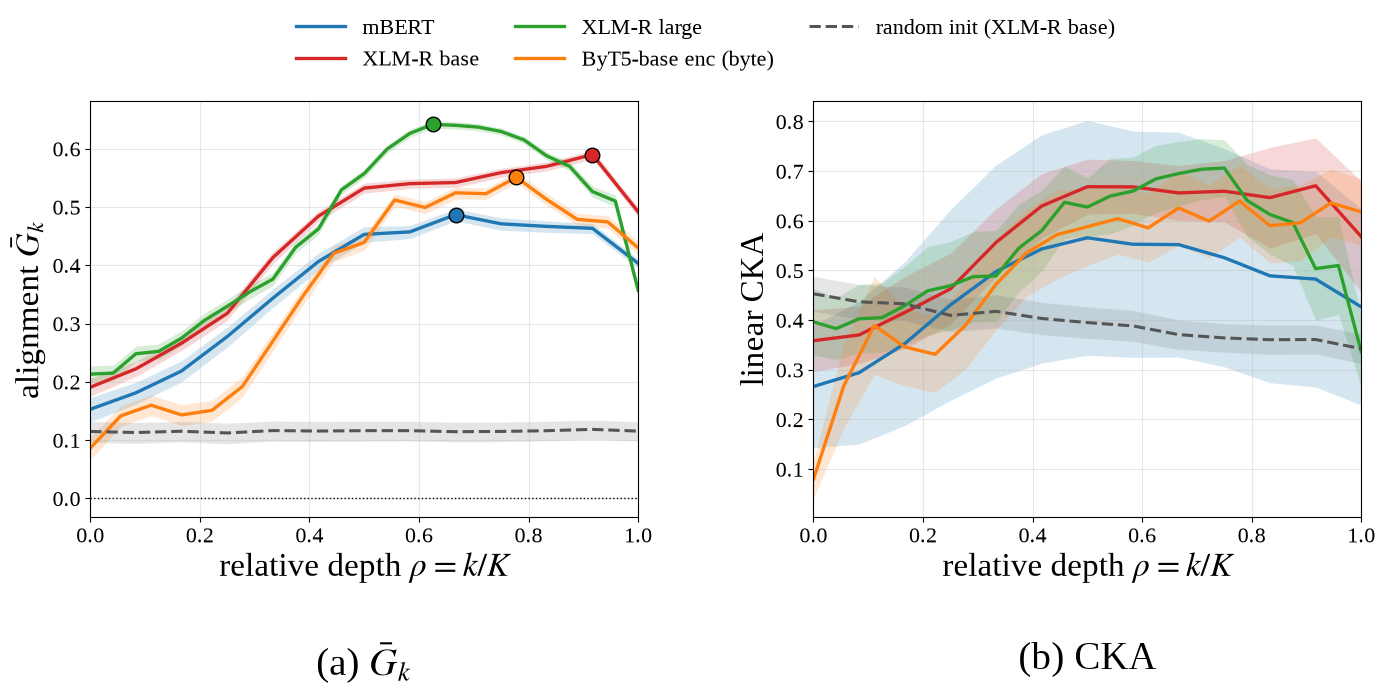

saved /mnt/cl/study1/figures/flores_encoder_extra.pdf


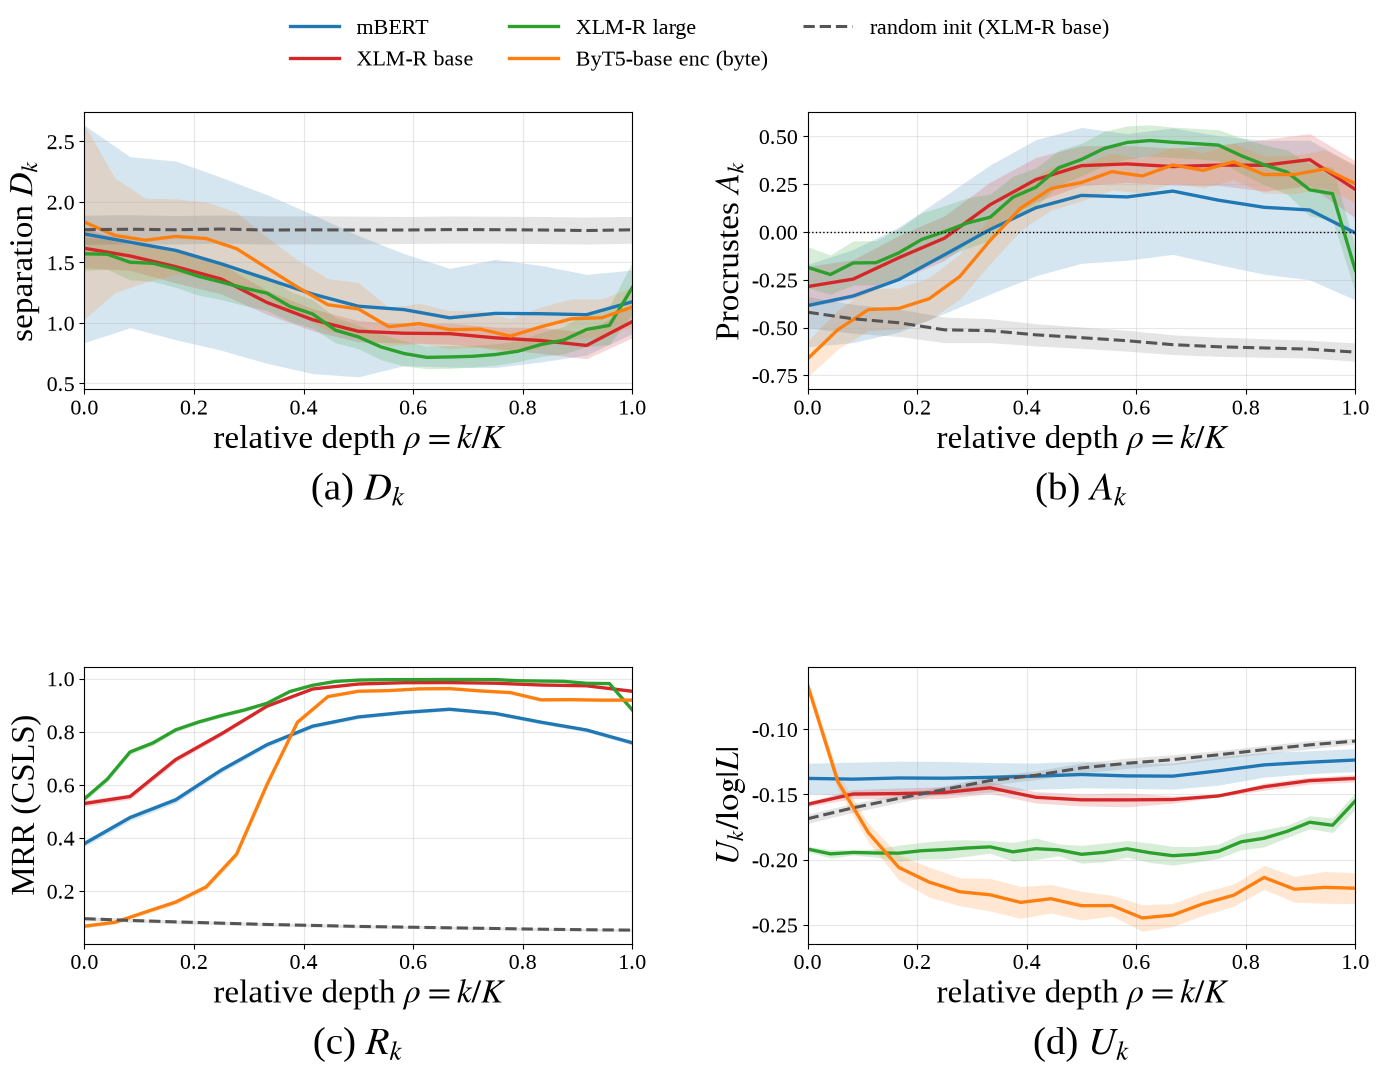

saved /mnt/cl/study1/figures/flores_decoder_llm_main.pdf


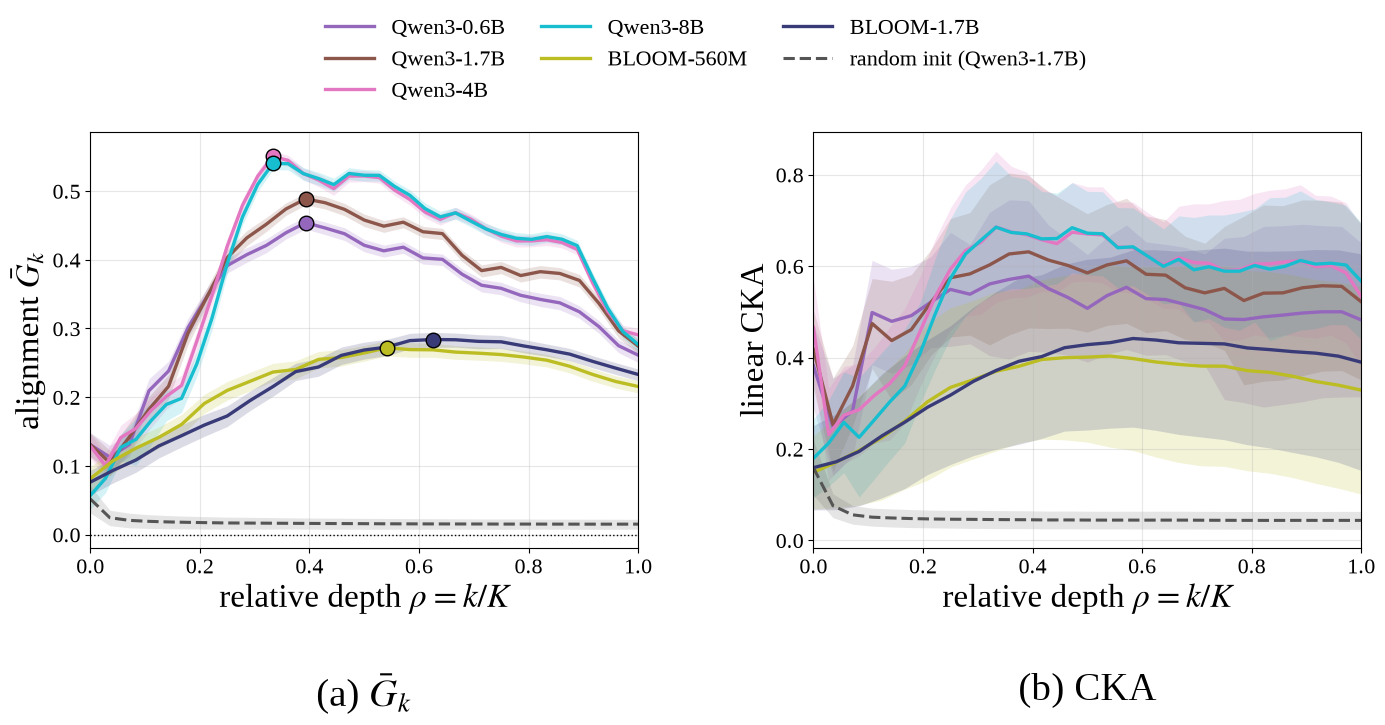

saved /mnt/cl/study1/figures/flores_decoder_llm_extra.pdf


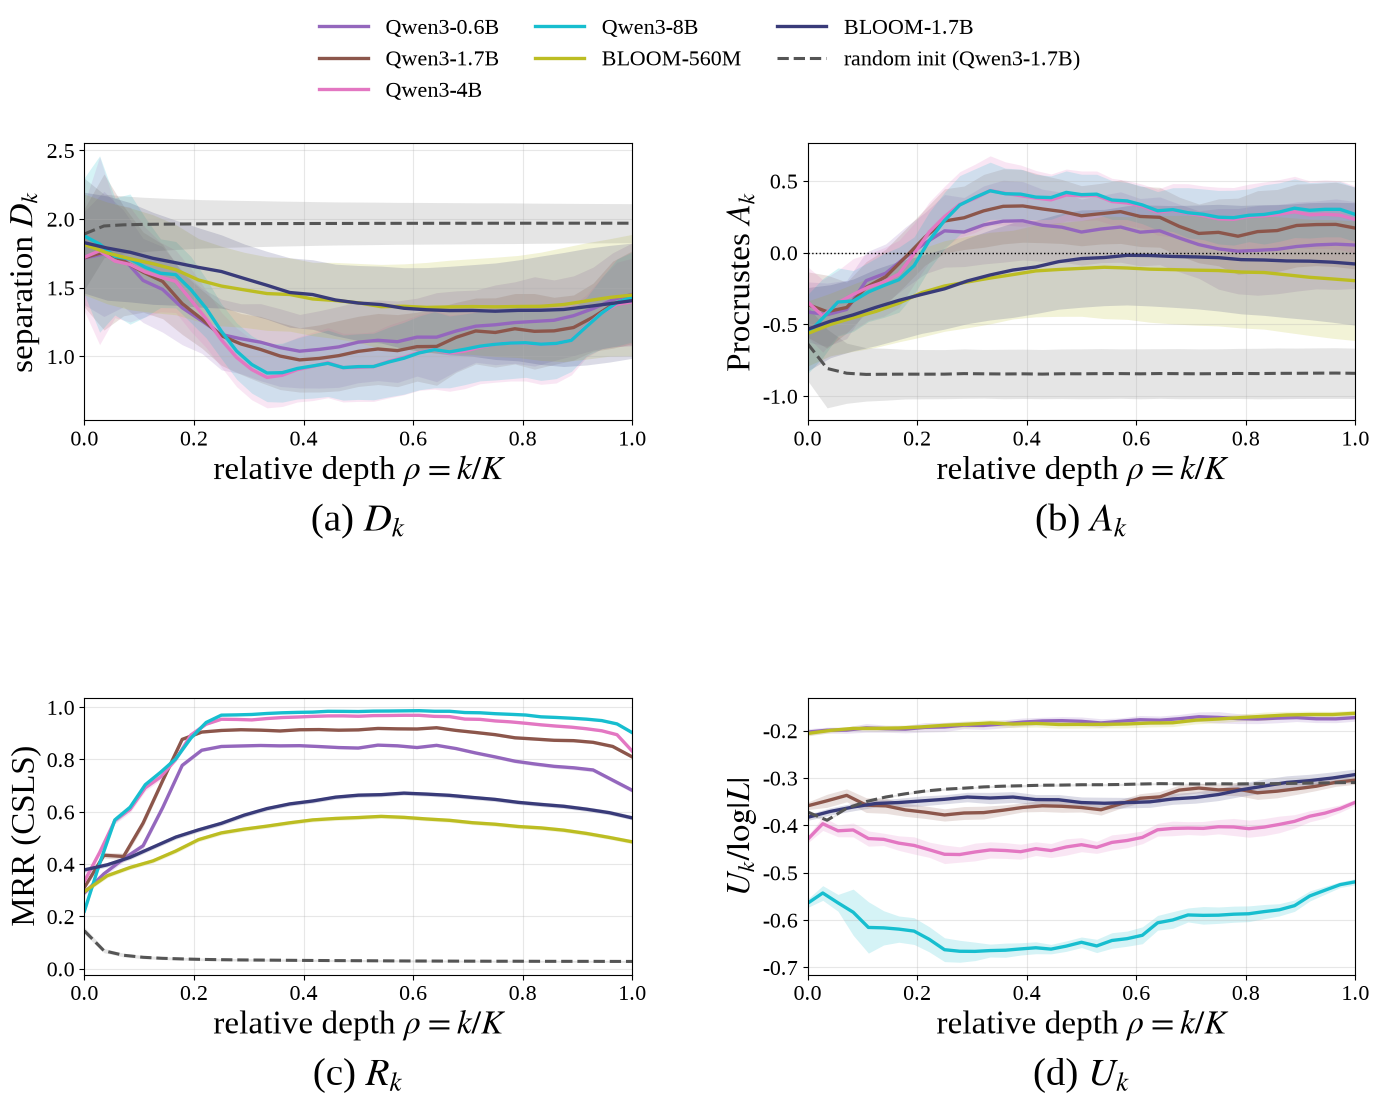

saved /mnt/cl/study1/figures/flores_moe_main.pdf


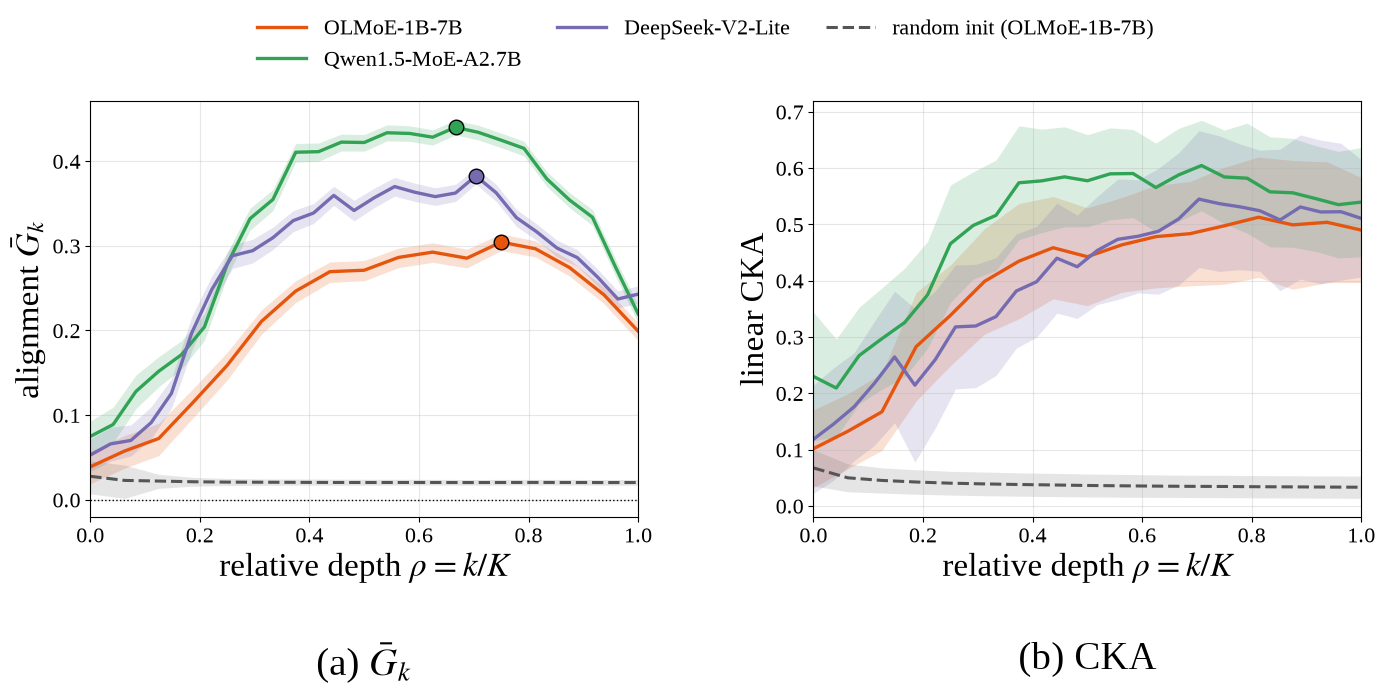

saved /mnt/cl/study1/figures/flores_moe_extra.pdf


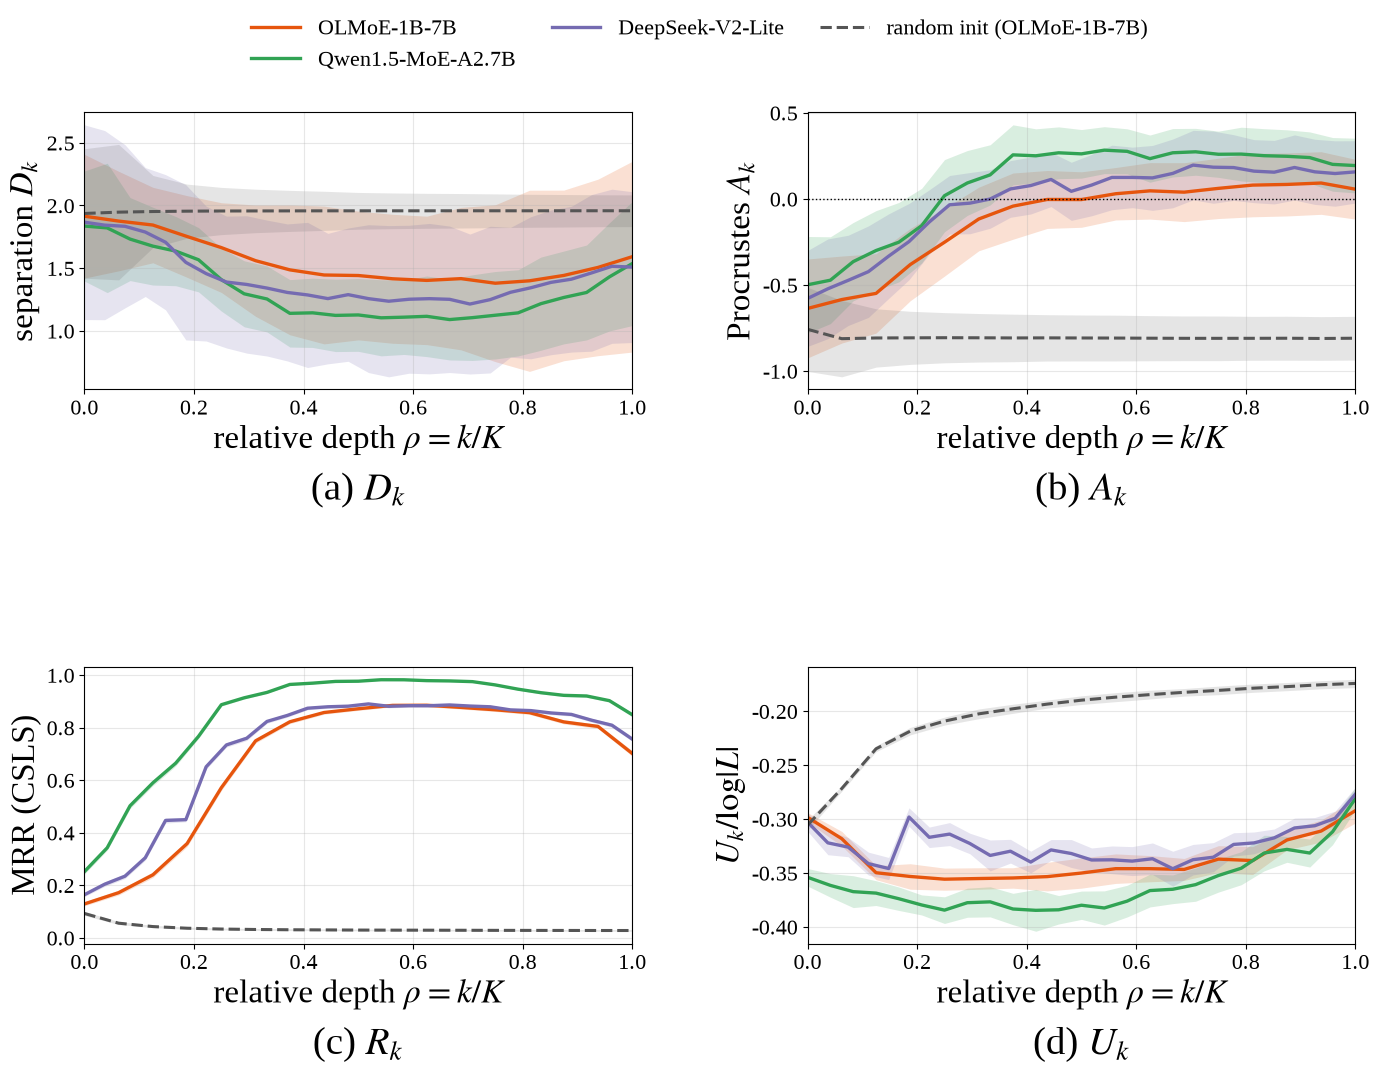

saved /mnt/cl/study1/figures/flores_diffusion_main.pdf


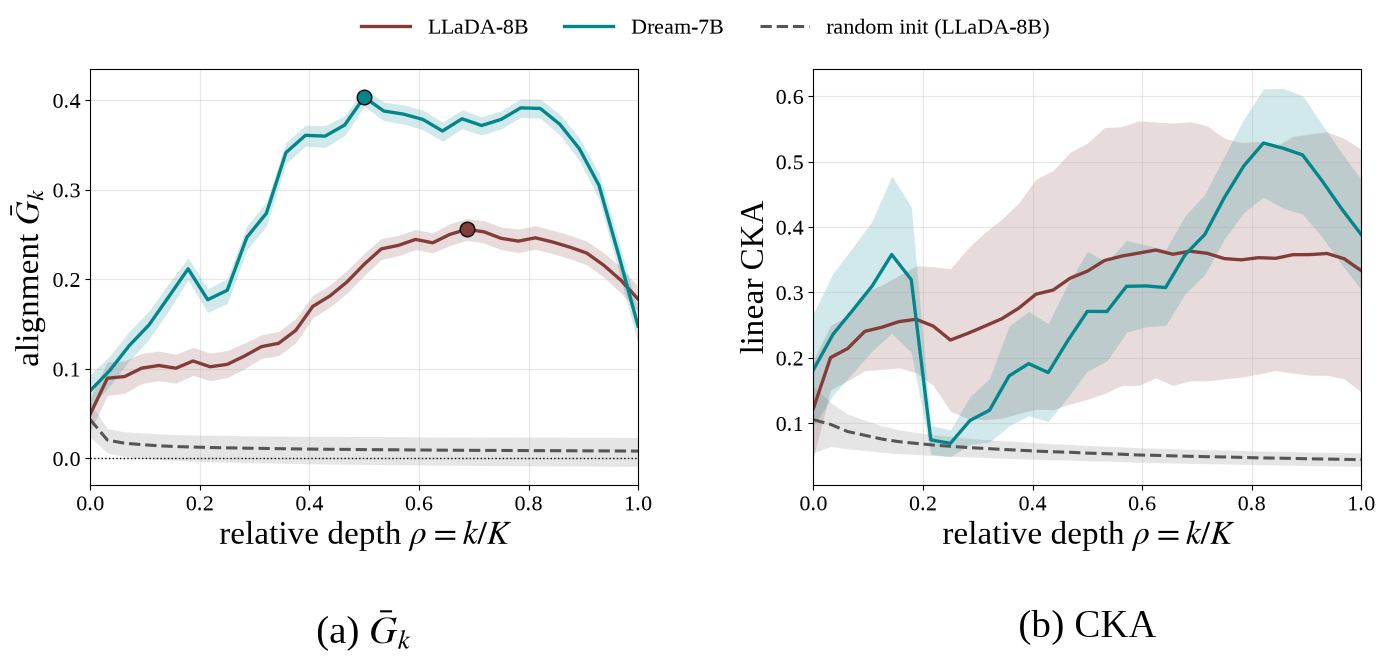

saved /mnt/cl/study1/figures/flores_diffusion_extra.pdf


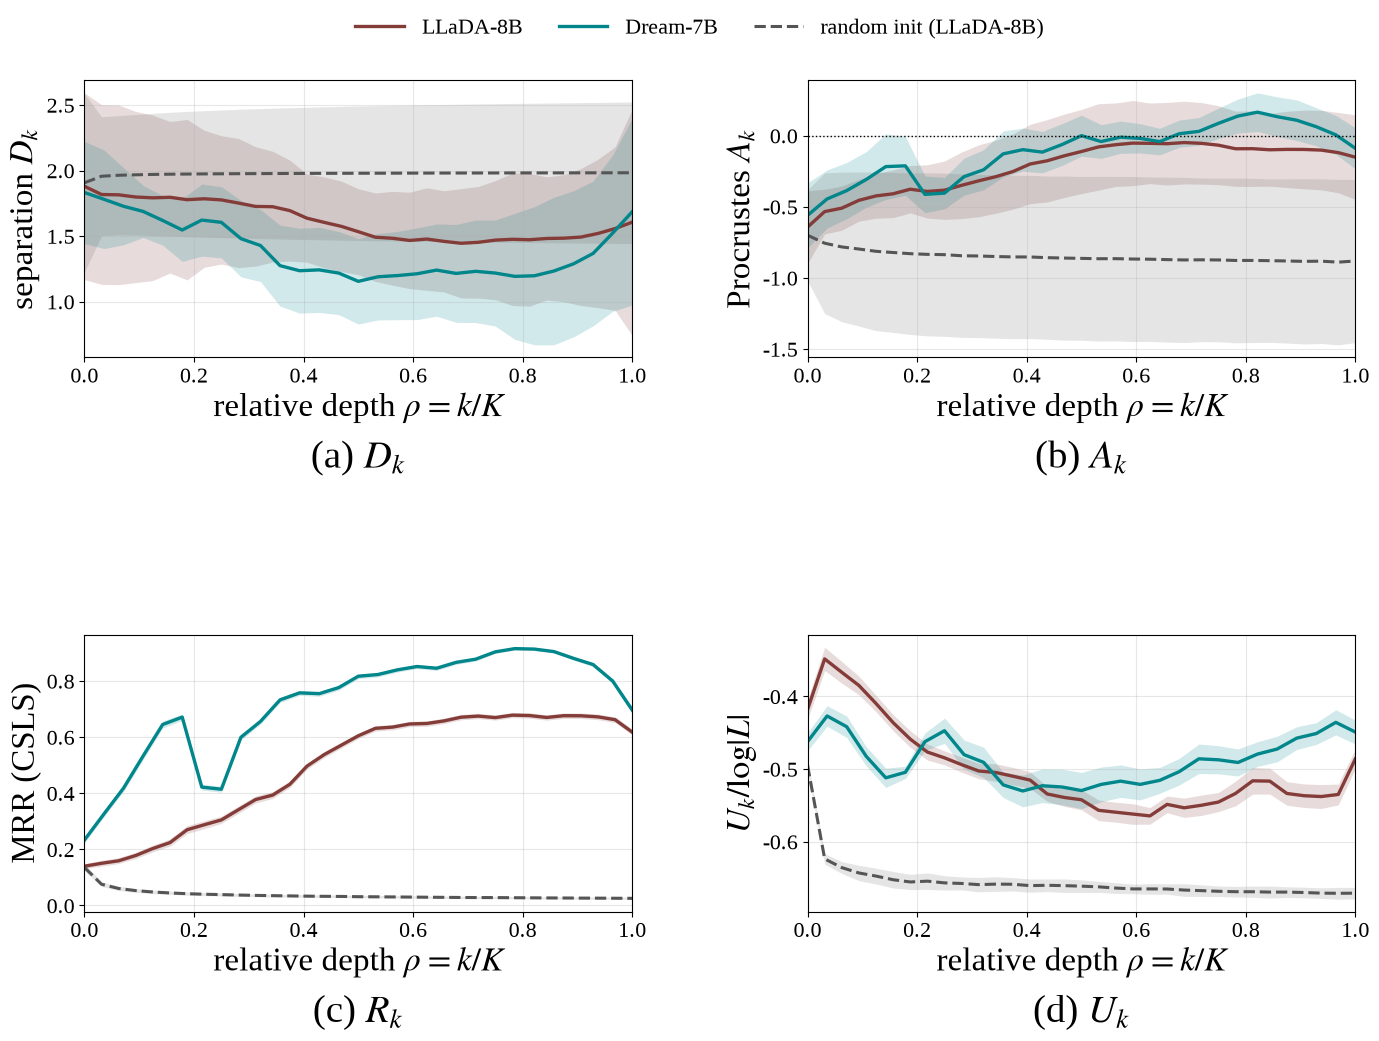

saved /mnt/cl/study1/figures/flores_stack_D-pre+r.pdf


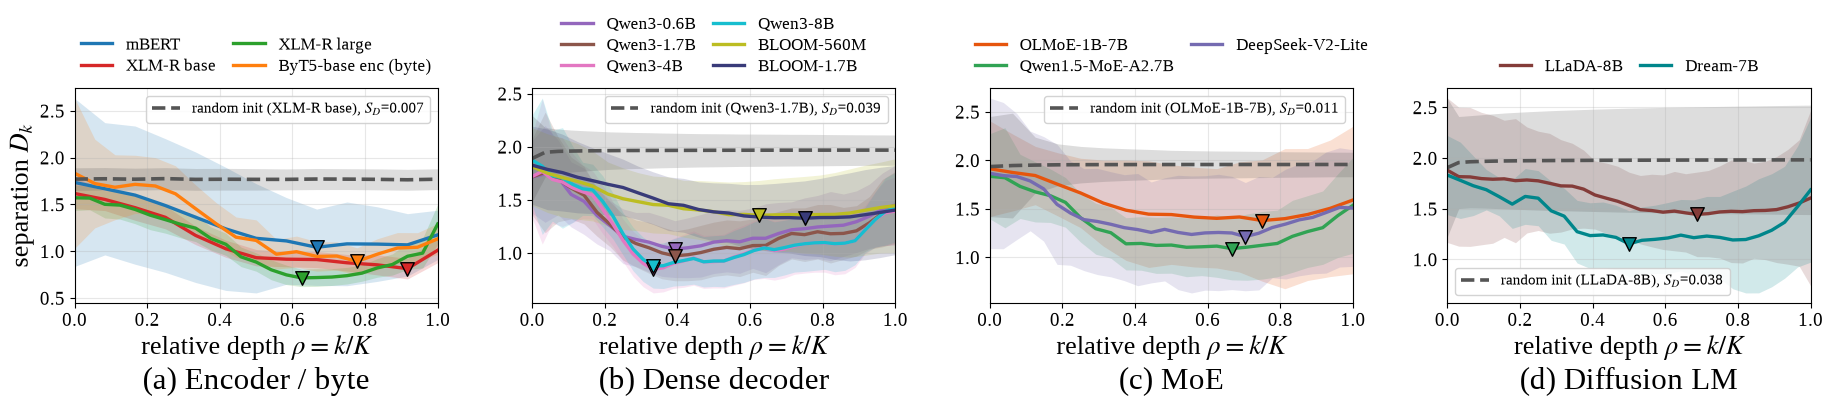

saved /mnt/cl/study1/figures/flores_moe_routing_Jk.pdf


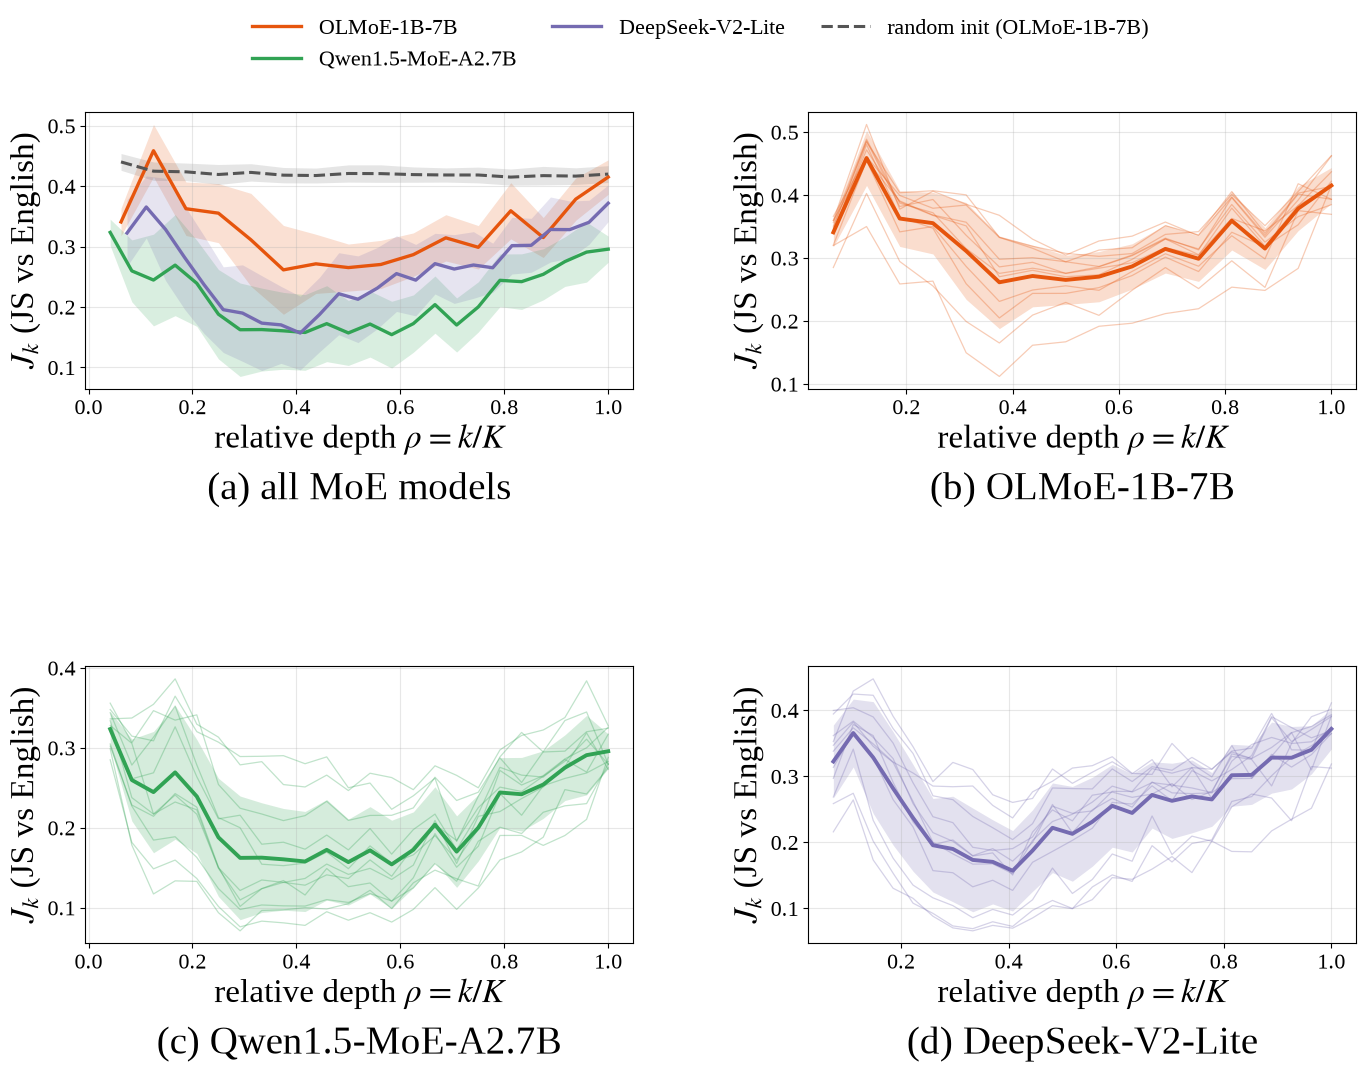

saved /mnt/cl/study1/figures/flores_diffusion_masklevels.pdf


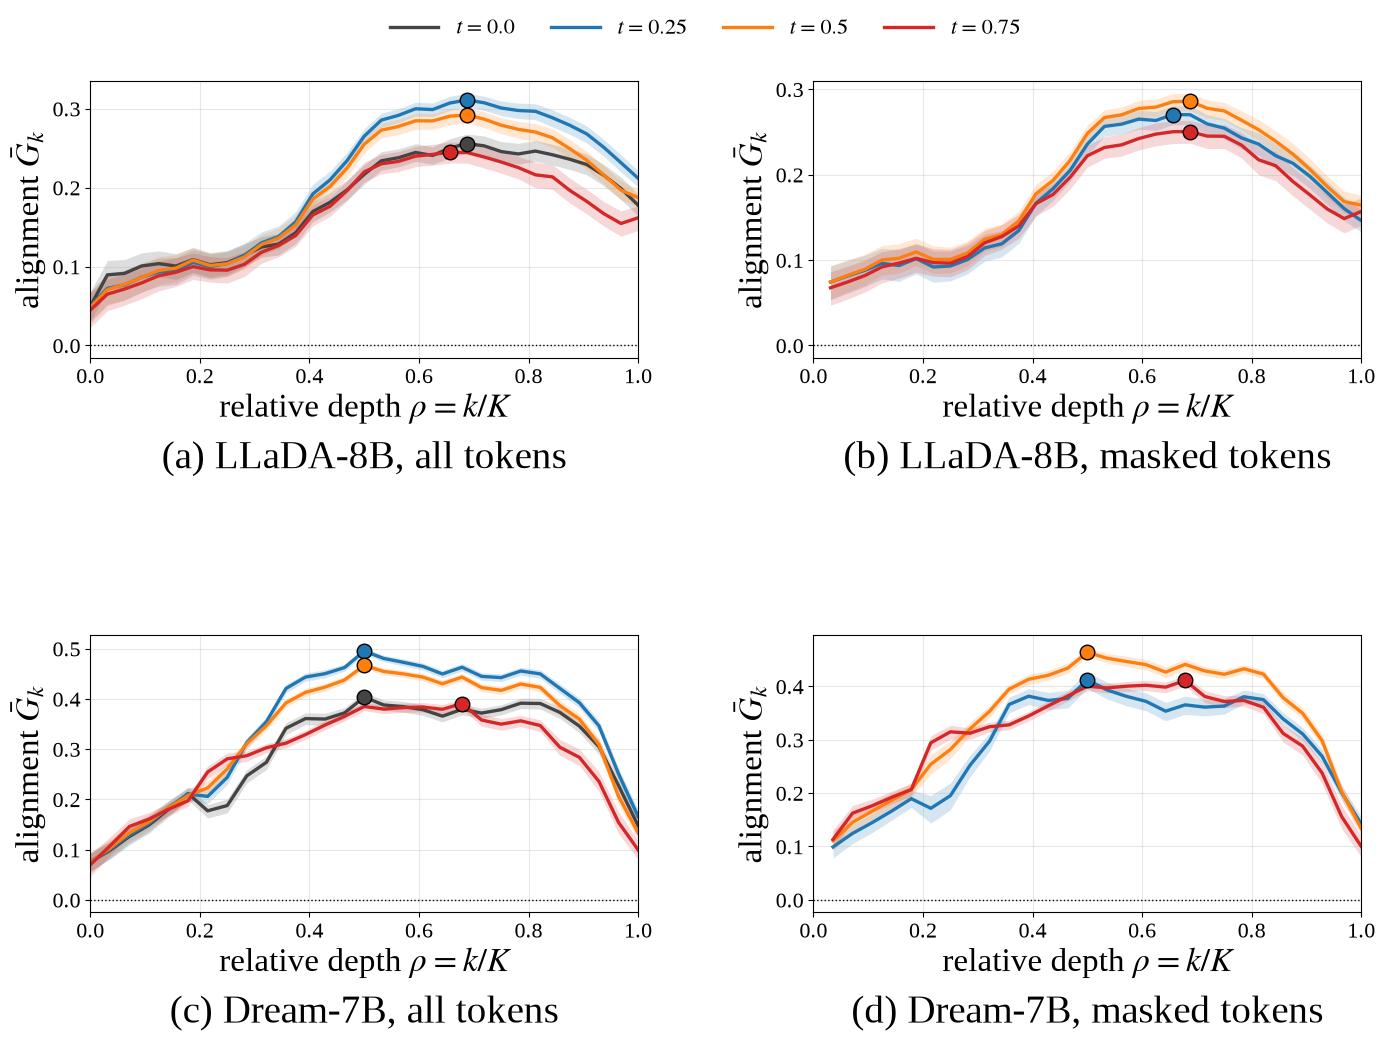

saved /mnt/cl/study1/figures/flores_waist_summary.pdf


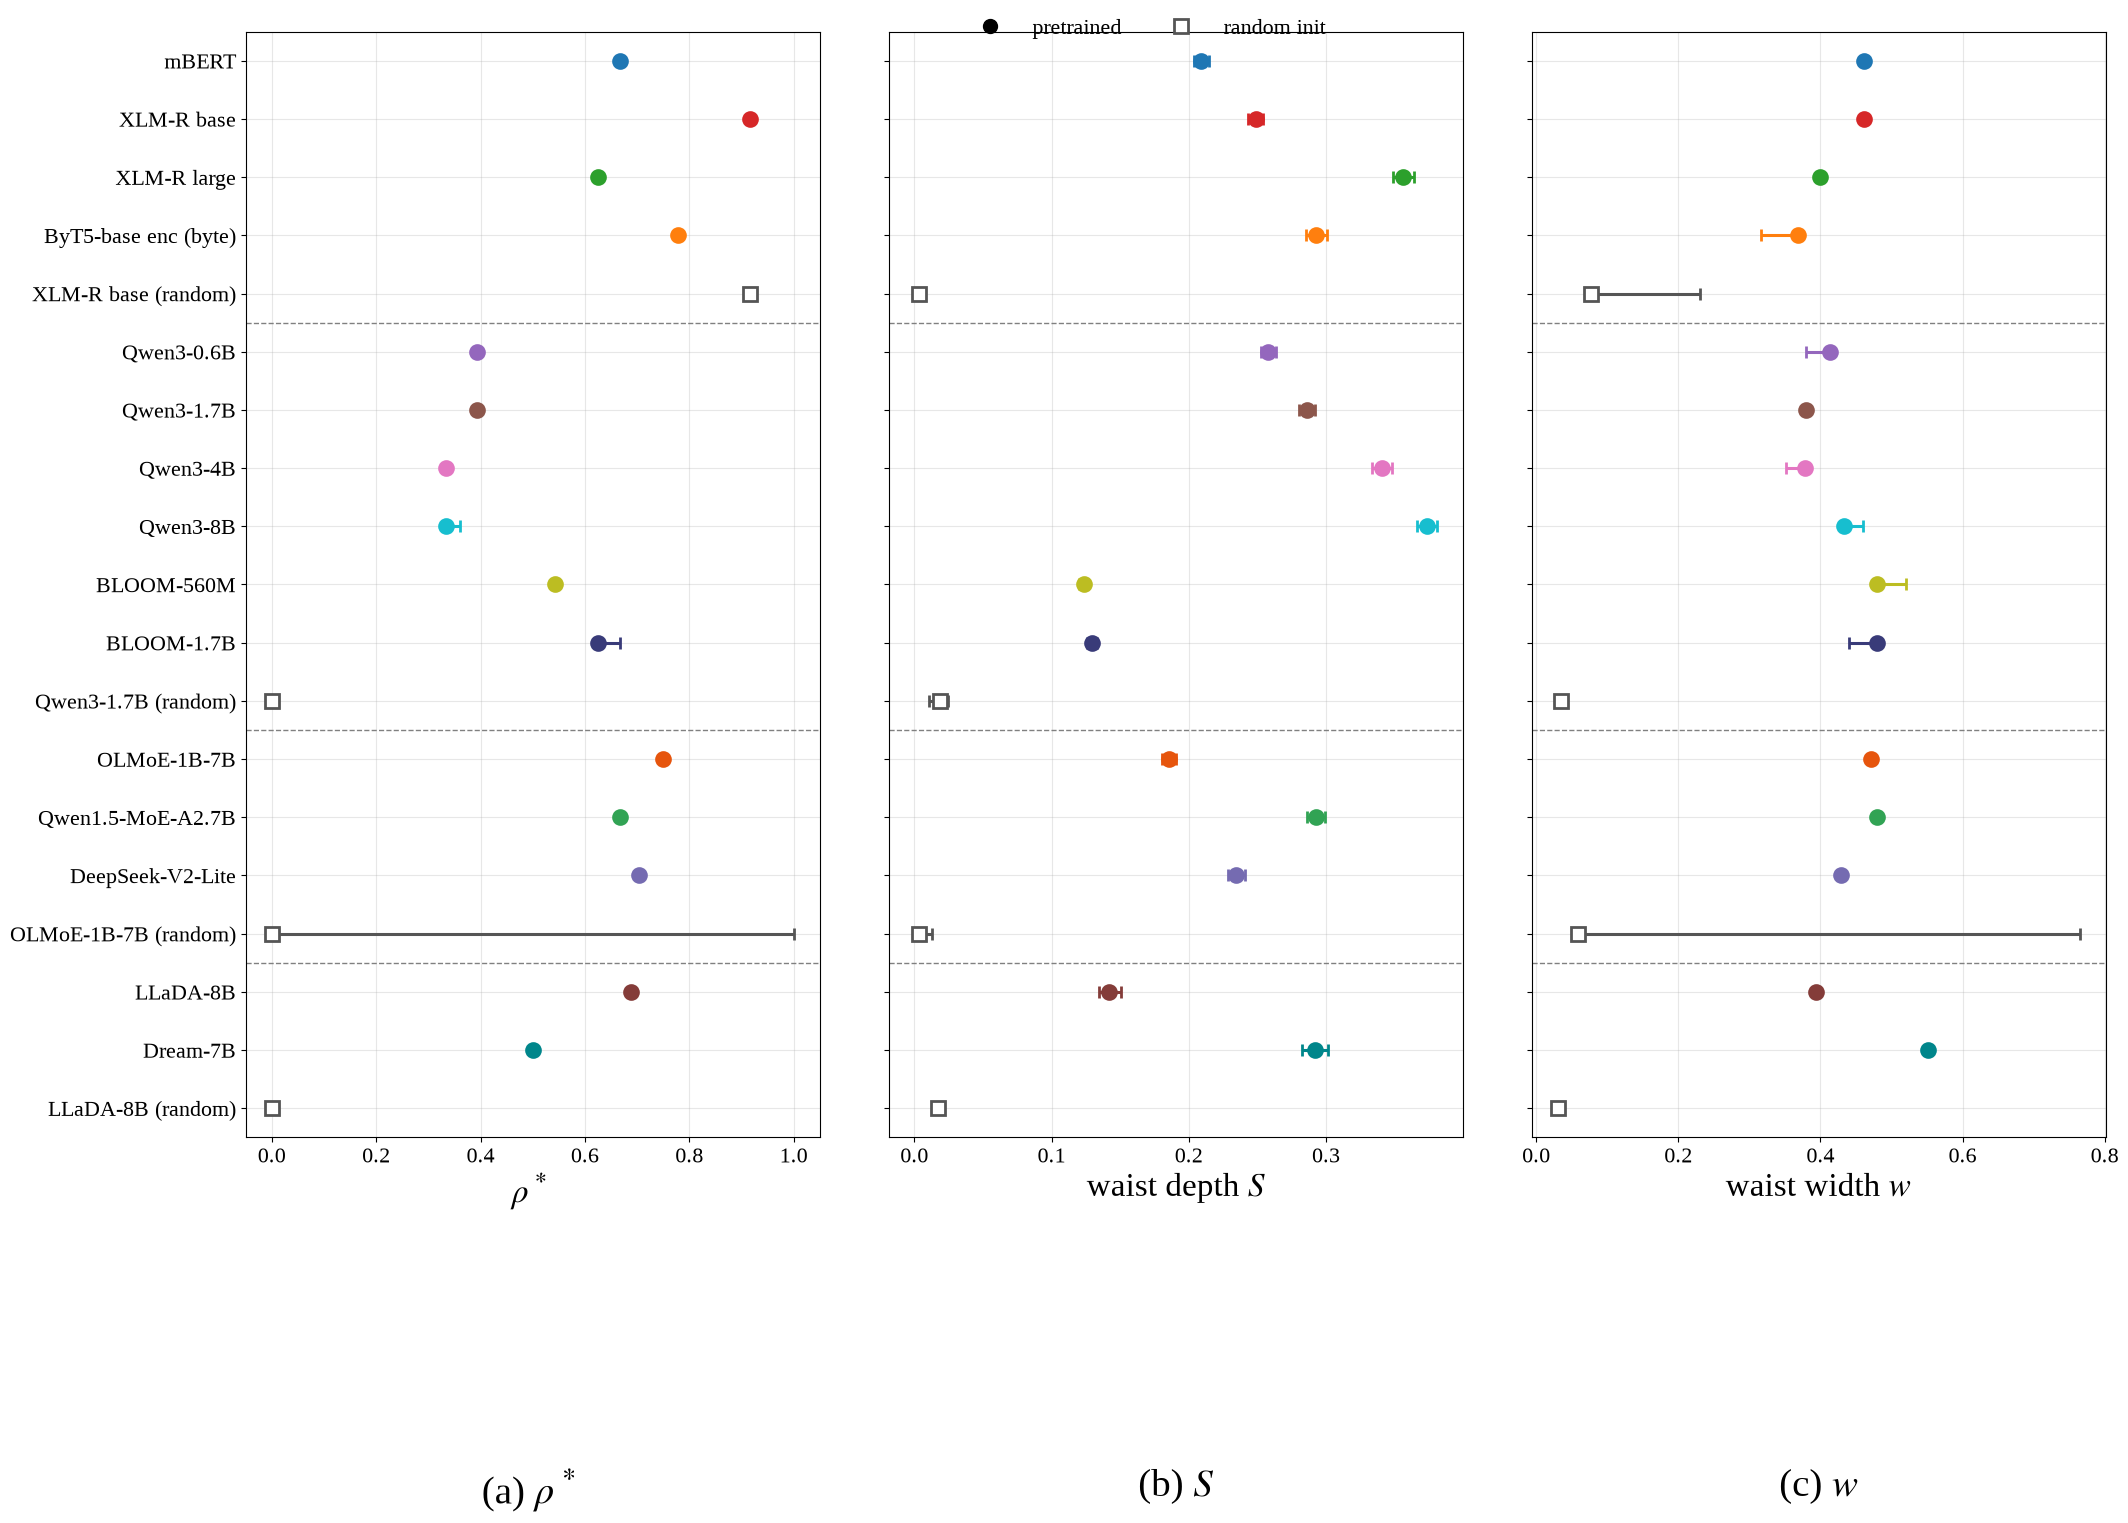

Bảng ở /mnt/cl/study1/analysis, hình PDF ở /mnt/cl/study1/figures
   family                label  k_star  rho_star     S  S_edge  S_edge_lo     w  k_star_cka  cka_in_band above_random  has_waist
  encoder           XLM-R base      11     0.917 0.206   0.084      0.082 0.462           5         True         True       True
  encoder  XLM-R base (random)      11     0.917 0.005   0.004      0.000 0.077           0        False         None      False
  decoder           Qwen3-1.7B      11     0.393 0.264   0.203      0.196 0.414           3        False         True      False
  decoder  Qwen3-1.7B (random)       0     0.000 0.010   0.000      0.000 0.034           0         True         None      False
      moe          OLMoE-1B-7B       9     0.562 0.158   0.091      0.085 0.529           7         True         True       True
      moe OLMoE-1B-7B (random)      16     1.000 0.009   0.000      0.000 0.353           1        False         None      False
diffusion             LLaDA-8B 

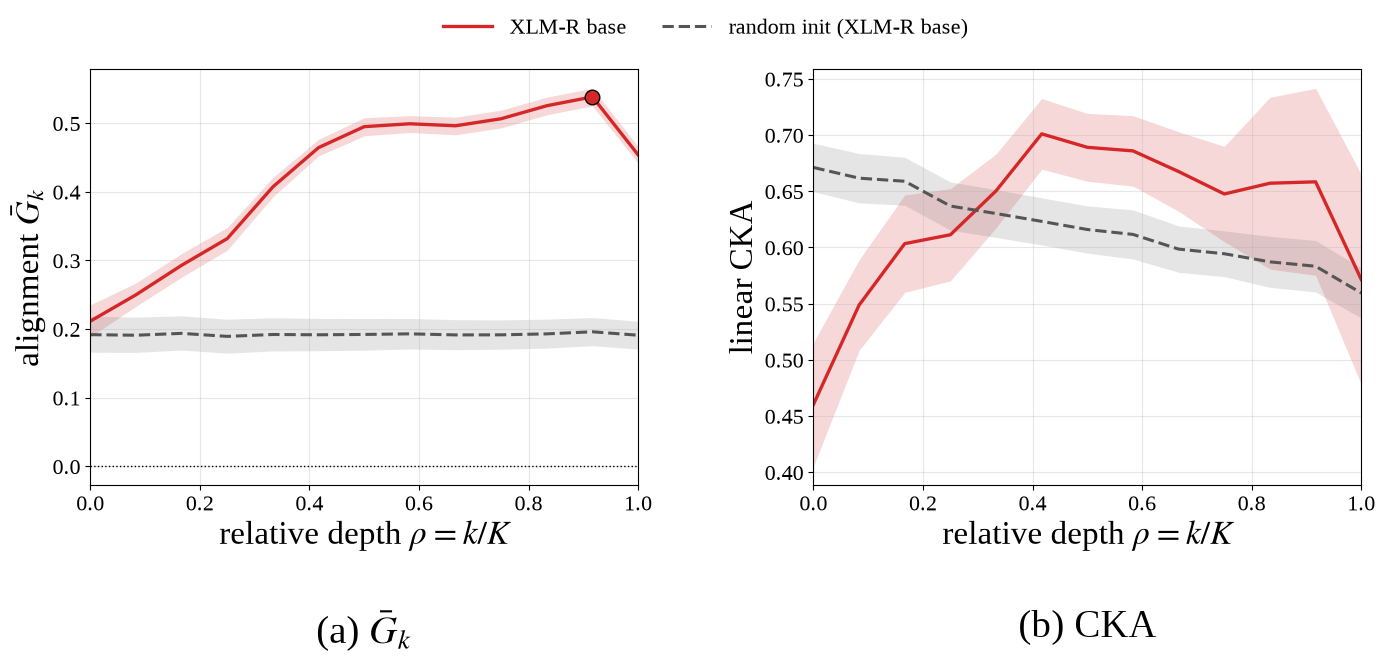

saved /mnt/cl/study1/figures/ntrex_encoder_extra.pdf


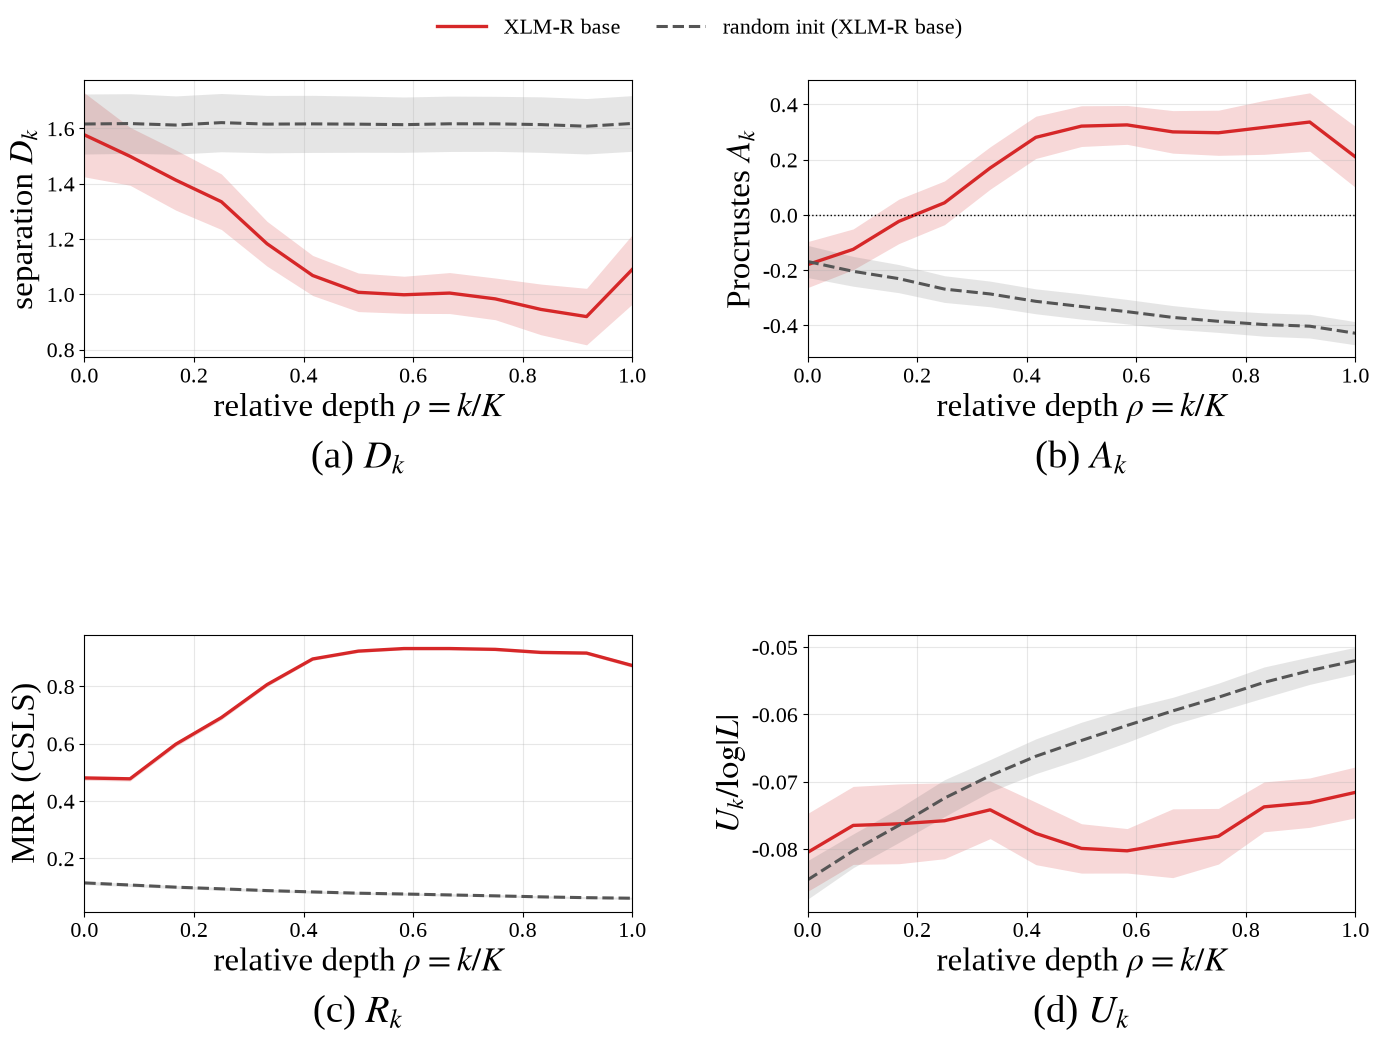

saved /mnt/cl/study1/figures/ntrex_decoder_llm_main.pdf


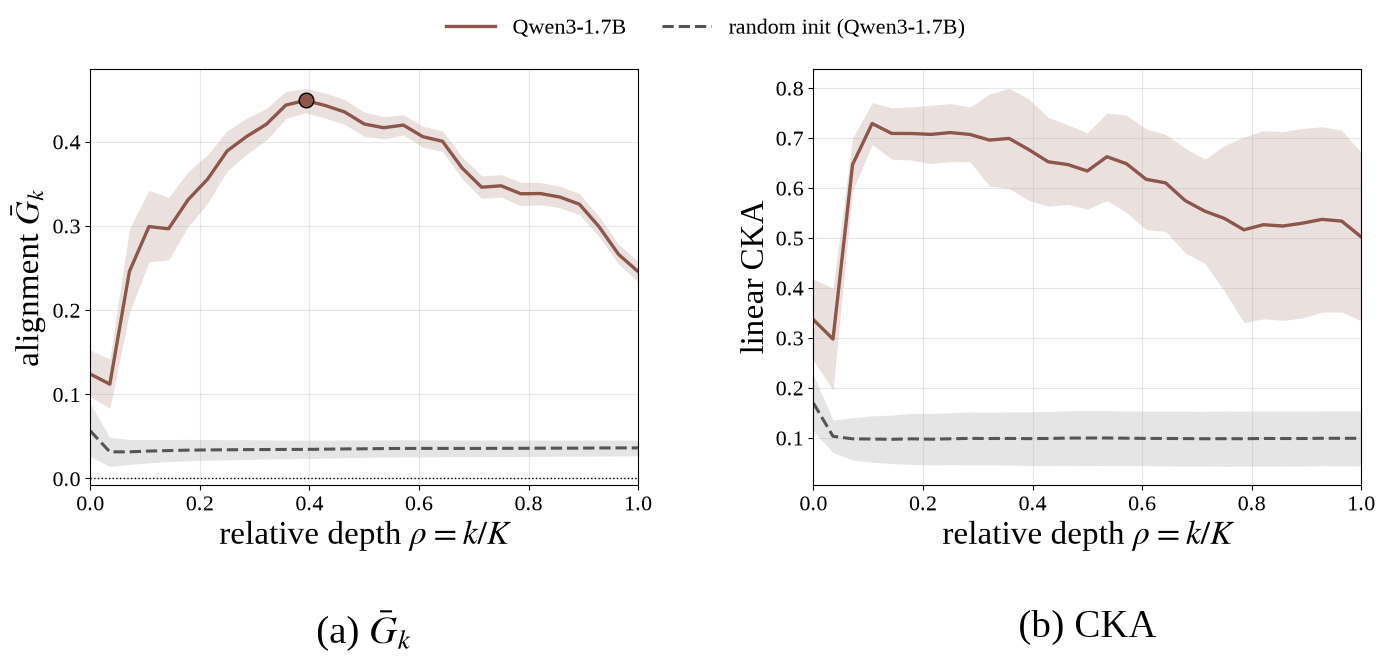

saved /mnt/cl/study1/figures/ntrex_decoder_llm_extra.pdf


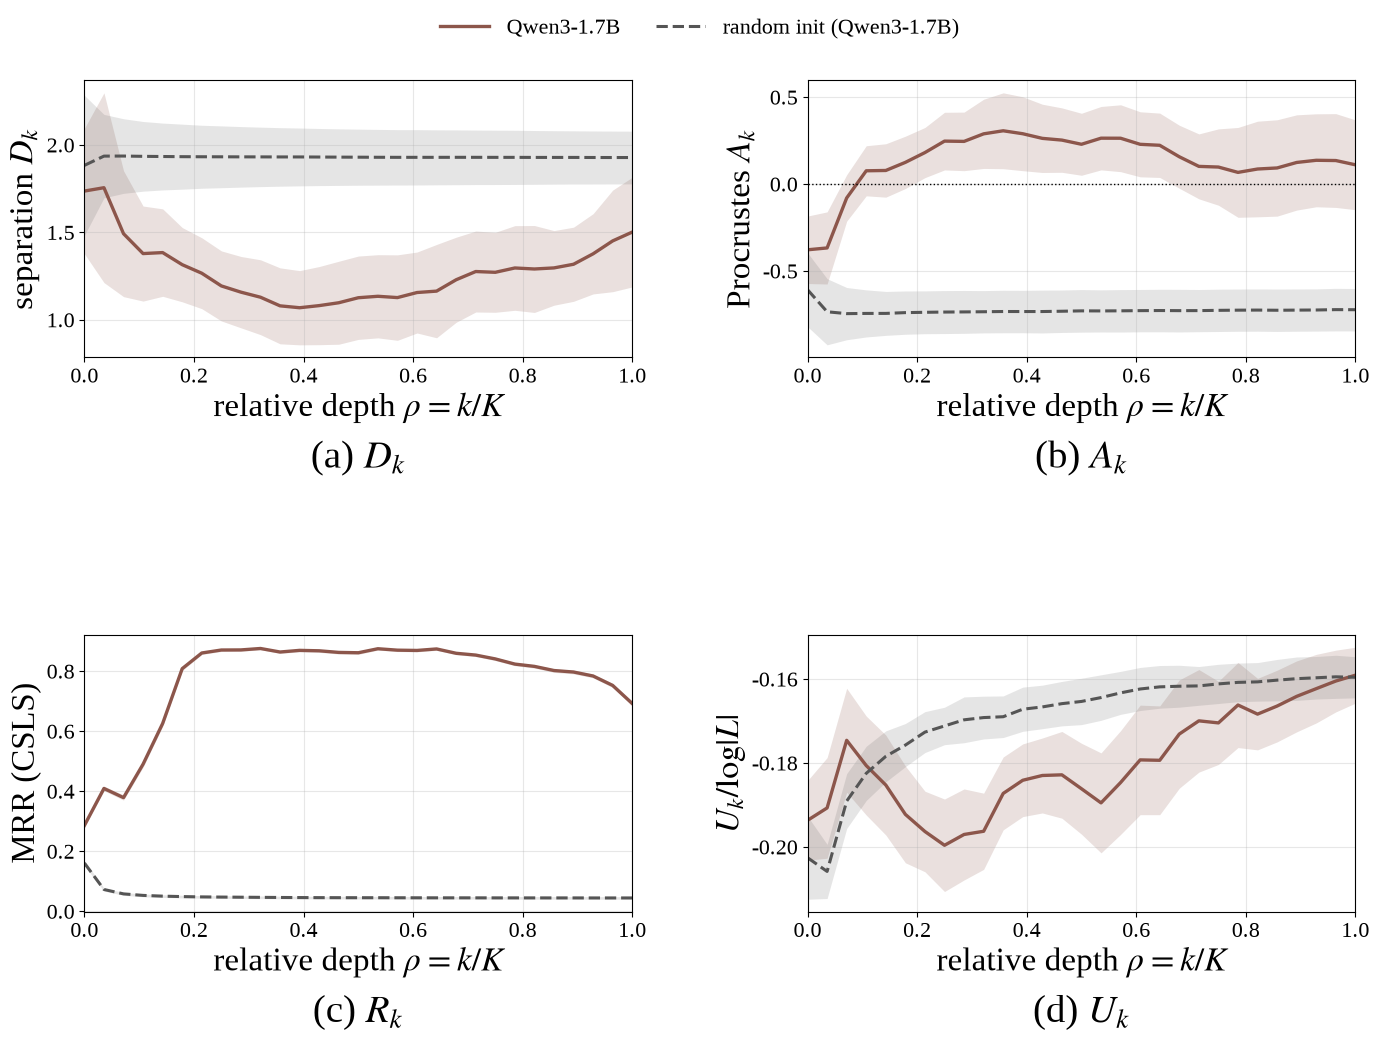

saved /mnt/cl/study1/figures/ntrex_moe_main.pdf


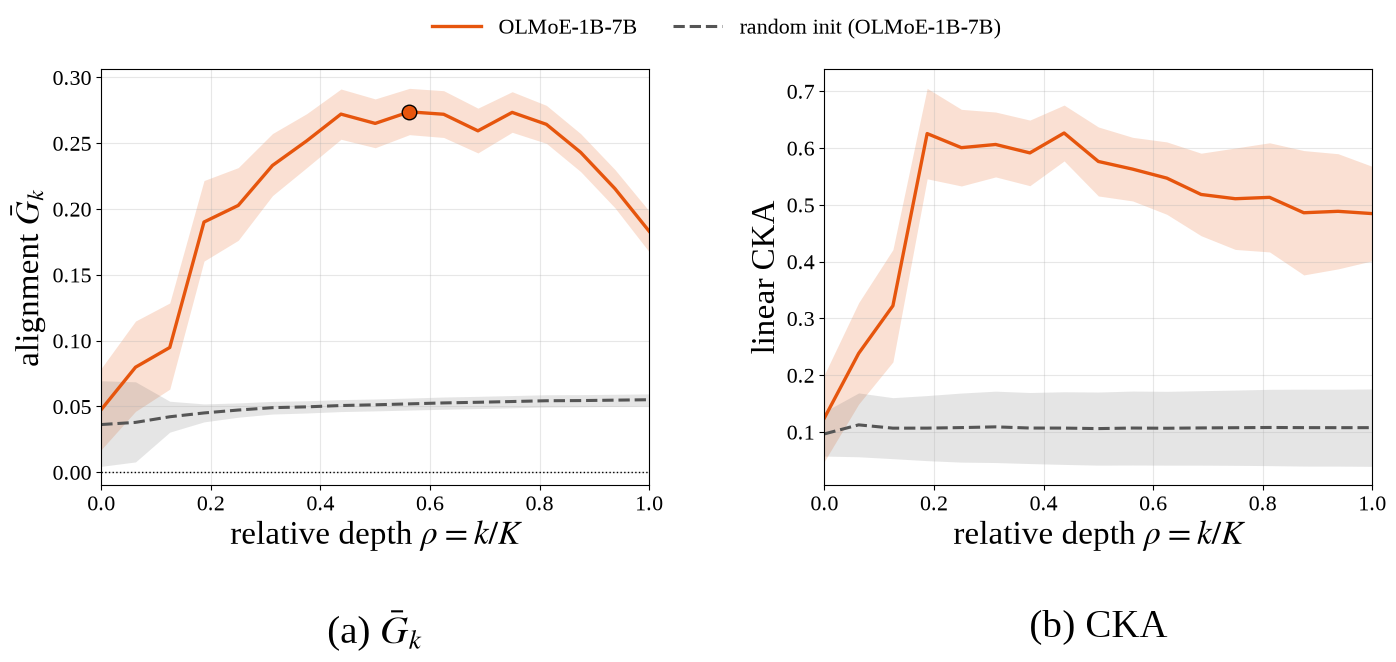

saved /mnt/cl/study1/figures/ntrex_moe_extra.pdf


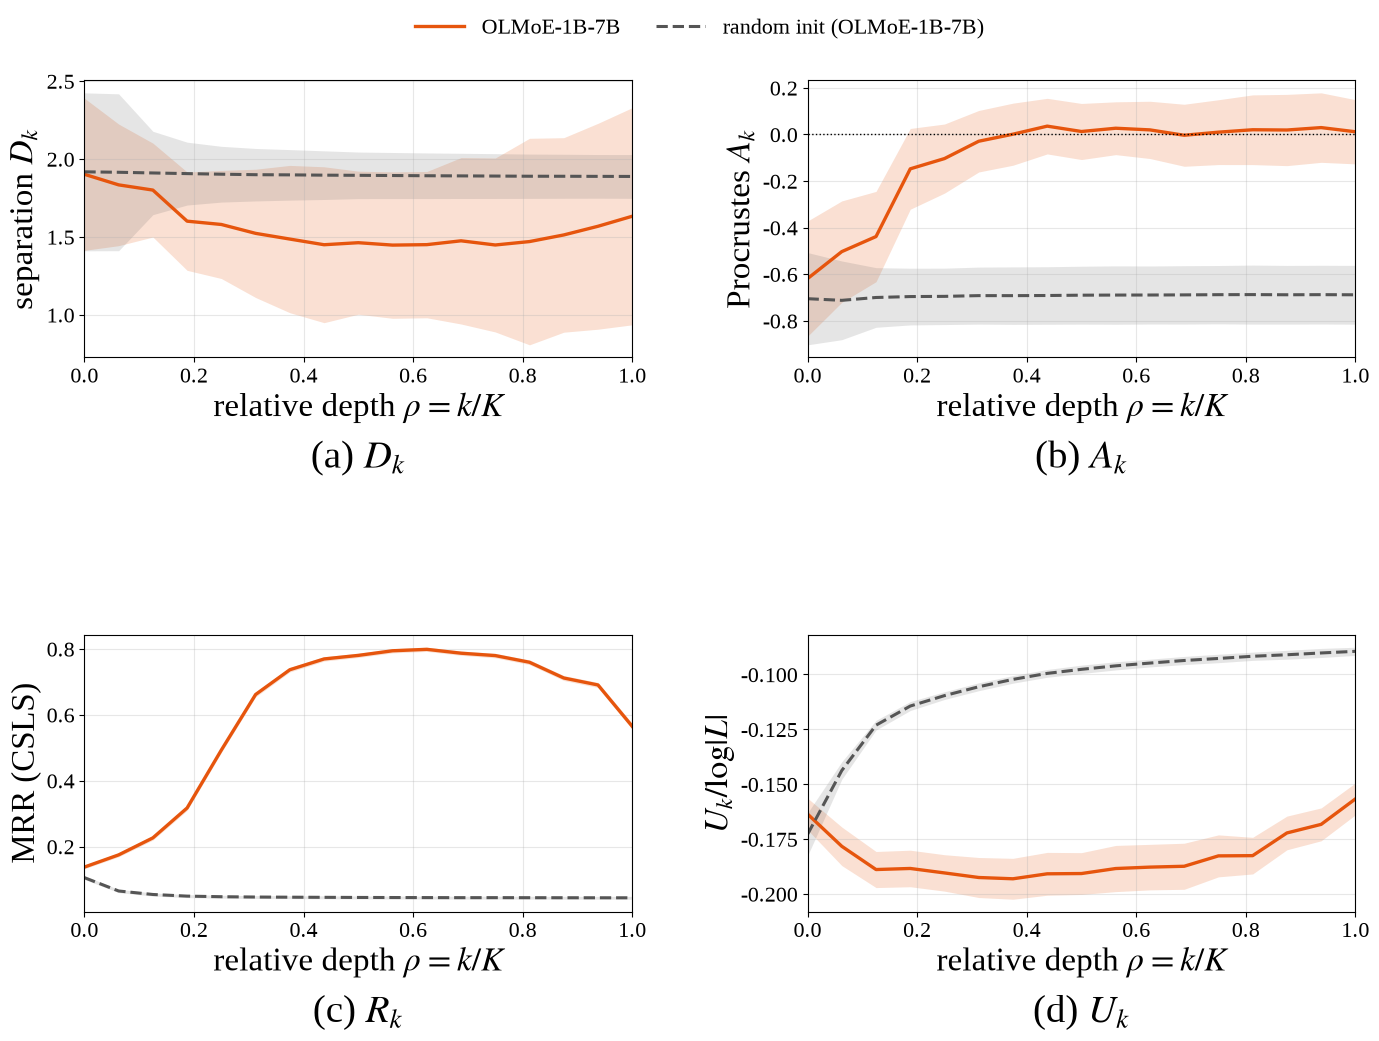

saved /mnt/cl/study1/figures/ntrex_diffusion_main.pdf


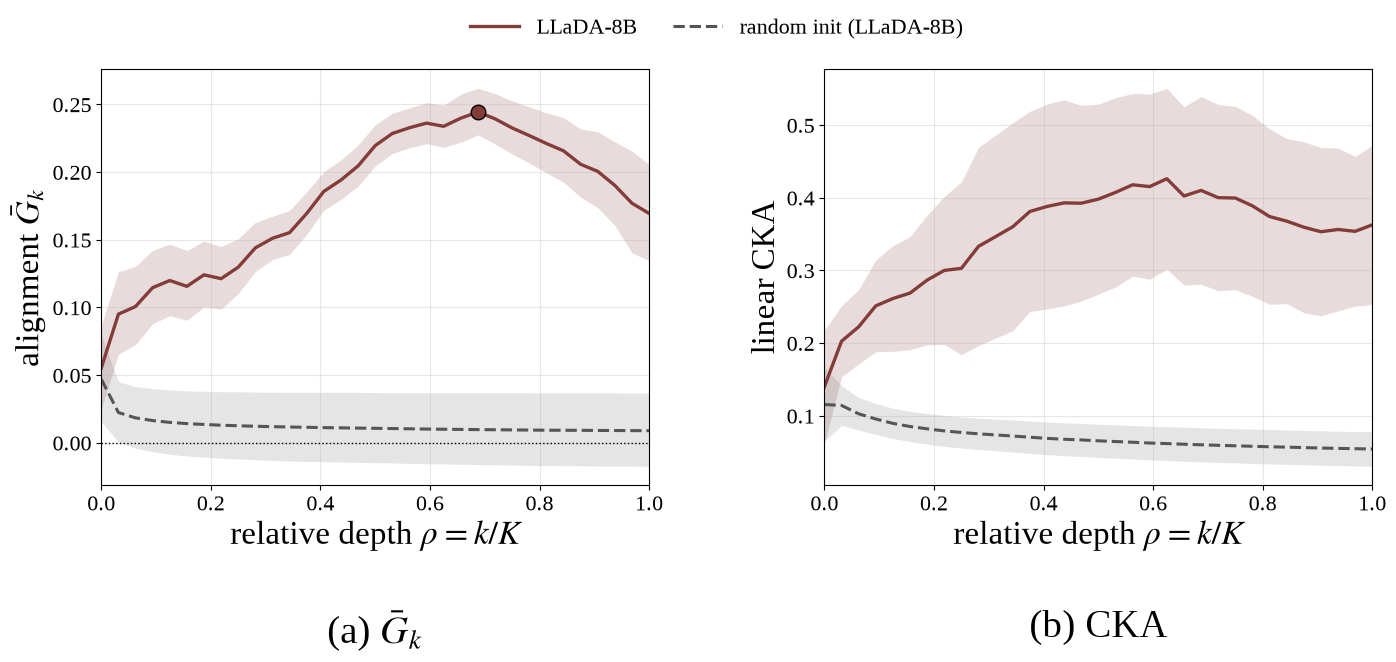

saved /mnt/cl/study1/figures/ntrex_diffusion_extra.pdf


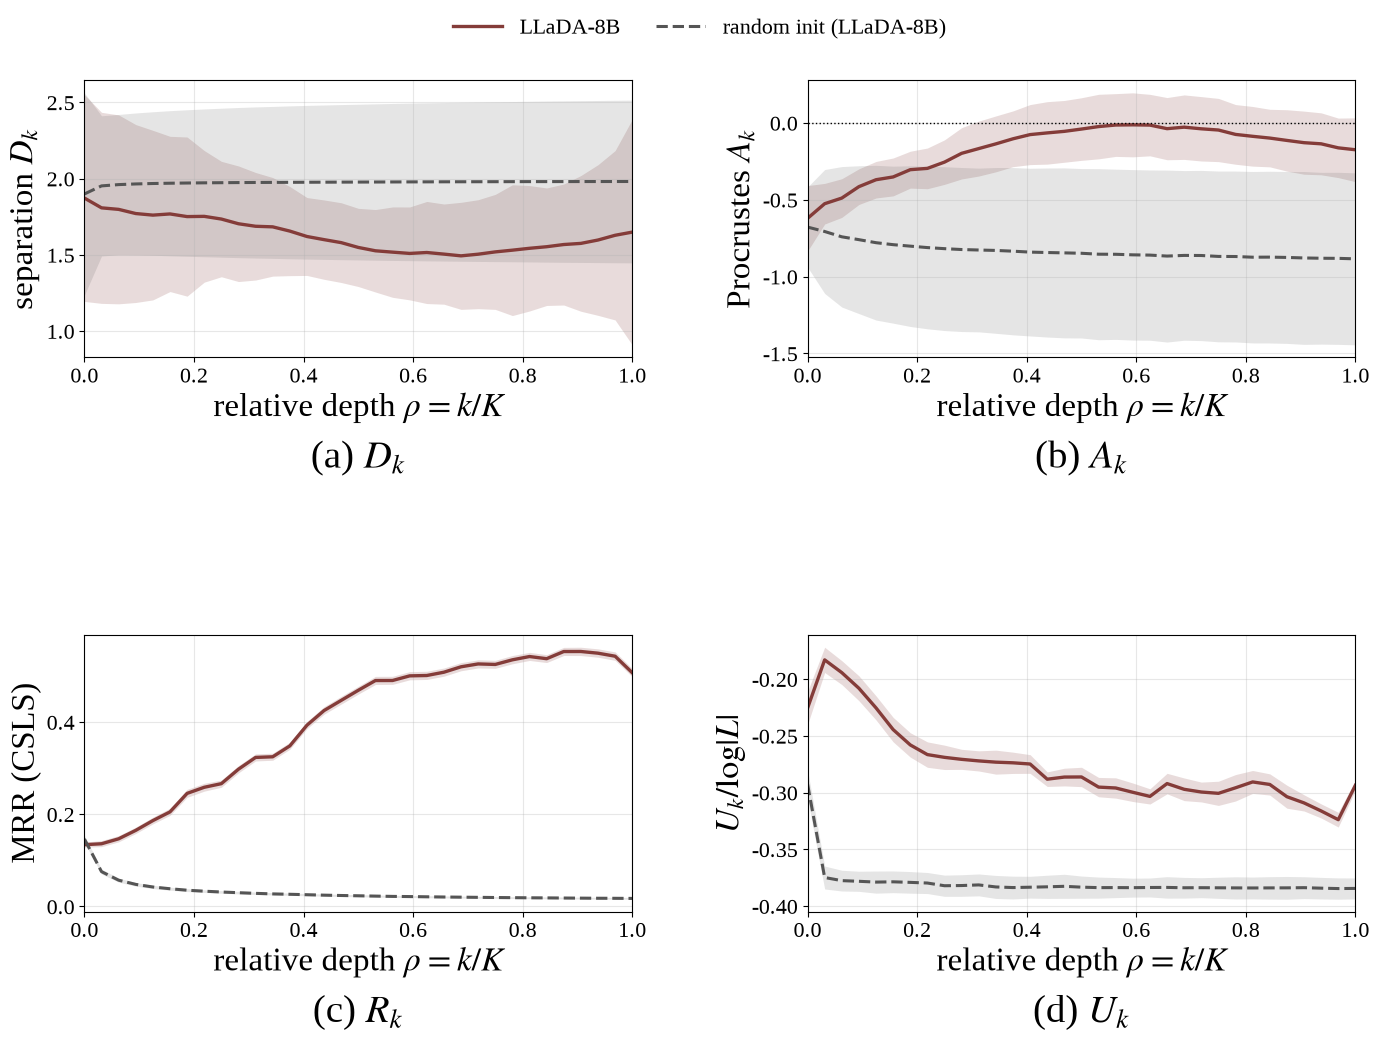

saved /mnt/cl/study1/figures/ntrex_stack_D-pre+r.pdf


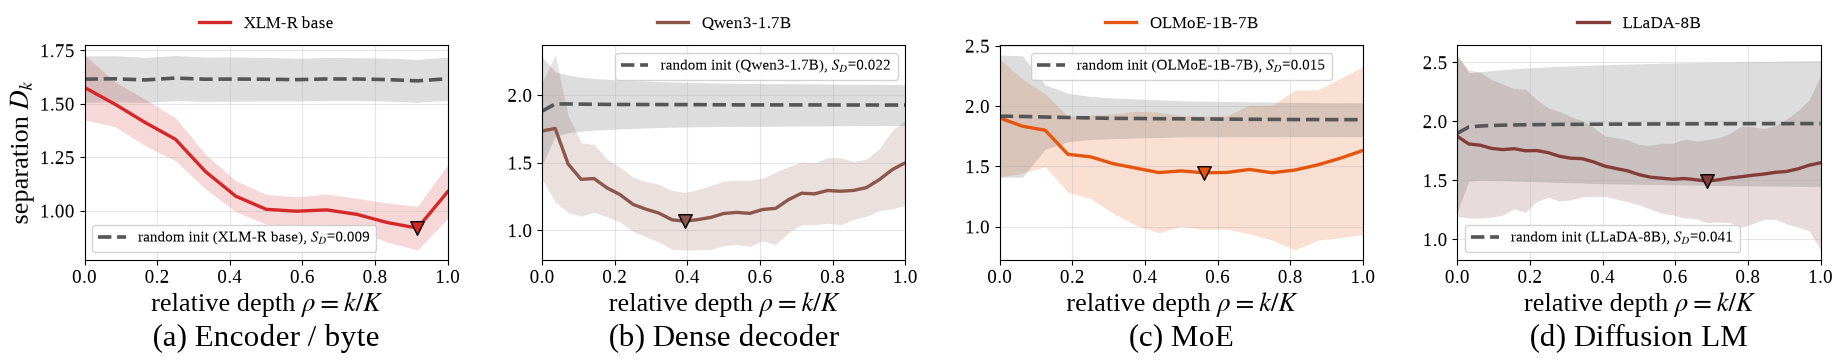

saved /mnt/cl/study1/figures/ntrex_moe_routing_Jk.pdf


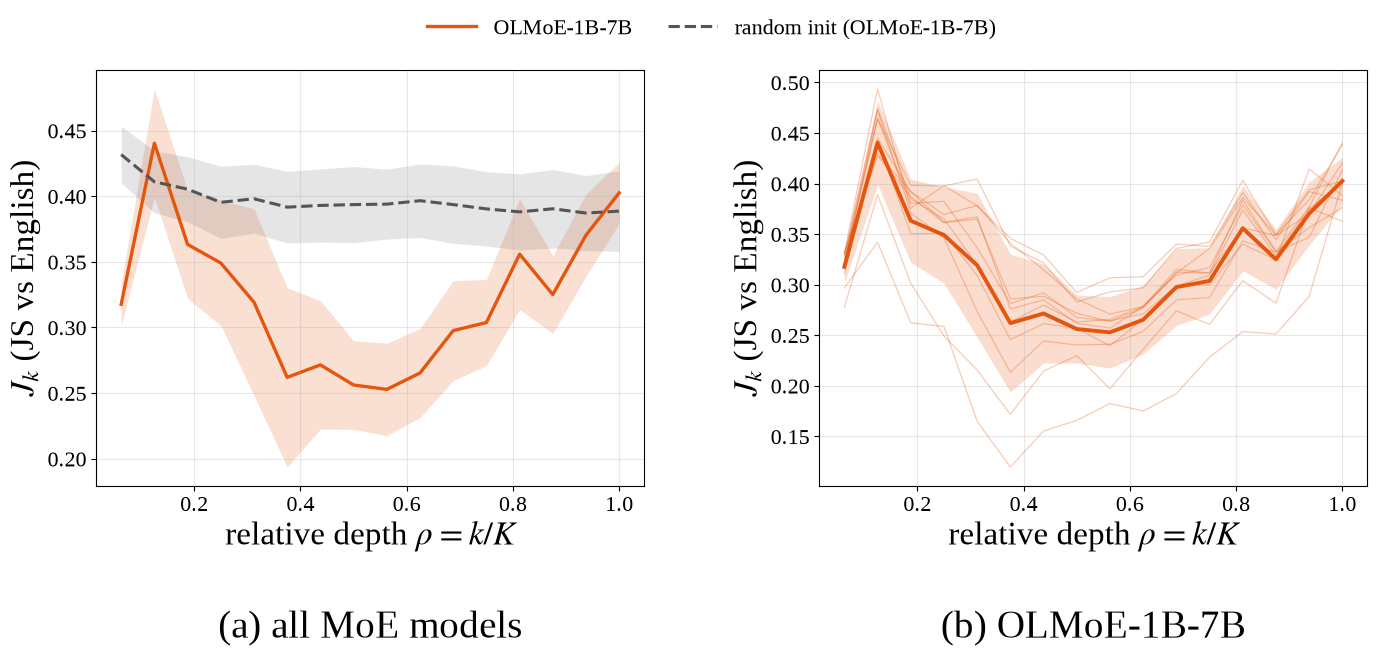

saved /mnt/cl/study1/figures/ntrex_diffusion_masklevels.pdf


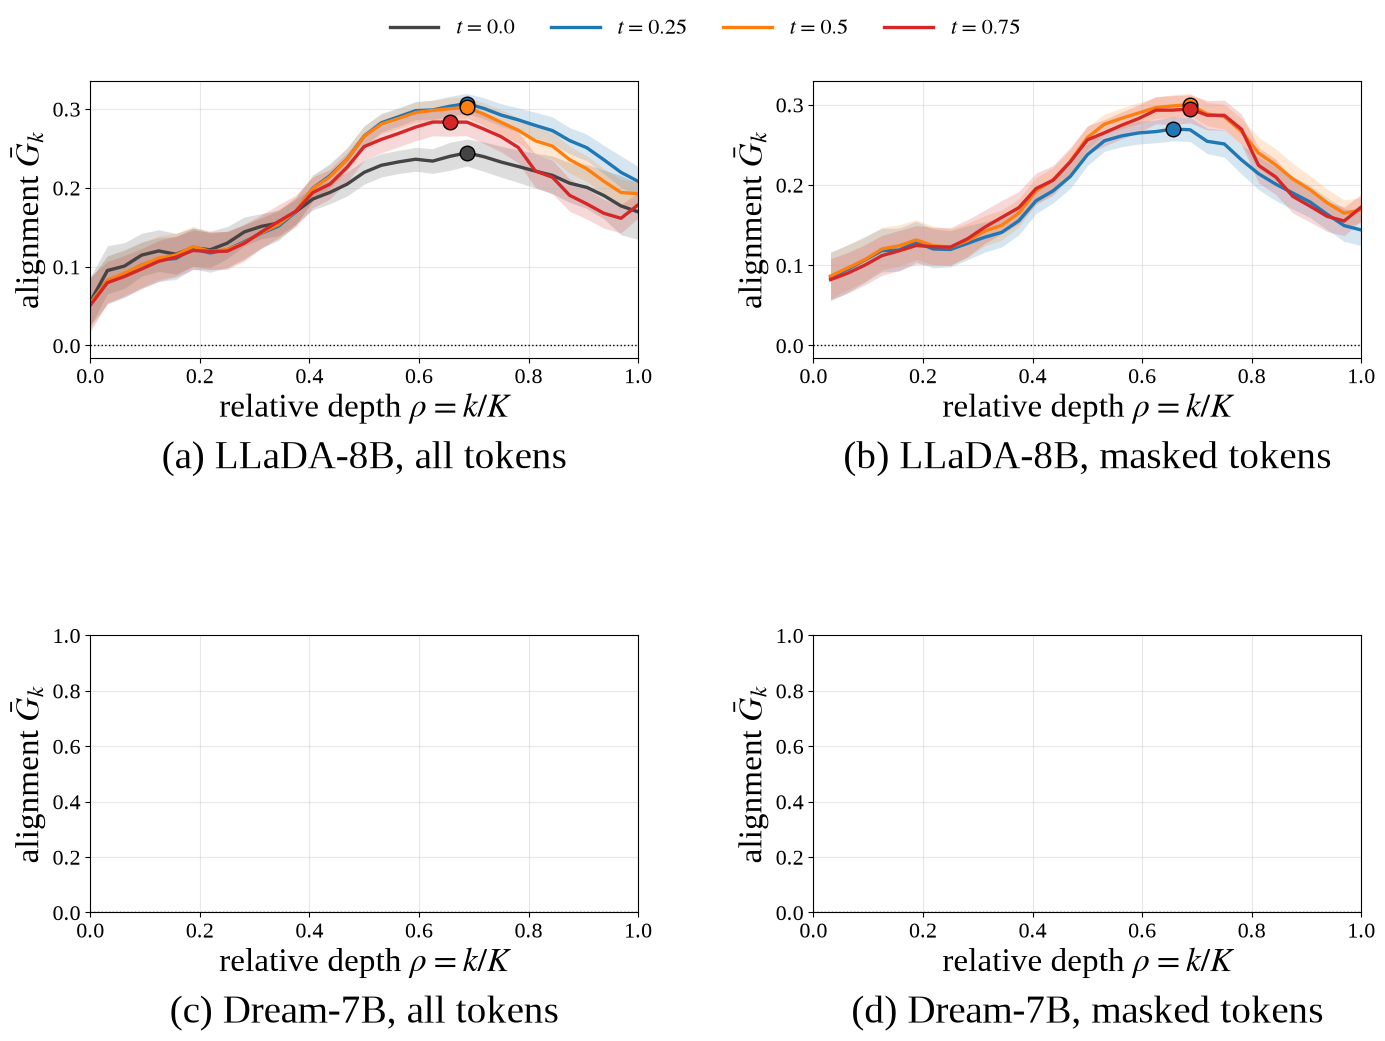

saved /mnt/cl/study1/figures/ntrex_waist_summary.pdf


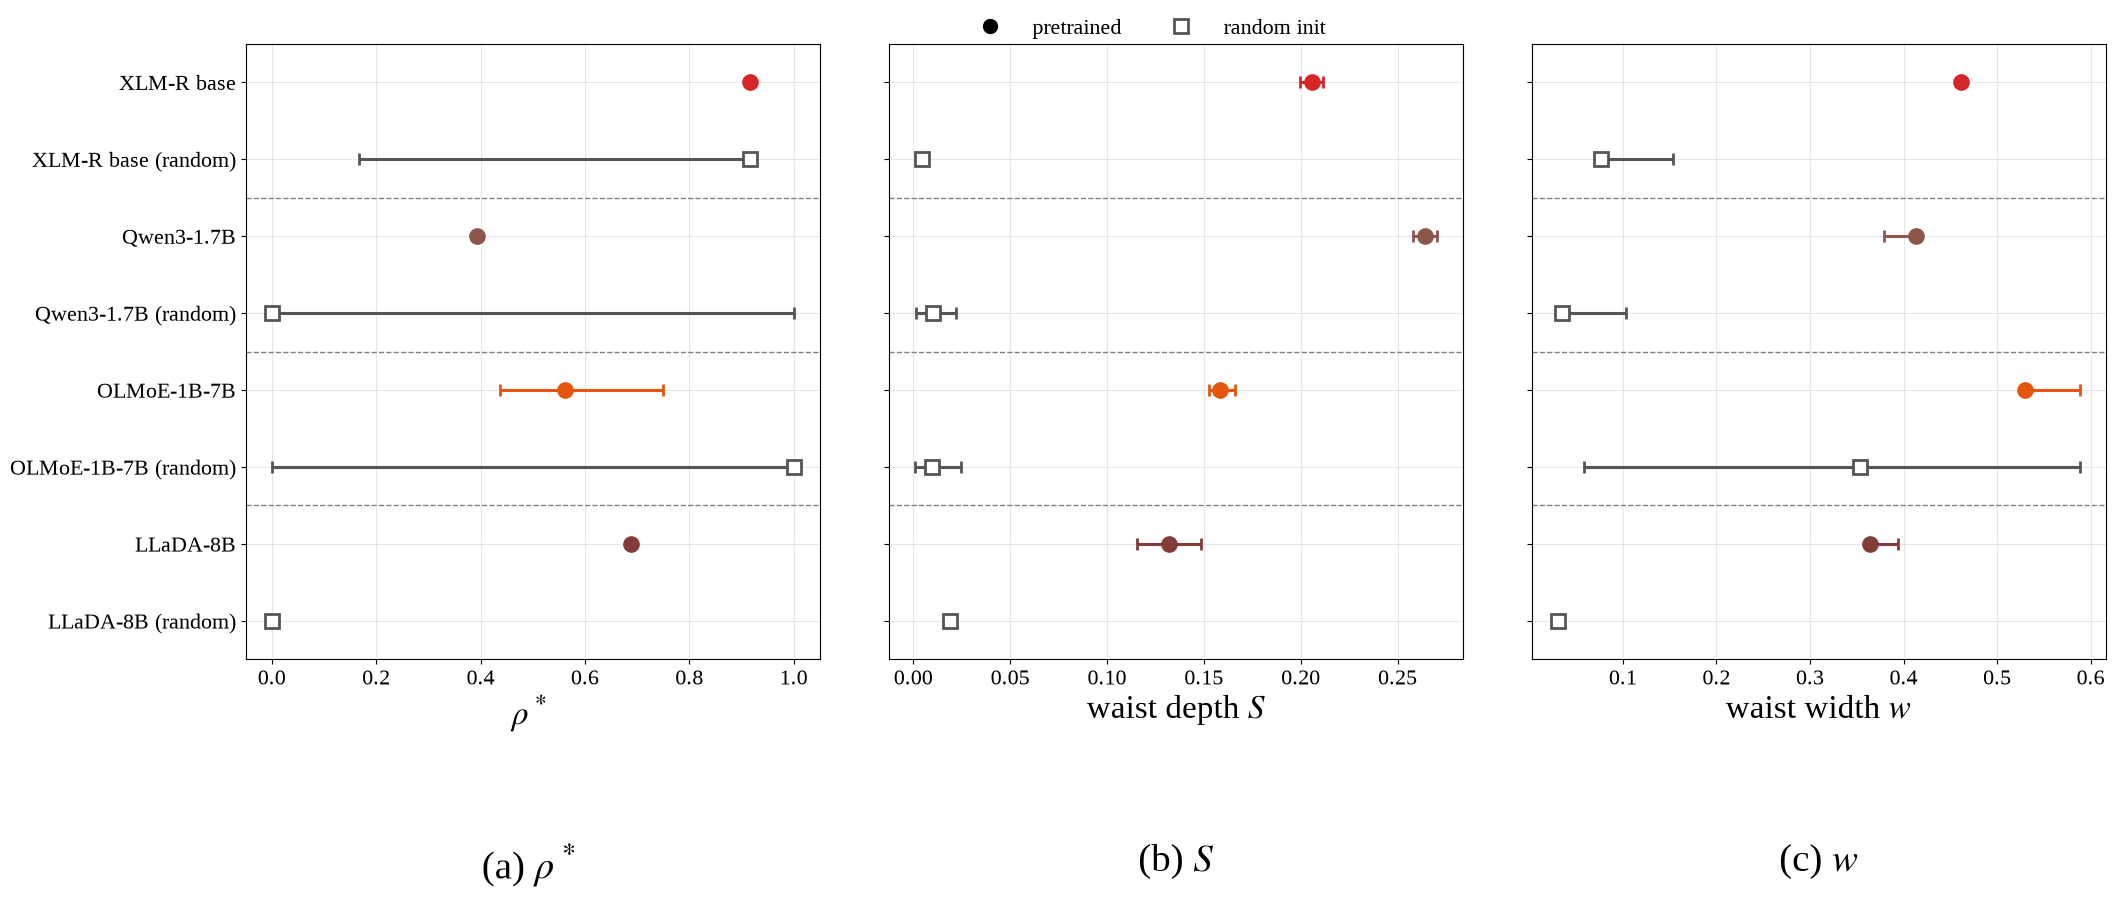

Bảng ở /mnt/cl/study1/analysis, hình PDF ở /mnt/cl/study1/figures


In [30]:
#@@@ code
# ============================================================
# Cell D7 — Tạo lại TOÀN BỘ bảng + hình từ /mnt/cl (không chạy lại model). Chạy cell này sau khi đã có kết quả,
# hoặc chạy lại bất cứ lúc nào (kể cả ở kernel mới: chỉ cần Cell A1, A2, C1 và D1–D6, D3b).
# ============================================================
def regenerate_all(ds):
    df = feature_table(ds, save=True)
    if df.empty:
        print(f"Chưa có kết quả cho {ds_tag(ds)}."); return
    print_p1_summary(df)
    diffusion_s6_table(ds, save=True)
    export_curves_csv(ds)
    for fam in FAMILIES:
        plot_family(ds, fam, "main")
        plot_family(ds, fam, "extra")
    plot_stack(ds, "D")                 # <-- mới: 2 x 4, D_k pretrained (trên) vs random-init (dưới)
    plot_moe_routing(ds)
    plot_diffusion_masklevels(ds)
    plot_summary(ds)
    print(f"Bảng ở {ANALYSIS_DIR}, hình PDF ở {FIG_DIR}")

regenerate_all("flores")

#@@@ code
regenerate_all("ntrex")

In [32]:
def refresh_router_js(ds, key, random_init=False):
    cfg = MODELS[key]; run_id = key + ("__random" if random_init else "")
    d = load_variant(ds, run_id, "base")
    texts = get_texts(ds, N_SENT)
    model, tok = load_model(cfg, random_init)
    try:
        ext = extract_level(model, tok, cfg, texts, t=None)
    finally:
        del model; gc.collect(); torch.cuda.empty_cache()
    JS, JS_raw, js_langs, rmean = router_js(ext["router"], list(texts))
    d.update(JS=JS, JS_raw=JS_raw, JS_langs=js_langs, router_mean=rmean)
    save_variant(ds, run_id, "base", d)

for k in ["olmoe", "qwen15_moe", "dsv2_lite"]:
    refresh_router_js("flores", k)
refresh_router_js("flores", "olmoe", random_init=True)   # control
# NTREX: chỉ olmoe nằm trong NTREX_MODEL_KEYS
for k in ["olmoe"]:
    refresh_router_js("ntrex", k)
refresh_router_js("ntrex", "olmoe", random_init=True)   # control


[data] flores: 1012 câu x 12 ngôn ngữ | EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
       độ dài trung bình (ký tự): {'eng': 130.4, 'fra': 155.8, 'rus': 140.4, 'hin': 129.6, 'zho': 42.8, 'vie': 137.0, 'tur': 134.2, 'arb': 114.9, 'jpn': 56.3, 'fin': 138.5, 'swh': 136.5, 'tha': 125.5}


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

...

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/3.84G [00:00<?, ?B/s]

Cancellation requested; stopping current tasks.


KeyboardInterrupt: 